# ProSit 2: Responsible Credit Scoring for Digital Micro-Lending
**ICS553 Machine Learning Essentials | NkwaPay | Kenya to Ghana transfer**

Runs top to bottom in Google Colab. Edit **only** the configuration cell (Section 0.2).

**Contents**
0. Setup, configuration, reproducibility
1. Research plan (read before running)
2. Data, feature audit, EDA
3. Feature engineering (time-safe)
4. Experimental design, cost matrix, validation integrity
5. Experiment infrastructure
6. Task 2 (default classification): models, imbalance, tuning, ablations
7. Calibration, operating threshold, final test evaluation, noise floor
8. Task 1 (loan amount regression)
9. Explainability and reason codes
10. Cross-market transfer (Kenya to Ghana)
11. Fairness and responsible-AI audit
12. Model card, compliance mapping, Findex, borrower explainer
13. Scoring service
14. Final report and reproducibility record

> **Honesty rule.** Every number is produced by code in this notebook. Interpretation cells tell you what to look for; write your own conclusions from your outputs. Per the AI-use policy, you must be able to explain and defend every step, and declare AI assistance in your report.

## 1. Research plan

### 1.1 Problem framing (ProSit Part A)
| Item | Decision |
|---|---|
| Decision moment | Loan application, just before disbursement. Closest column: `disbursement_date` (application date is not recorded). |
| Task 2 (primary) | Binary classification of `target` (1 = defaulted, 0 = repaid). Output: calibrated probability of default (PD). |
| Task 1 | Regression of `Total_Amount` (limit setting), modelled as `log1p(Total_Amount)`. |
| Label | `target` as supplied. The observation window is the loan term (`duration`, 7 to 90 days). The data dictionary does not state a grace period, so none is assumed. |
| Primary metric | **PR-AUC** (average precision). Threshold-free, honest at ~1.8% prevalence. |
| Secondary | ROC-AUC, F1/F2 at the cost-optimal threshold, MCC, balanced accuracy, Brier score, calibration, expected cost. |
| Operating point | Chosen on **calibrated dev out-of-fold** probabilities by minimising expected monetary cost (Section 4.3), never on the test set. |

### 1.2 Leakage register and safeguards
| Risk | Safeguard |
|---|---|
| Same customer in train and validation | `StratifiedGroupKFold` on `customer_id` |
| Future information (time) | Final test = most recent 20% of loans; dev loans whose `due_date` reaches into the test period are purged |
| Borrower history using outcomes not yet known | Past default counts use only loans with `due_date` strictly before the current `disbursement_date` (backward `merge_asof`, no exact matches) |
| `Total_Amount_to_Repay`, funding columns reveal `Total_Amount` | Excluded from Task 1 features |
| Learned transforms (imputer, scaler, encoder, SMOTE, selection) | Only inside sklearn/imblearn `Pipeline`s fitted on training folds |
| Test reuse | Test set scored once for the selected model plus two pre-declared references (majority baseline, reference logistic regression) |
| Train/Test.csv overlap (~4,306 customers, ~920 loans) | Quantified in Section 2; Test.csv labels never exist; overlap is handled by grouping, and Test.csv is used only for transfer analysis |
| Hyperparameter selection optimism | Tuning uses fold seed A; reported OOF uses independent fold seed B (reduces, does not eliminate, optimism) |

### 1.3 Experiments
| ID | Question | Design |
|---|---|---|
| E1 | Does naive CV overstate performance? | Stratified vs grouped vs temporal CV, side by side |
| E2 | Which model families work? | 11 models incl. majority baseline, class-weighted where applicable |
| E3 | Does imbalance handling help? | LR and LightGBM x {none, class weight, ROS, RUS, SMOTE, Borderline-SMOTE, ADASYN}; SMOTE-Tomek for LR |
| E4 | Tuned performance | Randomised search (PR-AUC, grouped folds) for LR, tree, RF, LightGBM |
| E5 | What features matter? | Cumulative and leave-one-group-out ablations |
| E6 | Is the best model meaningfully better than a simple one? | Fold-wise paired comparison and 1-SE parsimony rule (committee prefers simple models) |
| E7 | Are probabilities usable for cost decisions? | Platt vs isotonic, reliability curves, Brier, ECE |
| E8 | Does the model transfer to Ghana? | Domain classifier, PSI, KS, importance weighting, score shift |
| E9 | Is it fair? | Disaggregated metrics, parity gaps, proxy analysis, one mitigation |

### 1.4 Deliberate deviations from the generic brief
* **CatBoost and sklearn GradientBoosting** are omitted: LightGBM and XGBoost cover boosting at lower cost on Colab CPUs.
* **Sensitive attributes**: the data has no gender, age or region. Fairness uses the ProSit proxies (country, loan type, lender, tenure, loan-size band). No claims are made about gender or region.
* **Task 2 feature sets**: ProSit asks for "the same features" for both tasks. The shared set excludes loan-term columns that determine Task 1's target. Task 2 additionally uses loan terms (amount, fee), and Ablation E5 measures what they add.

## 0. Setup
### 0.1 Install and imports

Mounted at /content/drive


In [ ]:
!pip -q install imbalanced-learn lightgbm xgboost shap fairlearn

### 0.2 Configuration (the only cell you should edit)

In [ ]:
import os, sys
CFG = dict(
    # ---- paths (Google Drive when in Colab) ----
    USE_DRIVE   = True,
    DATA_DIR    = '/content/drive/MyDrive/MLE Prosit 2',          # Train.csv, Test.csv, economic_indicators.csv
    OUT_DIR     = '/content/drive/MyDrive/MLE Prosit 2/research_outputs',
    TRAIN_FILE  = 'Train.csv',
    TEST_FILE   = 'Test.csv',
    ECON_FILE   = 'economic_indicators.csv',                     # optional; skipped if absent
   # FINDEX_FILE = 'findex_ghana_2021.csv',                       # optional
    # ---- reproducibility / design ----
    SEED        = 42,
    N_FOLDS     = 5,
    TEST_FRAC   = 0.20,        # most recent 20% of loans = untouched test
    GRACE_DAYS  = 0,           # days after due_date before an outcome counts as known (history features)
    MIN_CAT_FREQ= 100,         # rarer categories are pooled into an 'infrequent' bucket
    SAMPLING_RATIO = 0.2,      # minority:majority after resampling (full 1:1 is not assumed to be better)
    TOP_Q       = 0.10,        # alert budget used for strategy-comparable metrics
    # ---- compute budget ----
    FAST        = False,       # True = tiny settings for a smoke test
    DEBUG_ROWS  = None,        # e.g. 8000 to subsample Train for a quick run
    N_ITER_TUNE = 15,
    MAX_SVC_ROWS= 15000,
    BOOT_B      = 1000,
    # ---- cost matrix ASSUMPTIONS (REPLACE with figures you justify for the Ghanaian market) ----
    RECOVERY_RATE        = 0.20,   # share of principal recovered after default (placeholder)
    COLLECTION_COST_RATE = 0.08,   # collection/servicing cost as share of principal (placeholder)
    MIN_APPROVAL_RATE    = 0.80,   # business constraint: approve at least this share of applicants
    FX_TO_GHS            = 1.0,    # multiply dataset currency by this to report in GHS (set it!)
    NOISE_FLOOR          = 0.0263, # ProSit leaderboard noise floor for F1
    FINAL_MODEL_OVERRIDE = None,   # e.g. 'lgbm' to force a model; None = rule-based selection
)
if CFG['FAST']:
    CFG.update(N_ITER_TUNE=3, MAX_SVC_ROWS=3000, BOOT_B=200, N_FOLDS=3)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and CFG['USE_DRIVE']:
    from google.colab import drive
    drive.mount('/content/drive')
def F(full, fast):  # helper: pick a compute-sized setting
    return fast if CFG['FAST'] else full

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import json, time, warnings, random, platform, shutil, importlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from scipy import stats
from scipy.special import expit, logit
from scipy.stats import loguniform, uniform
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, LogisticRegression as LR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
    confusion_matrix, f1_score, fbeta_score, matthews_corrcoef, balanced_accuracy_score, brier_score_loss,
    precision_score, recall_score, accuracy_score, mean_squared_error, mean_absolute_error)
from sklearn.calibration import calibration_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
import lightgbm as lgb, xgboost as xgb
warnings.filterwarnings('ignore')
SEED = CFG['SEED']; SEED_TUNE = SEED + 1
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.titleweight': 'bold'})
try:
    from IPython.display import display
except Exception:
    display = print

### 0.3 Output directories and helpers

In [ ]:
OUT = Path(CFG['OUT_DIR']); DATA = Path(CFG['DATA_DIR'])
_layout = {
    'ckpt_base':'checkpoints/baseline_models', 'ckpt_imb':'checkpoints/imbalance_experiments',
    'ckpt_opt':'checkpoints/optimised_models', 'ckpt_best':'checkpoints/best_models',
    'ckpt_abl':'checkpoints/ablation_models', 'ckpt_reg':'checkpoints/regression_models',
    'results':'results', 'hpo':'results/hyperparameter_results', 'data':'results/processed_data',
    'plots_eda':'plots/eda', 'plots_cmp':'plots/model_comparisons', 'plots_eval':'plots/evaluation',
    'plots_fair':'plots/fairness', 'plots_expl':'plots/explainability', 'plots_tr':'plots/transfer',
    'reports':'reports', 'code':'code'}
DIRS = {k: OUT / v for k, v in _layout.items()}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)

def savefig(fig, key, name):
    fig.savefig(DIRS[key] / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(DIRS[key] / f'{name}.pdf', bbox_inches='tight')
    plt.show()

ENV = dict(python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__,
           numpy=np.__version__, lightgbm=lgb.__version__, xgboost=xgb.__version__, seed=SEED, config=CFG)
(DIRS['reports'] / 'environment.json').write_text(json.dumps(ENV, indent=2, default=str))
print('Outputs ->', OUT)

Outputs -> /content/drive/MyDrive/MLE Prosit 2/research_outputs


### 0.4 Shared library (`credit_lib.py`)
Feature-engineering and helper code lives in one module so the **same code** runs in training and in the scoring service (this prevents train/serve skew). It is written to the working directory and copied beside the saved models.

In [ ]:
%%writefile credit_lib.py
import numpy as np, pandas as pd
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone

CAT_COLS = ['loan_type', 'lender_id', 'New_versus_Repeat']

def add_calendar(df):
    # Calendar features from the (decision-time) disbursement date and the contractual due date.
    # Rationale: repayment behaviour is linked to pay cycles and weekdays (salary at month end, weekend due dates).
    out = df.copy(); d = out['disbursement_date']
    out['disb_month'] = d.dt.month; out['disb_quarter'] = d.dt.quarter
    out['disb_dow'] = d.dt.dayofweek; out['disb_dom'] = d.dt.day
    out['disb_month_end'] = (d.dt.day >= 25).astype(int)
    due = out['due_date'] if 'due_date' in out else d + pd.to_timedelta(out['duration'], unit='D')
    out['due_dow'] = due.dt.dayofweek; out['due_weekend'] = (due.dt.dayofweek >= 5).astype(int)
    return out

def add_terms(df):
    # Loan-term features, all known at disbursement.
    #   fee_rate            = (Total_Amount_to_Repay - Total_Amount) / Total_Amount      (price of credit)
    #   daily_fee_rate      = fee_rate / duration                                         (price per day: short, dear loans are riskier)
    #   lender_funded_share = Amount_Funded_By_Lender / Total_Amount                      (skin in the game of the lender)
    #   lender_repay_share  = Lender_portion_to_be_repaid / Total_Amount_to_Repay
    out = df.copy()
    amt = out['Total_Amount'].astype(float); rep = out['Total_Amount_to_Repay'].astype(float)
    out['log_amount'] = np.log1p(amt)
    out['fee_rate'] = (rep - amt) / amt.replace(0, np.nan)
    out['daily_fee_rate'] = out['fee_rate'] / out['duration'].clip(lower=1)
    out['lender_funded_share'] = out['Amount_Funded_By_Lender'] / amt.replace(0, np.nan)
    out['lender_repay_share'] = out['Lender_portion_to_be_repaid'] / rep.replace(0, np.nan)
    return out.replace([np.inf, -np.inf], np.nan)

HIST_COLS = ['n_prior_loans', 'no_prior_loans', 'days_since_last_loan', 'prior_mean_amount', 'last_amount',
             'n_resolved_prior', 'n_prior_defaults', 'prior_default_rate']

def add_history(df, labelled, grace_days=0):
    # Time-safe borrower history via backward merge_asof with allow_exact_matches=False.
    #  (a) activity: loans disbursed strictly BEFORE the current one (needs no labels)
    #  (b) outcomes: loans whose due_date (+grace) is strictly BEFORE the current disbursement, i.e. outcome already observable.
    #      A prior loan that is still running is NOT counted, which prevents label leakage from the future.
    base = df[['customer_id', 'disbursement_date']].copy(); base['_row'] = np.arange(len(base))
    base = base.sort_values('disbursement_date', kind='mergesort')
    a = labelled[['customer_id', 'disbursement_date', 'Total_Amount']].sort_values('disbursement_date', kind='mergesort').copy()
    a['n_prior_loans'] = a.groupby('customer_id').cumcount() + 1
    a['prior_mean_amount'] = a.groupby('customer_id')['Total_Amount'].cumsum() / a['n_prior_loans']
    a['last_loan_date'] = a['disbursement_date']; a['last_amount'] = a['Total_Amount']
    a = a.rename(columns={'disbursement_date': '_a_date'})[['customer_id', '_a_date', 'n_prior_loans', 'prior_mean_amount', 'last_loan_date', 'last_amount']]
    m = pd.merge_asof(base, a, left_on='disbursement_date', right_on='_a_date', by='customer_id',
                      direction='backward', allow_exact_matches=False)
    b = labelled[['customer_id', 'due_date', 'target']].dropna().copy()
    b['_b_date'] = b['due_date'] + pd.to_timedelta(grace_days, unit='D')
    b = b.sort_values('_b_date', kind='mergesort')
    b['n_resolved_prior'] = b.groupby('customer_id').cumcount() + 1
    b['n_prior_defaults'] = b.groupby('customer_id')['target'].cumsum()
    m = pd.merge_asof(m.sort_values('disbursement_date', kind='mergesort'),
                      b[['customer_id', '_b_date', 'n_resolved_prior', 'n_prior_defaults']],
                      left_on='disbursement_date', right_on='_b_date', by='customer_id',
                      direction='backward', allow_exact_matches=False)
    m = m.sort_values('_row')
    out = df.copy()
    for c in ['n_prior_loans', 'n_resolved_prior', 'n_prior_defaults']:
        out[c] = m[c].fillna(0).values
    out['no_prior_loans'] = (out['n_prior_loans'] == 0).astype(int)
    out['days_since_last_loan'] = (m['disbursement_date'] - m['last_loan_date']).dt.days.values
    out['prior_mean_amount'] = m['prior_mean_amount'].values
    out['last_amount'] = m['last_amount'].values
    out['prior_default_rate'] = np.where(out['n_resolved_prior'] > 0, out['n_prior_defaults'] / out['n_resolved_prior'].clip(lower=1), 0.0)
    if 'Total_Amount' in out:   # relative loan size vs the borrower's own past (terms feature, Task 2 only)
        out['amount_vs_prior_mean'] = (out['Total_Amount'] / out['prior_mean_amount']).replace([np.inf, -np.inf], np.nan)
    return out

def prepare_econ(econ):
    # Normalise a country-year macro table: lowercase country key, numeric year, prefixed numeric columns.
    cols = {c.lower(): c for c in econ.columns}
    ccol = next((cols[c] for c in cols if 'country' in c), None)
    ycol = next((cols[c] for c in cols if 'year' in c), None)
    if ccol is None or ycol is None: return None
    e = econ.copy(); e['_cty'] = e[ccol].astype(str).str.lower().str.strip()
    e['_year'] = pd.to_numeric(e[ycol], errors='coerce')
    num = [c for c in e.columns if c not in (ccol, ycol, '_cty', '_year') and pd.api.types.is_numeric_dtype(e[c])]
    e = e[['_cty', '_year'] + num].dropna(subset=['_year']).drop_duplicates(['_cty', '_year'])
    return e.rename(columns={c: 'macro_' + str(c).lower().replace(' ', '_') for c in num})

def add_macro(df, econ_prepared, lag_years=1):
    # Join macro indicators by (country, year-1). The lag is a safeguard: annual aggregates for the current year
    # contain information published after the loan was issued.
    if econ_prepared is None: return df
    out = df.copy(); idx = out.index
    out['_cty'] = out['country_id'].astype(str).str.lower().str.strip()
    out['_year'] = out['disbursement_date'].dt.year - lag_years
    out = out.merge(econ_prepared, on=['_cty', '_year'], how='left').drop(columns=['_cty', '_year'])
    out.index = idx
    return out

class SubsampledClassifier(BaseEstimator, ClassifierMixin):
    # Kernel SVMs scale ~O(n^2). Fit on all positives + a random subset of negatives (a form of undersampling).
    def __init__(self, estimator=None, max_n=15000, seed=42):
        self.estimator = estimator; self.max_n = max_n; self.seed = seed
    def fit(self, X, y):
        X = np.asarray(X); y = np.asarray(y); rng = np.random.RandomState(self.seed)
        pos = np.where(y == 1)[0]; neg = np.where(y == 0)[0]
        k = max(self.max_n - len(pos), 1)
        if len(neg) > k: neg = rng.choice(neg, k, replace=False)
        idx = np.concatenate([pos, neg]); self.est_ = clone(self.estimator).fit(X[idx], y[idx])
        self.classes_ = np.array([0, 1]); return self
    def decision_function(self, X): return self.est_.decision_function(np.asarray(X))
    def predict_proba(self, X):
        p = expit(self.decision_function(X)); return np.c_[1 - p, p]
    def predict(self, X): return (self.decision_function(X) > 0).astype(int)

class SubsampledRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, estimator=None, max_n=15000, seed=42):
        self.estimator = estimator; self.max_n = max_n; self.seed = seed
    def fit(self, X, y):
        X = np.asarray(X); y = np.asarray(y); rng = np.random.RandomState(self.seed)
        idx = rng.choice(len(y), min(self.max_n, len(y)), replace=False)
        self.est_ = clone(self.estimator).fit(X[idx], y[idx]); return self
    def predict(self, X): return self.est_.predict(np.asarray(X))

class Calibrator:
    # Post-hoc probability calibration (Platt = logistic on logit score; isotonic = monotone step map).
    def __init__(self, method='platt'): self.method = method
    def _z(self, s):
        from scipy.special import logit
        return logit(np.clip(np.asarray(s, float), 1e-6, 1 - 1e-6)).reshape(-1, 1)
    def fit(self, s, y):
        from sklearn.linear_model import LogisticRegression
        from sklearn.isotonic import IsotonicRegression
        if self.method == 'platt': self.m_ = LogisticRegression(C=1e6, max_iter=1000).fit(self._z(s), y)
        elif self.method == 'isotonic': self.m_ = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(np.asarray(s, float), y)
        return self
    def predict(self, s):
        if self.method == 'platt': return self.m_.predict_proba(self._z(s))[:, 1]
        if self.method == 'isotonic': return self.m_.predict(np.asarray(s, float))
        return np.asarray(s, float)

class ReasonBuilder:
    # Picklable, importable by the scoring service: maps risk-increasing contributions to plain-language reasons.
    def __init__(self, texts): self.texts = texts
    def __call__(self, contrib, k=3):
        pos = contrib[contrib > 0].sort_values(ascending=False).head(k)
        return [(c, float(v), self.texts.get(c, 'Your application pattern (' + c.replace('_', ' ') + ') is associated with higher repayment difficulty.')) for c, v in pos.items()]

def source_col(feature_name, cols):
    # Map a transformed feature name (e.g. 'cat__lender_id_L12', 'num__duration') back to its raw column.
    n = feature_name.split('__', 1)[-1]
    for c in sorted(cols, key=len, reverse=True):
        if n == c or n.startswith(c + '_'): return c
    return n

Writing credit_lib.py


In [ ]:
importlib.invalidate_caches()
if '' not in sys.path: sys.path.insert(0, '')
import credit_lib
importlib.reload(credit_lib)
from credit_lib import *
shutil.copy('credit_lib.py', DIRS['code'] / 'credit_lib.py')
print('credit_lib loaded')

credit_lib loaded


## 2. Data, feature audit and EDA
### 2.1 Load data
The loader renames `loan_type_id` to `loan_type` (the ProSit and the data dictionary use different names) and parses dates. Nothing is fitted here, so no information crosses the train/test boundary.

In [ ]:
def read_table(path):
    df = pd.read_csv(path).rename(columns={'loan_type_id': 'loan_type'})
    for c in ['disbursement_date', 'due_date']:
        if c in df: df[c] = pd.to_datetime(df[c], errors='coerce')
    return df

P_TRAIN, P_TEST = DATA / CFG['TRAIN_FILE'], DATA / CFG['TEST_FILE']
for p in (P_TRAIN, P_TEST):
    assert p.exists(), f'Missing {p}. Put the Zindi files in DATA_DIR (see config cell).'
train_raw, test_raw = read_table(P_TRAIN), read_table(P_TEST)
if CFG['DEBUG_ROWS']:
    train_raw = train_raw.sample(CFG['DEBUG_ROWS'], random_state=SEED)

EXPECTED = ['ID','customer_id','country_id','tbl_loan_id','Total_Amount','Total_Amount_to_Repay','loan_type',
            'disbursement_date','duration','lender_id','New_versus_Repeat','Amount_Funded_By_Lender',
            'Lender_portion_Funded','due_date','Lender_portion_to_be_repaid','target']
missing_cols = [c for c in EXPECTED if c not in train_raw.columns]
assert not missing_cols, f'Train.csv lacks columns from the data dictionary: {missing_cols}'
print('Train', train_raw.shape, '| Test', test_raw.shape)
display(train_raw.head(3))

Train (68654, 16) | Test (18594, 15)


,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0


### 2.2 Timeline and feature audit table (ProSit Part A.1)
```
application ──► approval ──► disbursement_date ──► (duration days) ──► due_date ──► repaid (target=0) / defaulted (target=1)
                  ▲ DECISION: lender approves, sets limit and price
                  closest recorded moment = disbursement_date
```
The only post-issue column is `target`. No repayment amounts, payback flags or collection fields exist in the dictionary, so no column is marked invalid for that reason; the leakage risks here are *derived* (history built from future outcomes, term columns that reveal the loan amount).

In [ ]:
audit = pd.DataFrame([
 ['ID','yes','dropped','Row identifier; no signal'],
 ['customer_id','yes','group key + history only','Used for GroupKFold and time-safe history; raw ID never a feature'],
 ['country_id','yes','fairness / transfer only','Constant in Train (single market), so cannot be learned; used to compare Kenya vs Ghana'],
 ['tbl_loan_id','yes','dropped','Identifier; used only to check Train/Test overlap'],
 ['Total_Amount','yes','Task 2 feature; Task 1 TARGET','Requested/approved principal. Excluded from Task 1 features'],
 ['Total_Amount_to_Repay','yes (contract terms)','Task 2 feature (as fee_rate); excluded for Task 1','Principal + fee; algebraically reveals Total_Amount'],
 ['loan_type','yes','feature (categorical)','Product at application'],
 ['disbursement_date','yes (proxy for decision time)','calendar + history keys','Application date not recorded; disbursement is the closest moment'],
 ['duration','yes','feature','Chosen term'],
 ['lender_id','yes','feature (categorical)','Funding lender known at disbursement'],
 ['New_versus_Repeat','yes','feature (categorical)','Tenure; also a fairness group'],
 ['Amount_Funded_By_Lender','yes at disbursement (verify with data owner)','Task 2 only (as share)','Reveals Total_Amount, excluded from Task 1'],
 ['Lender_portion_Funded','yes at disbursement (verify)','Task 2 only','As above'],
 ['due_date','yes (= disbursement + duration)','calendar features; resolves history','Contractual; used to decide when a past outcome becomes known'],
 ['Lender_portion_to_be_repaid','verify: could be post-payment balance','Task 2 only; flagged for ablation','If it reflects repayments made, it is INVALID. Ablation in Section 6.5 tests reliance'],
 ['target','NO (outcome)','Task 2 TARGET','1 = default, 0 = repaid'],
], columns=['column','available at decision time','role','reason'])
audit.to_csv(DIRS['results'] / 'feature_audit.csv', index=False)
display(audit)

,column,available at decision time,role,reason
0,ID,yes,dropped,Row identifier; no signal
1,customer_id,yes,group key + history only,Used for GroupKFold and time-safe history; raw...
2,country_id,yes,fairness / transfer only,"Constant in Train (single market), so cannot b..."
3,tbl_loan_id,yes,dropped,Identifier; used only to check Train/Test overlap
4,Total_Amount,yes,Task 2 feature; Task 1 TARGET,Requested/approved principal. Excluded from Ta...
5,Total_Amount_to_Repay,yes (contract terms),Task 2 feature (as fee_rate); excluded for Task 1,Principal + fee; algebraically reveals Total_A...
6,loan_type,yes,feature (categorical),Product at application
7,disbursement_date,yes (proxy for decision time),calendar + history keys,Application date not recorded; disbursement is...
8,duration,yes,feature,Chosen term
9,lender_id,yes,feature (categorical),Funding lender known at disbursement


### 2.3 Dimensions, types, missingness, duplicates, imbalance, overlap

In [ ]:
tr = train_raw
info = pd.DataFrame({'dtype': tr.dtypes.astype(str), 'n_missing': tr.isna().sum(), 'pct_missing': (100*tr.isna().mean()).round(3),
                     'n_unique': tr.nunique()})
display(info)
print('Full-row duplicates:', tr.duplicated().sum(), '| duplicate ID:', tr['ID'].duplicated().sum(),
      '| duplicate tbl_loan_id:', tr['tbl_loan_id'].duplicated().sum(),
      '| duplicate (customer, loan):', tr.duplicated(['customer_id','tbl_loan_id']).sum())
vc = tr['target'].value_counts(dropna=False)
print(f"\nTarget counts:\n{vc.to_string()}\nDefault rate = {100*tr['target'].mean():.2f}%  | imbalance ratio = 1:{(1-tr['target'].mean())/tr['target'].mean():.0f}")
print('Countries in Train:', tr['country_id'].value_counts().to_dict())
print('Countries in Test :', test_raw['country_id'].value_counts().to_dict())
print('Date range Train:', tr['disbursement_date'].min().date(), '->', tr['disbursement_date'].max().date(),
      '| Test:', test_raw['disbursement_date'].min().date(), '->', test_raw['disbursement_date'].max().date())

# Train / Test.csv overlap (ProSit "things you must notice")
ov_c = set(tr['customer_id']) & set(test_raw['customer_id']); ov_l = set(tr['tbl_loan_id']) & set(test_raw['tbl_loan_id'])
print(f"\nOverlap: {len(ov_c):,} customers and {len(ov_l):,} loan ids appear in both Train and Test")
print(f"Share of Test rows belonging to a Train customer: {100*test_raw['customer_id'].isin(ov_c).mean():.1f}%")
print('Overlap by Test country:\n', test_raw.assign(ov=test_raw['customer_id'].isin(ov_c)).groupby('country_id')['ov'].mean().round(3).to_string())

,dtype,n_missing,pct_missing,n_unique
ID,object,0,0.0,68654
customer_id,int64,0,0.0,6540
country_id,object,0,0.0,1
tbl_loan_id,int64,0,0.0,66520
lender_id,int64,0,0.0,4
loan_type,object,0,0.0,22
Total_Amount,float64,0,0.0,19076
Total_Amount_to_Repay,float64,0,0.0,21920
disbursement_date,datetime64[ns],0,0.0,768
due_date,datetime64[ns],0,0.0,893


Full-row duplicates: 0 | duplicate ID: 0 | duplicate tbl_loan_id: 2134 | duplicate (customer, loan): 2134

Target counts:
target
0    67396
1     1258
Default rate = 1.83%  | imbalance ratio = 1:54
Countries in Train: {'Kenya': 68654}
Countries in Test : {'Kenya': 15069, 'Ghana': 3525}
Date range Train: 2021-10-04 -> 2024-11-14 | Test: 2021-11-08 -> 2024-11-14

Overlap: 4,306 customers and 920 loan ids appear in both Train and Test
Share of Test rows belonging to a Train customer: 79.8%
Overlap by Test country:
 country_id
Ghana    0.000
Kenya    0.984


**Overlap policy (decision, to be defended in the report).** Test.csv has no labels, so overlapping loans cannot leak labels into our *evaluation*. We do **not** copy Train labels onto Test rows: a genuinely new application has no label, and doing so would inflate any leaderboard-style score without measuring the model. Inside Train, customer overlap *is* a leakage risk, handled by grouped folds. For Test.csv scoring, borrower history is built from Train outcomes strictly before each application date, which is exactly what the lender would know in production.

In [ ]:
# Cleaning decisions: exact duplicate rows removed; rows lacking key fields dropped (counts reported).
n0 = len(train_raw)
lab = train_raw.drop_duplicates().copy()
lab = lab.dropna(subset=['customer_id','disbursement_date','due_date','target','Total_Amount'])
lab['target'] = lab['target'].astype(int)
for c in CAT_COLS:   # categoricals as strings; missing is an explicit category
    lab[c] = lab[c].fillna('missing').astype(str)
lab = lab.sort_values('disbursement_date', kind='mergesort').reset_index(drop=True)
print(f'Rows: {n0:,} -> {len(lab):,} after de-duplication and dropping rows missing key fields')
print('Default rate after cleaning: %.3f%%' % (100*lab['target'].mean()))

Rows: 68,654 -> 68,654 after de-duplication and dropping rows missing key fields
Default rate after cleaning: 1.832%


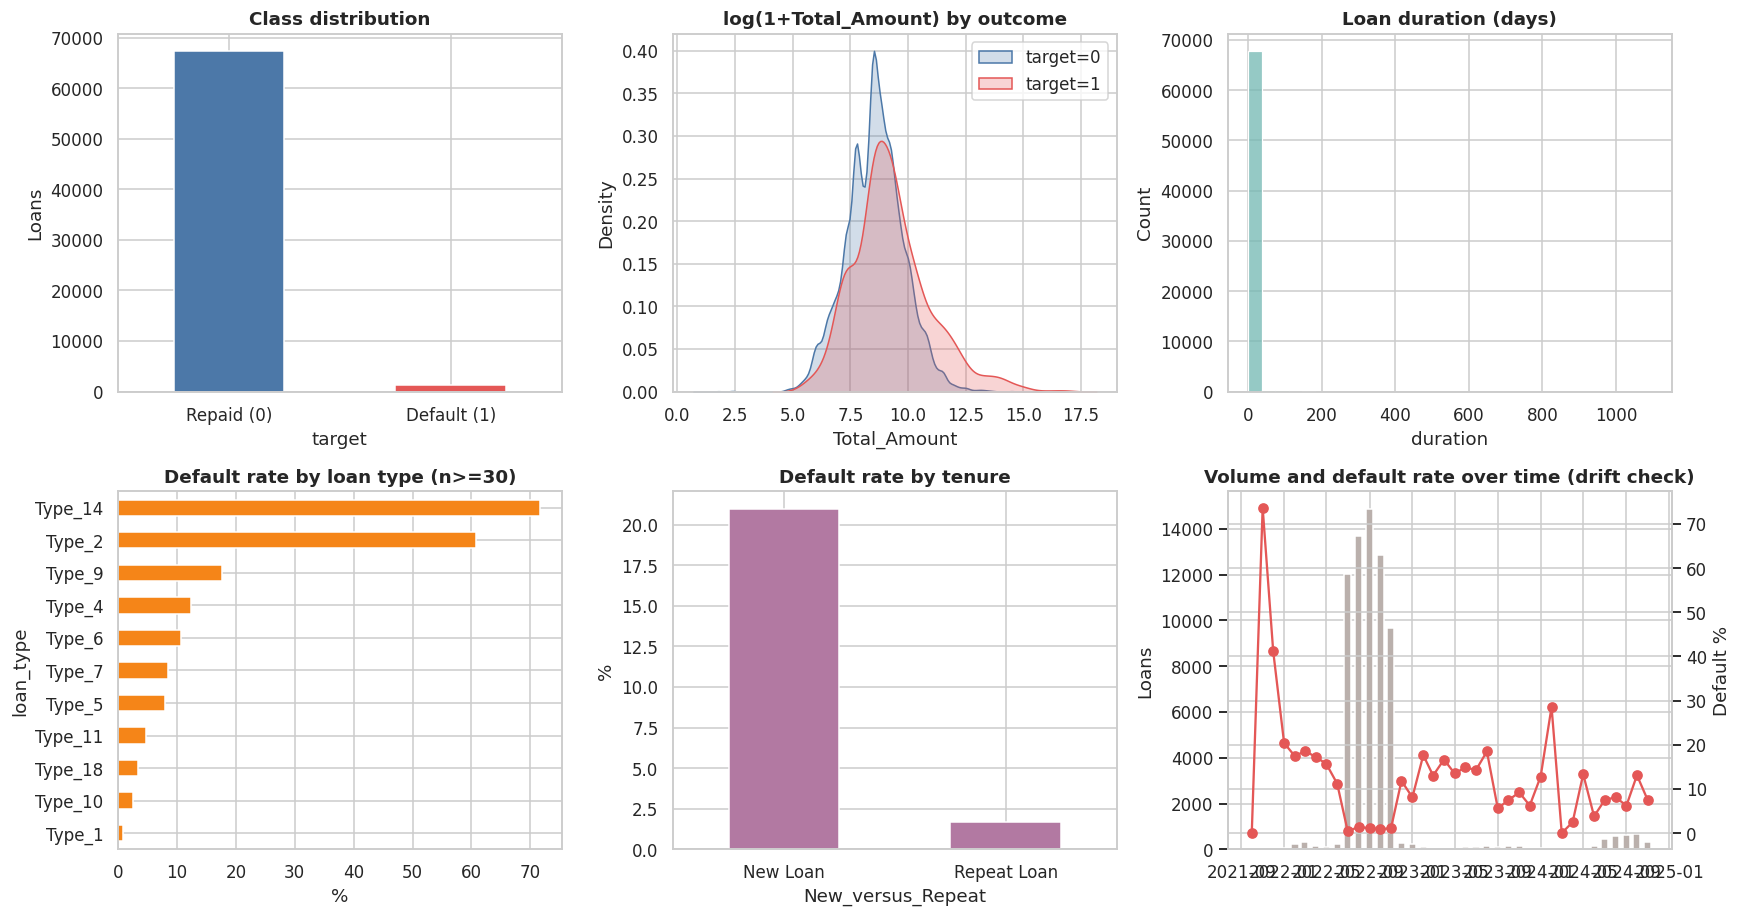

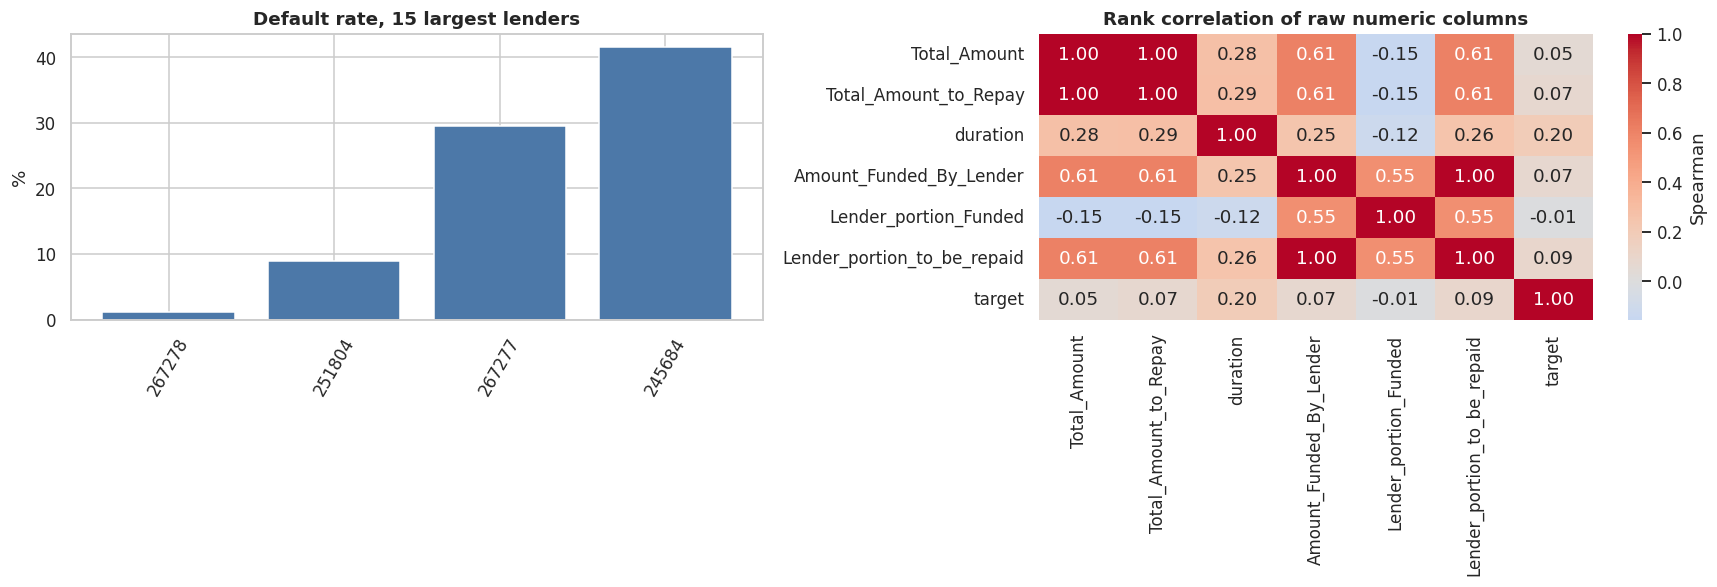

Highly collinear pairs (|rho|>0.9): [('Total_Amount', 'Total_Amount_to_Repay', np.float64(0.999)), ('Amount_Funded_By_Lender', 'Lender_portion_to_be_repaid', np.float64(0.999))]

Categorical cardinality: {'loan_type': 22, 'lender_id': 4, 'New_versus_Repeat': 2}
  loan_type: top-5 cover 98.7% of rows; 15 levels below MIN_CAT_FREQ
  lender_id: top-5 cover 100.0% of rows; 0 levels below MIN_CAT_FREQ
  New_versus_Repeat: top-5 cover 100.0% of rows; 0 levels below MIN_CAT_FREQ


,skew,pct_outside_1.5IQR,skew_after_log1p
Total_Amount,103.828,9.941,0.139
Total_Amount_to_Repay,104.579,10.155,0.147
duration,34.059,5.362,5.789
Amount_Funded_By_Lender,61.064,9.797,-1.190


In [ ]:
# ---------- EDA figure 1: target, size, term, product, tenure, time ----------
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
lab['target'].value_counts().sort_index().plot.bar(ax=ax[0,0], color=['#4C78A8','#E45756']); ax[0,0].set_title('Class distribution')
ax[0,0].set_xticklabels(['Repaid (0)','Default (1)'], rotation=0); ax[0,0].set_ylabel('Loans')
for k, c in [(0,'#4C78A8'), (1,'#E45756')]:
    sns.kdeplot(np.log1p(lab.loc[lab.target==k,'Total_Amount']), ax=ax[0,1], color=c, label=f'target={k}', fill=True, alpha=.25, common_norm=False)
ax[0,1].set_title('log(1+Total_Amount) by outcome'); ax[0,1].legend()
sns.histplot(lab['duration'], bins=30, ax=ax[0,2], color='#72B7B2'); ax[0,2].set_title('Loan duration (days)')
(lab.groupby('loan_type')['target'].agg(['mean','size']).query('size>=30')['mean']*100).sort_values().plot.barh(ax=ax[1,0], color='#F58518')
ax[1,0].set_title('Default rate by loan type (n>=30)'); ax[1,0].set_xlabel('%')
(lab.groupby('New_versus_Repeat')['target'].mean()*100).plot.bar(ax=ax[1,1], color='#B279A2'); ax[1,1].set_title('Default rate by tenure'); ax[1,1].set_ylabel('%'); ax[1,1].tick_params(axis='x', rotation=0)
m = lab.set_index('disbursement_date').resample('MS')['target'].agg(['mean','size'])
ax[1,2].bar(m.index, m['size'], width=20, color='#BAB0AC'); ax[1,2].set_ylabel('Loans'); ax2 = ax[1,2].twinx()
ax2.plot(m.index, m['mean']*100, color='#E45756', marker='o'); ax2.set_ylabel('Default %'); ax[1,2].set_title('Volume and default rate over time (drift check)')
plt.tight_layout(); savefig(fig, 'plots_eda', 'eda_overview')

# ---------- EDA figure 2: lender concentration and correlation ----------
top_l = lab['lender_id'].value_counts().head(15).index
g = lab[lab.lender_id.isin(top_l)].groupby('lender_id')['target'].agg(['mean','size']).sort_values('size', ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].bar(g.index.astype(str), g['mean']*100, color='#4C78A8'); ax[0].set_title('Default rate, 15 largest lenders'); ax[0].set_ylabel('%'); ax[0].tick_params(axis='x', rotation=60)
num_raw = ['Total_Amount','Total_Amount_to_Repay','duration','Amount_Funded_By_Lender','Lender_portion_Funded','Lender_portion_to_be_repaid','target']
corr = lab[num_raw].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1], cbar_kws={'label':'Spearman'}); ax[1].set_title('Rank correlation of raw numeric columns')
plt.tight_layout(); savefig(fig, 'plots_eda', 'eda_lender_corr')

hi = [(a,b,round(corr.loc[a,b],3)) for i,a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>0.9]
print('Highly collinear pairs (|rho|>0.9):', hi)

# ---------- cardinality, skew, outliers ----------
print('\nCategorical cardinality:', {c: lab[c].nunique() for c in CAT_COLS})
for c in CAT_COLS:
    vc = lab[c].value_counts(); print(f'  {c}: top-5 cover {100*vc.head(5).sum()/len(lab):.1f}% of rows; {int((vc<CFG["MIN_CAT_FREQ"]).sum())} levels below MIN_CAT_FREQ')
num_cols = ['Total_Amount','Total_Amount_to_Repay','duration','Amount_Funded_By_Lender']
q1, q3 = lab[num_cols].quantile(.25), lab[num_cols].quantile(.75); iqr = q3 - q1
out_tbl = pd.DataFrame({'skew': lab[num_cols].skew(), 'pct_outside_1.5IQR': ((lab[num_cols] < q1-1.5*iqr) | (lab[num_cols] > q3+1.5*iqr)).mean()*100,
                        'skew_after_log1p': np.log1p(lab[num_cols].clip(lower=0)).skew()})
display(out_tbl.round(3))

**How to read the EDA (write your own findings from the outputs above):** (1) imbalance ratio and what accuracy a majority classifier would score; (2) heavy right skew of amounts, which motivates log transforms; (3) cardinality of `lender_id`, which motivates pooling rare levels rather than a full one-hot; (4) whether the default rate drifts over months, which motivates temporal validation; (5) collinearity between amount, repayment amount and funded amount, which matters for linear models. Outliers are **kept** (large legitimate loans), and log transforms plus tree models handle them; clipping is not applied because it would hide the very tail where losses sit.

## 3. Feature engineering (time-safe)
| Group | Features | Meaning / why predictive | Definition |
|---|---|---|---|
| base | `loan_type`, `lender_id`, `duration`, `New_versus_Repeat` | Product, funder, term and tenure drive risk differences | raw |
| calendar | month, quarter, weekday, day-of-month, month-end flag, due weekday, due-on-weekend | Cash flow follows pay cycles; weekend due dates change repayment friction | from dates |
| terms (Task 2 only) | `log_amount`, `fee_rate`, `daily_fee_rate`, funded and repay shares, `amount_vs_prior_mean` | Price and size of credit; high daily price strains the borrower; a jump over past loan size signals stretch | `fee_rate=(Repay-Amount)/Amount`, `daily_fee_rate=fee_rate/duration` |
| history | prior loan count, days since last loan, prior mean/last amount, resolved prior loans, prior defaults, prior default rate | Past behaviour is the strongest classical credit signal | backward `merge_asof`, exact matches excluded; outcomes counted only after `due_date` |
| macro | FRED country-year indicators | Inflation, FX and rates change repayment capacity | joined on (country, year-1) |

Learned statistics (imputation medians, scaling, encoders) are **not** computed here; they live in pipelines (Section 5).

In [ ]:
econ_path = DATA / CFG['ECON_FILE']
econ_prep = None
if econ_path.exists():
    econ_prep = prepare_econ(pd.read_csv(econ_path))
    if econ_prep is None: print('economic_indicators.csv found but no country/year columns detected: macro features skipped')
else:
    print('economic_indicators.csv not found: macro features skipped (set ECON_FILE in config to enable)')

def make_features(df, labelled):
    # One function = one definition of the features for train, test and the scoring service.
    out = add_calendar(df); out = add_terms(out)
    out = add_history(out, labelled, CFG['GRACE_DAYS'])
    out = add_macro(out, econ_prep, lag_years=1)
    return out

feat_df = make_features(lab, lab)
macro_cols = [c for c in feat_df.columns if c.startswith('macro_')]
if macro_cols:
    cov = feat_df[macro_cols].notna().mean()
    macro_cols = [c for c in macro_cols if cov[c] > 0.5 and feat_df[c].nunique() > 1]
    print(f'Macro columns kept ({len(macro_cols)}):', macro_cols[:8], '...' if len(macro_cols) > 8 else '')

FEATURE_GROUPS = {
    'base':     ['duration', 'loan_type', 'lender_id', 'New_versus_Repeat'],
    'calendar': ['disb_month','disb_quarter','disb_dow','disb_dom','disb_month_end','due_dow','due_weekend'],
    'terms':    ['log_amount','fee_rate','daily_fee_rate','lender_funded_share','lender_repay_share','Lender_portion_Funded','amount_vs_prior_mean'],
    'history':  ['n_prior_loans','no_prior_loans','days_since_last_loan','prior_mean_amount','last_amount','n_resolved_prior','n_prior_defaults','prior_default_rate'],
    'macro':    macro_cols,
}
FEATURE_GROUPS = {k: [c for c in v if c in feat_df.columns] for k, v in FEATURE_GROUPS.items()}
ALL_CLF = [c for g in FEATURE_GROUPS.values() for c in g]
SHARED  = [c for g in ('base','calendar','history','macro') for c in FEATURE_GROUPS[g]]   # Task 1 safe set
print({k: len(v) for k, v in FEATURE_GROUPS.items()})

# Sanity: engineered tenure vs supplied tenure label, and history coverage
print('\nSupplied tenure vs engineered "has prior loan in Train":')
display(pd.crosstab(feat_df['New_versus_Repeat'], feat_df['no_prior_loans'].map({1:'no prior in data', 0:'prior in data'})))
print('Share of loans with >=1 resolved prior loan: %.1f%%' % (100*(feat_df['n_resolved_prior']>0).mean()))
display(feat_df[ALL_CLF].describe().T[['count','mean','std','min','50%','max']].round(3))

economic_indicators.csv found but no country/year columns detected: macro features skipped
{'base': 4, 'calendar': 7, 'terms': 7, 'history': 8, 'macro': 0}

Supplied tenure vs engineered "has prior loan in Train":


no_prior_loans,no prior in data,prior in data
New_versus_Repeat,,
New Loan,567,0
Repeat Loan,6792,61295


Share of loans with >=1 resolved prior loan: 82.5%


,count,mean,std,min,50%,max
duration,68654.0,8.545,13.343,1.000,7.000,1096.000
disb_month,68654.0,8.783,1.631,1.000,9.000,12.000
disb_quarter,68654.0,3.309,0.573,1.000,3.000,4.000
disb_dow,68654.0,2.496,1.794,0.000,2.000,6.000
disb_dom,68654.0,16.346,8.727,1.000,17.000,31.000
disb_month_end,68654.0,0.227,0.419,0.000,0.000,1.000
due_dow,68654.0,2.531,1.808,0.000,3.000,6.000
due_weekend,68654.0,0.198,0.399,0.000,0.000,1.000
log_amount,68654.0,8.575,1.264,1.099,8.566,16.951
fee_rate,68654.0,0.022,0.056,-1.000,0.008,2.165


In [ ]:
# Time-safety unit test: for a sample of loans, recompute history by brute force and compare.
rng = np.random.RandomState(SEED); chk = feat_df.sample(min(300, len(feat_df)), random_state=SEED)
bad = 0
for _, r in chk.iterrows():
    prev = lab[(lab.customer_id == r.customer_id) & (lab.disbursement_date < r.disbursement_date)]
    res  = prev[prev.due_date + pd.to_timedelta(CFG['GRACE_DAYS'], 'D') < r.disbursement_date]
    if int(r.n_prior_loans) != len(prev) or int(r.n_resolved_prior) != len(res) or int(r.n_prior_defaults) != int(res.target.sum()): bad += 1
print(f'History brute-force check on {len(chk)} loans: {bad} mismatches (must be 0)')
assert bad == 0, 'Time-safe history is inconsistent'

History brute-force check on 300 loans: 0 mismatches (must be 0)


## 4. Experimental design
### 4.1 Temporal hold-out and grouped folds
* **Test** = the most recent `TEST_FRAC` of loans by `disbursement_date`. It stays untouched until Section 7.
* **Dev** = earlier loans, minus any whose `due_date` reaches into the test period (their outcomes would not be known at the test start: a *purge*).
* Model selection uses `StratifiedGroupKFold` (grouped by `customer_id`, stratified on default, shuffled). Fold seed A is used for tuning, an independent seed B for reported out-of-fold (OOF) scores.

In [ ]:
test_start = lab['disbursement_date'].quantile(1 - CFG['TEST_FRAC'])
is_test = feat_df['disbursement_date'] >= test_start
is_dev  = (feat_df['disbursement_date'] < test_start) & (feat_df['due_date'] < test_start)
dev, test = feat_df[is_dev].reset_index(drop=True), feat_df[is_test].reset_index(drop=True)
print(f'Test starts {test_start.date()} | dev {len(dev):,} (defaults {dev.target.sum()}, {100*dev.target.mean():.2f}%) '
      f'| test {len(test):,} (defaults {test.target.sum()}, {100*test.target.mean():.2f}%) | purged {int((~is_dev & ~is_test).sum()):,}')
assert dev['due_date'].max() < test_start and dev['disbursement_date'].max() < test_start
print('Customers in both dev and test: %d (%.1f%% of test rows). Kept: in production, returning borrowers are scored too.'
      % (len(set(dev.customer_id) & set(test.customer_id)), 100*test.customer_id.isin(dev.customer_id).mean()))
assert test.target.sum() >= 30, 'Too few test defaults for stable estimates; reduce TEST_FRAC split or use more data'

y_dev, g_dev = dev['target'], dev['customer_id']
X_dev, X_test = dev, test        # pipelines select columns themselves
POS_WEIGHT = float((y_dev == 0).sum() / (y_dev == 1).sum())   # from training data only

def make_folds(seed, n=CFG['N_FOLDS']):
    sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    folds = list(sgkf.split(X_dev, y_dev, g_dev))
    for tr_i, va_i in folds:
        assert set(g_dev.iloc[tr_i]).isdisjoint(g_dev.iloc[va_i]), 'customer leakage across folds'
        assert y_dev.iloc[va_i].sum() > 0, 'fold without positives'
    return folds
FOLDS_A, FOLDS_B = make_folds(SEED_TUNE), make_folds(SEED)
print('Folds built; no customer appears in both train and validation of any fold (asserted).')
dev.to_csv(DIRS['data'] / 'dev.csv', index=False)

Test starts 2022-11-02 | dev 52,331 (defaults 674, 1.29%) | test 13,775 (defaults 533, 3.87%) | purged 2,548
Customers in both dev and test: 2559 (72.0% of test rows). Kept: in production, returning borrowers are scored too.
Folds built; no customer appears in both train and validation of any fold (asserted).


### 4.2 Preprocessing pipeline and estimator factory
Numeric: median imputation, standardisation (needed by LR, kNN, SVM; harmless for trees). Categorical: most-frequent imputation, one-hot with rare levels pooled (`min_frequency`), unknown levels at scoring time mapped to the infrequent bucket. All steps are fitted **inside** each training fold. Outliers are not clipped (see Section 2). Feature selection is implicit: L2 shrinkage (LR), tree-based selection, and the ablation study (Section 6.5).

In [ ]:
def make_preprocessor(cols):
    cat = [c for c in cols if c in CAT_COLS]; num = [c for c in cols if c not in CAT_COLS]
    num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
    cat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                         ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=CFG['MIN_CAT_FREQ'], sparse_output=False))])
    return ColumnTransformer([('num', num_pipe, num), ('cat', cat_pipe, cat)], remainder='drop', verbose_feature_names_out=True)

def get_sampler(name):
    r = CFG['SAMPLING_RATIO']
    return {'none': None, 'cw': None, 'builtin': None,
            'ros': RandomOverSampler(sampling_strategy=r, random_state=SEED),
            'rus': RandomUnderSampler(sampling_strategy=r, random_state=SEED),
            'smote': SMOTE(sampling_strategy=r, random_state=SEED),
            'bsmote': BorderlineSMOTE(sampling_strategy=r, random_state=SEED),
            'adasyn': ADASYN(sampling_strategy=r, random_state=SEED),
            'smote_tomek': SMOTETomek(sampling_strategy=r, random_state=SEED)}[name]

def make_clf(model, strategy, params=None):
    cw = 'balanced' if strategy == 'cw' else None
    spw = POS_WEIGHT if strategy == 'cw' else 1.0
    clfs = {
     'majority': DummyClassifier(strategy='prior'),
     'logreg':   LogisticRegression(C=1.0, max_iter=3000, class_weight=cw, random_state=SEED),
     'knn':      KNeighborsClassifier(n_neighbors=50, weights='distance', n_jobs=-1),
     'dtree':    DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight=cw, random_state=SEED),
     'rf':       RandomForestClassifier(n_estimators=F(300,60), min_samples_leaf=20, max_features='sqrt',
                     class_weight=('balanced_subsample' if cw else None), n_jobs=-1, random_state=SEED),
     'et':       ExtraTreesClassifier(n_estimators=F(300,60), min_samples_leaf=20, class_weight=('balanced_subsample' if cw else None), n_jobs=-1, random_state=SEED),
     'lgbm':     lgb.LGBMClassifier(n_estimators=F(400,80), learning_rate=0.03, num_leaves=15, min_child_samples=50, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, class_weight=cw, random_state=SEED, n_jobs=-1, verbose=-1),
     'xgb':      xgb.XGBClassifier(n_estimators=F(400,80), learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                     scale_pos_weight=spw, tree_method='hist', eval_metric='aucpr', random_state=SEED, n_jobs=-1, verbosity=0),
     'brf':      BalancedRandomForestClassifier(n_estimators=F(300,60), min_samples_leaf=5, n_jobs=-1, random_state=SEED, sampling_strategy='all', replacement=True, bootstrap=True),
     'eec':      EasyEnsembleClassifier(n_estimators=F(10,4), random_state=SEED, n_jobs=1),
     'svc':      SubsampledClassifier(SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced'), max_n=CFG['MAX_SVC_ROWS'], seed=SEED),
    }
    clf = clfs[model]
    if params: clf.set_params(**{k.replace('clf__', ''): v for k, v in params.items()})
    return clf

def build_estimator(model, strategy, feats, params=None):
    steps = [('prep', make_preprocessor(feats))]
    s = get_sampler(strategy)
    if s is not None: steps.append(('sampler', s))
    steps.append(('clf', make_clf(model, strategy, params)))
    return ImbPipeline(steps)

def get_score(est, X):
    return est.predict_proba(X)[:, 1] if hasattr(est, 'predict_proba') else expit(est.decision_function(X))

### 4.3 Cost matrix (ProSit Part A.3)
Costs are **per loan** and denominated in money. Fee income comes from the data (`Total_Amount_to_Repay - Total_Amount`); recovery and collection costs are **placeholders in the config that you must replace** with figures you can justify for the Ghanaian market (the ProSit says not to reuse the Appendix numbers).

* **False negative** (approve, borrower defaults): `FN_i = principal_i x (1 - recovery) + principal_i x collection_cost_rate`
* **False positive** (decline a good borrower): `FP_i = fee_i = Total_Amount_to_Repay_i - Total_Amount_i` (forgone income; also a denied borrower, which we report separately as an access cost)
* With calibrated probability *p*, decline when `p x FN > (1-p) x FP`, i.e. `p > FP/(FP+FN)`.

In [ ]:
def cost_vectors(df, recovery=None, coll=None):
    recovery = CFG['RECOVERY_RATE'] if recovery is None else recovery
    coll = CFG['COLLECTION_COST_RATE'] if coll is None else coll
    P = df['Total_Amount'].values.astype(float); fee = (df['Total_Amount_to_Repay'] - df['Total_Amount']).clip(lower=0).values.astype(float)
    return P * (1 - recovery) + P * coll, fee      # (FN cost, FP cost) per loan

def expected_cost(y, decline, fn_c, fp_c):
    y = np.asarray(y); decline = np.asarray(decline).astype(bool)
    return float((fn_c[(y == 1) & ~decline]).sum() + (fp_c[(y == 0) & decline]).sum())

fn_dev, fp_dev = cost_vectors(dev)
fx = CFG['FX_TO_GHS']
cm = pd.DataFrame({'mean principal (GHS)': [dev.Total_Amount.mean()*fx], 'mean fee income (GHS)': [fp_dev.mean()*fx],
                   'mean FN cost (GHS)': [fn_dev.mean()*fx], 'mean FP cost (GHS)': [fp_dev.mean()*fx]})
cm['FN:FP ratio (reported after money)'] = fn_dev.mean() / max(fp_dev.mean(), 1e-9)
cm['analytic threshold p*'] = fp_dev.mean() / (fp_dev.mean() + fn_dev.mean())
display(cm.round(3))
print('Cost-based decline threshold sensitivity (mean-cost approximation):')
sens = []
for rec in (0.0, CFG['RECOVERY_RATE'], 0.4):
    fn_s, fp_s = cost_vectors(dev, recovery=rec)
    sens.append({'recovery': rec, 'mean FN': fn_s.mean()*fx, 'mean FP': fp_s.mean()*fx, 'p*': fp_s.mean()/(fp_s.mean()+fn_s.mean())})
display(pd.DataFrame(sens).round(3))
print('NOTE: if p* is far above the base default rate, a model that cannot separate risky borrowers well will never flag anyone; that is a finding, not a bug.')

,mean principal (GHS),mean fee income (GHS),mean FN cost (GHS),mean FP cost (GHS),FN:FP ratio (reported after money),analytic threshold p*
0,11218.509,254.895,9872.288,254.895,38.731,0.025


Cost-based decline threshold sensitivity (mean-cost approximation):


,recovery,mean FN,mean FP,p*
0,0.0,12115.990,254.895,0.021
1,0.2,9872.288,254.895,0.025
2,0.4,7628.586,254.895,0.032


NOTE: if p* is far above the base default rate, a model that cannot separate risky borrowers well will never flag anyone; that is a finding, not a bug.


### 4.4 Validation integrity (E1): stratified vs grouped vs temporal
Same models, same features, three validation schemes. The gap between naive stratified CV and the others measures how much a naive protocol inflates performance (ProSit B.3). The model used here is a reference logistic regression and a LightGBM, both class-weighted.

,model,scheme,PR-AUC mean,sd,n_folds
0,logreg,Stratified k-fold (naive),0.7936,0.0305,5
1,logreg,StratifiedGroupKFold by customer,0.7917,0.0315,5
2,logreg,Temporal forward-chaining,0.8052,0.0483,4
3,lgbm,Stratified k-fold (naive),0.9697,0.0141,5
4,lgbm,StratifiedGroupKFold by customer,0.9632,0.0087,5
5,lgbm,Temporal forward-chaining,0.9721,0.0221,4


logreg: naive minus grouped = +0.0019 | naive minus temporal = -0.0116 PR-AUC (positive = naive score inflated)
lgbm: naive minus grouped = +0.0065 | naive minus temporal = -0.0024 PR-AUC (positive = naive score inflated)


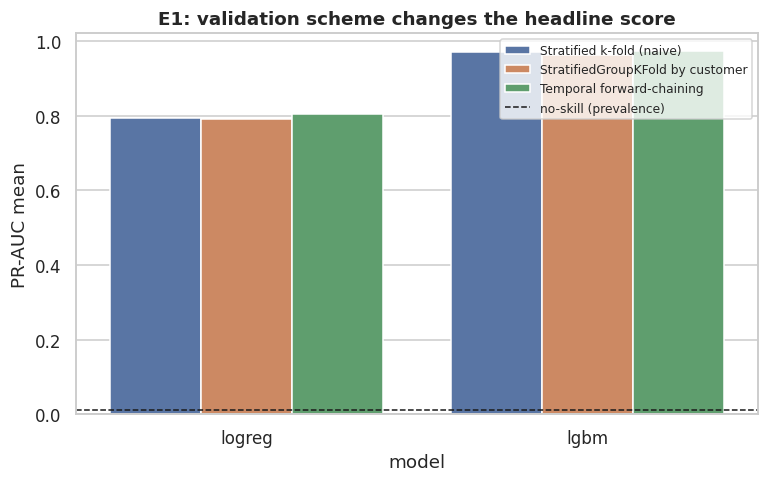

In [ ]:
def eval_splits(model, strategy, feats, splits):
    aps = []
    for tr_i, va_i in splits:
        est = build_estimator(model, strategy, feats); est.fit(X_dev.iloc[tr_i], y_dev.iloc[tr_i])
        aps.append(average_precision_score(y_dev.iloc[va_i], get_score(est, X_dev.iloc[va_i])))
    return aps

strat = list(StratifiedKFold(CFG['N_FOLDS'], shuffle=True, random_state=SEED).split(X_dev, y_dev))
# forward-chaining temporal folds with purge (train loans must be resolved before the validation block starts)
edges = dev['disbursement_date'].quantile([0.5, 0.625, 0.75, 0.875, 1.0]).values
temporal = []
for i in range(len(edges) - 1):
    lo, hi = edges[i], edges[i + 1]
    tri = np.where((dev.disbursement_date < lo) & (dev.due_date < lo))[0]
    vai = np.where((dev.disbursement_date >= lo) & (dev.disbursement_date <= hi if i == len(edges) - 2 else dev.disbursement_date < hi))[0]
    if y_dev.iloc[vai].sum() > 0 and y_dev.iloc[tri].sum() > 0: temporal.append((tri, vai))
schemes = {'Stratified k-fold (naive)': strat, 'StratifiedGroupKFold by customer': FOLDS_B, 'Temporal forward-chaining': temporal}
rows = []
for model in ['logreg', 'lgbm']:
    for name, sp in schemes.items():
        aps = eval_splits(model, 'cw', ALL_CLF, sp)
        rows.append({'model': model, 'scheme': name, 'PR-AUC mean': np.mean(aps), 'sd': np.std(aps, ddof=1) if len(aps) > 1 else np.nan, 'n_folds': len(aps)})
val_cmp = pd.DataFrame(rows); display(val_cmp.round(4)); val_cmp.to_csv(DIRS['results'] / 'validation_scheme_comparison.csv', index=False)
for model in ['logreg', 'lgbm']:
    s = val_cmp[val_cmp.model == model].set_index('scheme')['PR-AUC mean']
    print(f"{model}: naive minus grouped = {s.iloc[0]-s.iloc[1]:+.4f} | naive minus temporal = {s.iloc[0]-s.iloc[2]:+.4f} PR-AUC (positive = naive score inflated)")
fig, ax = plt.subplots(figsize=(8, 4.5)); sns.barplot(data=val_cmp, x='model', y='PR-AUC mean', hue='scheme', ax=ax)
ax.axhline(y_dev.mean(), color='k', ls='--', lw=1, label='no-skill (prevalence)'); ax.set_title('E1: validation scheme changes the headline score'); ax.legend(fontsize=8)
savefig(fig, 'plots_cmp', 'e1_validation_schemes')

**Which scheme to trust for deployment?** The temporal scheme most closely mimics production (train on the past, score the future), and grouped CV removes the repeat-borrower shortcut. State in your report which one you trust and why, citing the gaps printed above. Model selection below uses grouped CV (more positives per fold, stable), while the final test is temporal.

## 5. Experiment infrastructure (metrics, checkpointing, resume)
Every experiment: (1) OOF scoring with fold seed B, (2) refit on all dev data, (3) save the fitted pipeline and a small results file immediately. Re-running the notebook skips completed experiments. Threshold-dependent metrics for *strategy comparison* are reported at two comparable points chosen on OOF scores only: the F1-optimal threshold, and a fixed **alert budget** (flag the riskiest `TOP_Q` share), which does not depend on calibration.

In [ ]:
def clf_metrics(y, s, thr, fn_c=None, fp_c=None):
    y = np.asarray(y); s = np.asarray(s); yh = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    out = dict(thr=float(thr), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
        accuracy=accuracy_score(y, yh), precision=precision_score(y, yh, zero_division=0), recall=recall_score(y, yh, zero_division=0),
        specificity=tn / max(tn + fp, 1), f1=f1_score(y, yh, zero_division=0), f2=fbeta_score(y, yh, beta=2, zero_division=0),
        balanced_accuracy=balanced_accuracy_score(y, yh), mcc=matthews_corrcoef(y, yh) if len(set(yh)) > 1 else 0.0,
        fpr=fp / max(fp + tn, 1), fnr=fn / max(fn + tp, 1), flag_rate=yh.mean())
    if fn_c is not None: out['expected_cost'] = expected_cost(y, yh, fn_c, fp_c)
    return out

def f1_opt_threshold(y, s):
    p, r, t = precision_recall_curve(y, s); f = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.nanargmax(f)]) if len(t) else 0.5

def topq_threshold(s, q): return float(np.quantile(s, 1 - q))

def threshold_free(y, s):
    return dict(pr_auc=average_precision_score(y, s), roc_auc=roc_auc_score(y, s), brier=brier_score_loss(y, np.clip(s, 0, 1)))

def ece(y, p, bins=10):
    y = np.asarray(y); p = np.asarray(p); edges = np.quantile(p, np.linspace(0, 1, bins + 1)); edges[-1] += 1e-9; e = 0
    for i in range(bins):
        m = (p >= edges[i]) & (p < edges[i + 1])
        if m.sum(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

REG_CSV = DIRS['results'] / 'experiment_metrics.csv'
def load_registry(): return pd.read_csv(REG_CSV) if REG_CSV.exists() else pd.DataFrame()
def save_row(row):
    reg = load_registry()
    if len(reg): reg = reg[reg.exp_id != row['exp_id']]
    pd.concat([reg, pd.DataFrame([row])], ignore_index=True).to_csv(REG_CSV, index=False)

CKPT = {'base': DIRS['ckpt_base'], 'imb': DIRS['ckpt_imb'], 'opt': DIRS['ckpt_opt'], 'abl': DIRS['ckpt_abl']}
FAILED = []
RES = {}     # exp_id -> dict(row, oof, fold_ap) kept in memory for plotting

def run_exp(exp_id, stage, model, strategy, feats, params=None, ckpt='base', folds=None, force=False):
    folds = folds or FOLDS_B
    rpath = CKPT[ckpt] / f'{exp_id}.res.joblib'; mpath = CKPT[ckpt] / f'{exp_id}.model.joblib'
    if rpath.exists() and mpath.exists() and not force:
        RES[exp_id] = joblib.load(rpath); return RES[exp_id]            # resume
    try:
        t0 = time.time(); oof = np.full(len(y_dev), np.nan); fold_ap = []
        for tr_i, va_i in folds:
            est = build_estimator(model, strategy, feats, params); est.fit(X_dev.iloc[tr_i], y_dev.iloc[tr_i])
            s = get_score(est, X_dev.iloc[va_i]); oof[va_i] = s; fold_ap.append(average_precision_score(y_dev.iloc[va_i], s))
        assert not np.isnan(oof).any()
        tf = threshold_free(y_dev, oof)
        m_f1 = clf_metrics(y_dev, oof, f1_opt_threshold(y_dev, oof), fn_dev, fp_dev)
        m_tq = clf_metrics(y_dev, oof, topq_threshold(oof, CFG['TOP_Q']), fn_dev, fp_dev)
        full = build_estimator(model, strategy, feats, params).fit(X_dev, y_dev)           # refit on all dev
        row = dict(exp_id=exp_id, stage=stage, model=model, strategy=strategy, n_features=len(feats), params=json.dumps(params or {}, default=str),
                   **tf, ap_fold_mean=np.mean(fold_ap), ap_fold_sd=np.std(fold_ap, ddof=1),
                   **{f'f1opt_{k}': m_f1[k] for k in ['thr','precision','recall','f1','f2','mcc','balanced_accuracy','fpr','fnr']},
                   **{f'top_{k}': m_tq[k] for k in ['precision','recall','f1','fpr']},
                   apparent_pr_auc=average_precision_score(y_dev, get_score(full, X_dev)), fit_seconds=round(time.time() - t0, 1))
        res = dict(row=row, oof=oof, fold_ap=fold_ap, feats=feats)
        joblib.dump(full, mpath); joblib.dump(res, rpath); save_row(row); RES[exp_id] = res
        print(f"  done {exp_id:<34} PR-AUC={row['pr_auc']:.4f} (fold {row['ap_fold_mean']:.4f}+-{row['ap_fold_sd']:.4f}) ROC={row['roc_auc']:.3f} [{row['fit_seconds']}s]")
        return res
    except Exception as e:
        FAILED.append(dict(exp_id=exp_id, error=repr(e))); print(f'  FAILED {exp_id}: {e!r}')
        (DIRS['reports'] / 'failed_experiments.json').write_text(json.dumps(FAILED, indent=2)); return None

def registry_table(stage=None):
    r = load_registry()
    if stage: r = r[r.stage == stage]
    return r.sort_values('pr_auc', ascending=False).reset_index(drop=True)
print('Infrastructure ready. Prevalence (no-skill PR-AUC):', round(float(y_dev.mean()), 4))

Infrastructure ready. Prevalence (no-skill PR-AUC): 0.0129


## 6. Task 2: default classification
### 6.1 E2: model families (default configuration, class-weighted where supported)
| Model | Why included |
|---|---|
| Majority class (prior) | Mandatory baseline; PR-AUC equals prevalence |
| Logistic regression (class weight) | Committee's preferred simple, explainable model; derivation required (LO3) |
| kNN | Instance-based reference (ISLR Ch 2) |
| Decision tree (pruned) | Interpretable non-linear rules |
| Random forest, Extra trees | Bagged ensembles, variance reduction |
| LightGBM, XGBoost | Gradient boosting: usually strongest on tabular data |
| Balanced RF, EasyEnsemble | Imbalance handled inside the ensemble |
| SVM (RBF) | Margin method; trained on all positives plus a negative subsample for tractability |

Feature set: `ALL_CLF` (base + calendar + terms + history + macro when available).

In [ ]:
t0 = time.time()
print('E2: model families')
S1 = [('majority','none'), ('logreg','cw'), ('knn','none'), ('dtree','cw'), ('rf','cw'), ('et','cw'),
      ('lgbm','cw'), ('xgb','cw'), ('brf','builtin'), ('eec','builtin'), ('svc','builtin')]
for m, s in S1:
    run_exp(f'S1_{m}_{s}', 'S1_models', m, s, ALL_CLF, ckpt='base')
tab = registry_table('S1_models')
show = ['exp_id','pr_auc','ap_fold_mean','ap_fold_sd','roc_auc','brier','f1opt_precision','f1opt_recall','f1opt_f1','f1opt_mcc','f1opt_fpr','top_precision','top_recall','top_fpr','apparent_pr_auc']
display(tab[show].round(4)); print(f'{(time.time()-t0)/60:.1f} min')

E2: model families
  done S1_majority_none                   PR-AUC=0.0117 (fold 0.0130+-0.0023) ROC=0.457 [1.7s]
  done S1_logreg_cw                       PR-AUC=0.7906 (fold 0.7917+-0.0315) ROC=0.995 [10.1s]
  done S1_knn_none                        PR-AUC=0.8542 (fold 0.8536+-0.0303) ROC=0.988 [37.6s]
  done S1_dtree_cw                        PR-AUC=0.9007 (fold 0.8718+-0.0307) ROC=0.994 [3.4s]
  done S1_rf_cw                           PR-AUC=0.8926 (fold 0.8930+-0.0338) ROC=0.998 [73.7s]
  done S1_et_cw                           PR-AUC=0.4334 (fold 0.4435+-0.0641) ROC=0.985 [30.8s]
  done S1_lgbm_cw                         PR-AUC=0.9611 (fold 0.9632+-0.0087) ROC=0.997 [12.4s]
  done S1_xgb_cw                          PR-AUC=0.9617 (fold 0.9631+-0.0110) ROC=0.997 [12.5s]
  done S1_brf_builtin                     PR-AUC=0.8693 (fold 0.8672+-0.0466) ROC=0.998 [16.8s]
  done S1_eec_builtin                     PR-AUC=0.8125 (fold 0.8113+-0.0467) ROC=0.997 [16.0s]
  done S1_svc_builtin  

,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,f1opt_precision,f1opt_recall,f1opt_f1,f1opt_mcc,f1opt_fpr,top_precision,top_recall,top_fpr,apparent_pr_auc
0,S1_xgb_cw,0.9617,0.9631,0.0110,0.9974,0.0035,0.8979,0.8872,0.8925,0.8912,0.0013,0.1284,0.9970,0.0883,0.9922
1,S1_lgbm_cw,0.9611,0.9632,0.0087,0.9972,0.0029,0.9033,0.8872,0.8952,0.8939,0.0012,0.1284,0.9970,0.0883,0.9977
2,S1_dtree_cw,0.9007,0.8718,0.0307,0.9936,0.0100,0.7621,0.9080,0.8287,0.8295,0.0037,0.0129,1.0000,1.0000,0.8782
3,S1_rf_cw,0.8926,0.8930,0.0338,0.9981,0.0067,0.7883,0.9006,0.8407,0.8404,0.0032,0.1286,0.9985,0.0883,0.9692
4,S1_brf_builtin,0.8693,0.8672,0.0466,0.9975,0.0165,0.7506,0.9199,0.8267,0.8286,0.0040,0.1284,0.9970,0.0883,0.9112
5,S1_knn_none,0.8542,0.8536,0.0303,0.9883,0.0044,0.7893,0.7003,0.7421,0.7403,0.0024,0.0129,1.0000,1.0000,1.0000
6,S1_eec_builtin,0.8125,0.8113,0.0467,0.9972,0.1050,0.7525,0.9021,0.8205,0.8214,0.0039,0.1286,0.9985,0.0883,0.8450
7,S1_logreg_cw,0.7906,0.7917,0.0315,0.9952,0.0119,0.6681,0.9318,0.7782,0.7859,0.0060,0.1278,0.9926,0.0884,0.7992
8,S1_svc_builtin,0.7405,0.7516,0.0410,0.9960,0.0250,0.7098,0.8383,0.7687,0.7682,0.0045,0.1284,0.9970,0.0883,0.7837
9,S1_et_cw,0.4334,0.4435,0.0641,0.9850,0.0498,0.3082,0.8131,0.4470,0.4912,0.0238,0.1282,0.9955,0.0883,0.5645


3.8 min


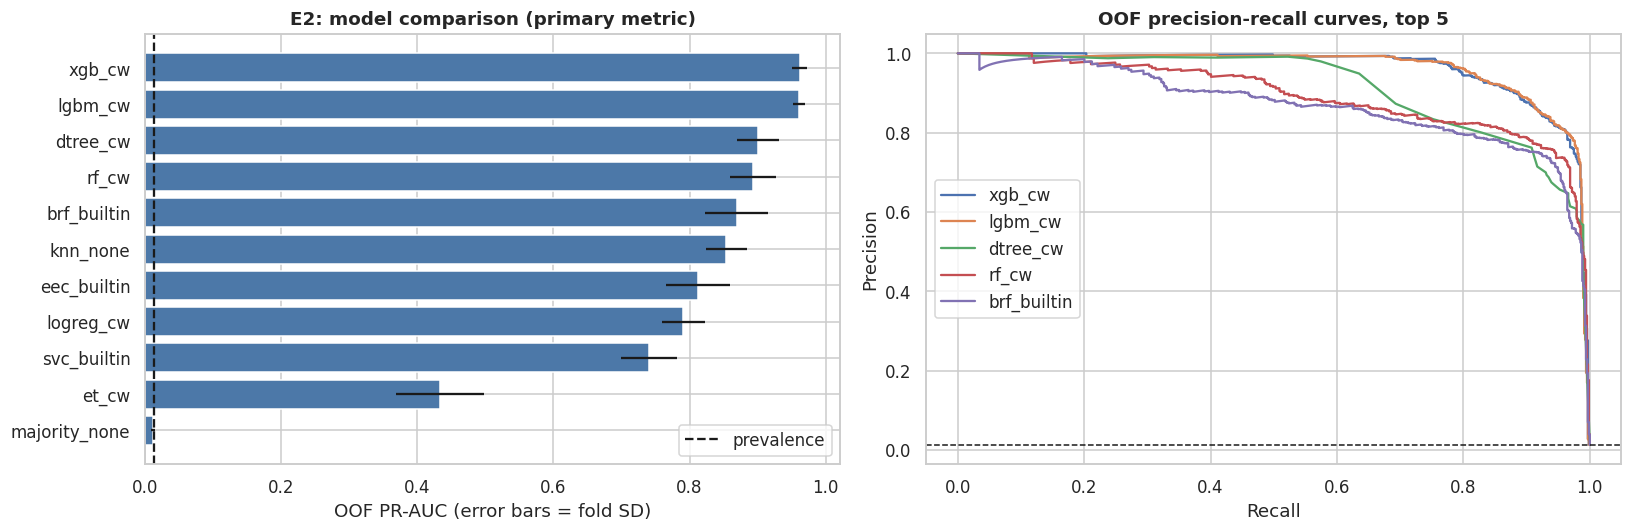

In [ ]:
t = registry_table('S1_models')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(t.exp_id.str.replace('S1_',''), t.pr_auc, xerr=t.ap_fold_sd, color='#4C78A8'); ax[0].axvline(y_dev.mean(), color='k', ls='--', label='prevalence'); ax[0].invert_yaxis()
ax[0].set_xlabel('OOF PR-AUC (error bars = fold SD)'); ax[0].set_title('E2: model comparison (primary metric)'); ax[0].legend()
for k in t.exp_id.head(5):
    p, r, _ = precision_recall_curve(y_dev, RES[k]['oof']); ax[1].plot(r, p, label=k.replace('S1_',''))
ax[1].axhline(y_dev.mean(), color='k', ls='--', lw=1); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('OOF precision-recall curves, top 5'); ax[1].legend()
plt.tight_layout(); savefig(fig, 'plots_cmp', 'e2_model_comparison')

**Read this table with care.** Differences smaller than the fold SD are not evidence of a better model. `apparent_pr_auc` (scored on the data the final refit saw) versus OOF PR-AUC exposes overfitting: a large gap for kNN, trees and forests is expected and is why OOF numbers are the ones reported. The ProSit's expected outcome is that boosting is slightly ahead of well-tuned logistic regression, possibly within noise.

### 6.2 E3: class-imbalance strategies (LR and LightGBM)
| Strategy | Mechanism | Caveat on this data |
|---|---|---|
| none | Unweighted loss; probabilities near the base rate | Ranking may still be fine; threshold must move |
| cw | Loss weights inversely proportional to class frequency (cost-sensitive learning) | Inflates predicted probabilities; calibrate before using cost thresholds |
| ros / rus | Duplicate minority / drop majority to a 1:5 ratio (`SAMPLING_RATIO`) | ROS can overfit duplicates; RUS discards information |
| smote / bsmote / adasyn | Interpolate synthetic minority points (optionally near the boundary or in hard regions) | One-hot columns are interpolated (not true categories); no SMOTE-NC used, a stated limitation |
| smote_tomek | SMOTE then remove Tomek links | Slow; run for LR only |

Resampling happens **inside each training fold** (imblearn `Pipeline`), never on validation folds. Full 1:1 balancing is deliberately not assumed to be optimal.

E3: imbalance strategies
  done S2_logreg_none                     PR-AUC=0.8326 (fold 0.8322+-0.0120) ROC=0.994 [6.1s]
  done S2_logreg_cw                       PR-AUC=0.7906 (fold 0.7917+-0.0315) ROC=0.995 [8.6s]
  done S2_logreg_ros                      PR-AUC=0.7974 (fold 0.7980+-0.0277) ROC=0.996 [9.9s]
  done S2_logreg_rus                      PR-AUC=0.7958 (fold 0.7944+-0.0272) ROC=0.997 [2.5s]
  done S2_logreg_smote                    PR-AUC=0.8036 (fold 0.8037+-0.0238) ROC=0.995 [9.6s]
  done S2_logreg_bsmote                   PR-AUC=0.7902 (fold 0.7927+-0.0259) ROC=0.995 [12.6s]
  done S2_logreg_adasyn                   PR-AUC=0.7957 (fold 0.7984+-0.0258) ROC=0.994 [11.8s]
  done S2_lgbm_none                       PR-AUC=0.9634 (fold 0.9650+-0.0086) ROC=0.998 [11.6s]
  done S2_lgbm_cw                         PR-AUC=0.9611 (fold 0.9632+-0.0087) ROC=0.997 [11.5s]
  done S2_lgbm_ros                        PR-AUC=0.9701 (fold 0.9708+-0.0115) ROC=0.998 [13.8s]
  done S2_lgbm_rus  

,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,top_precision,top_recall,top_fpr,f1opt_f1,dPR-AUC vs none,dBrier vs none
0,S2_lgbm_ros,0.9701,0.9708,0.0115,0.9977,0.0021,0.1284,0.9970,0.0883,0.9111,0.0067,0.0001
1,S2_lgbm_smote,0.9646,0.9662,0.0151,0.9975,0.0022,0.1282,0.9955,0.0883,0.8985,0.0012,0.0002
2,S2_lgbm_adasyn,0.9641,0.9662,0.0168,0.9974,0.0023,0.1282,0.9955,0.0883,0.9030,0.0007,0.0003
3,S2_lgbm_none,0.9634,0.9650,0.0086,0.9977,0.0019,0.1284,0.9970,0.0883,0.8982,0.0000,0.0000
4,S2_lgbm_bsmote,0.9631,0.9647,0.0170,0.9973,0.0022,0.1282,0.9955,0.0883,0.9029,-0.0003,0.0003
5,S2_lgbm_cw,0.9611,0.9632,0.0087,0.9972,0.0029,0.1284,0.9970,0.0883,0.8952,-0.0022,0.0010
6,S2_lgbm_rus,0.9318,0.9327,0.0175,0.9982,0.0051,0.1284,0.9970,0.0883,0.8622,-0.0315,0.0032
7,S2_logreg_none,0.8326,0.8322,0.0120,0.9938,0.0044,0.1272,0.9881,0.0884,0.7826,0.0000,0.0000
8,S2_logreg_smote,0.8036,0.8037,0.0238,0.9948,0.0069,0.1280,0.9941,0.0884,0.7883,-0.0290,0.0024
9,S2_logreg_smote_tomek,0.8007,0.8007,0.0221,0.9953,0.0069,0.1280,0.9941,0.0884,0.7879,-0.0318,0.0024


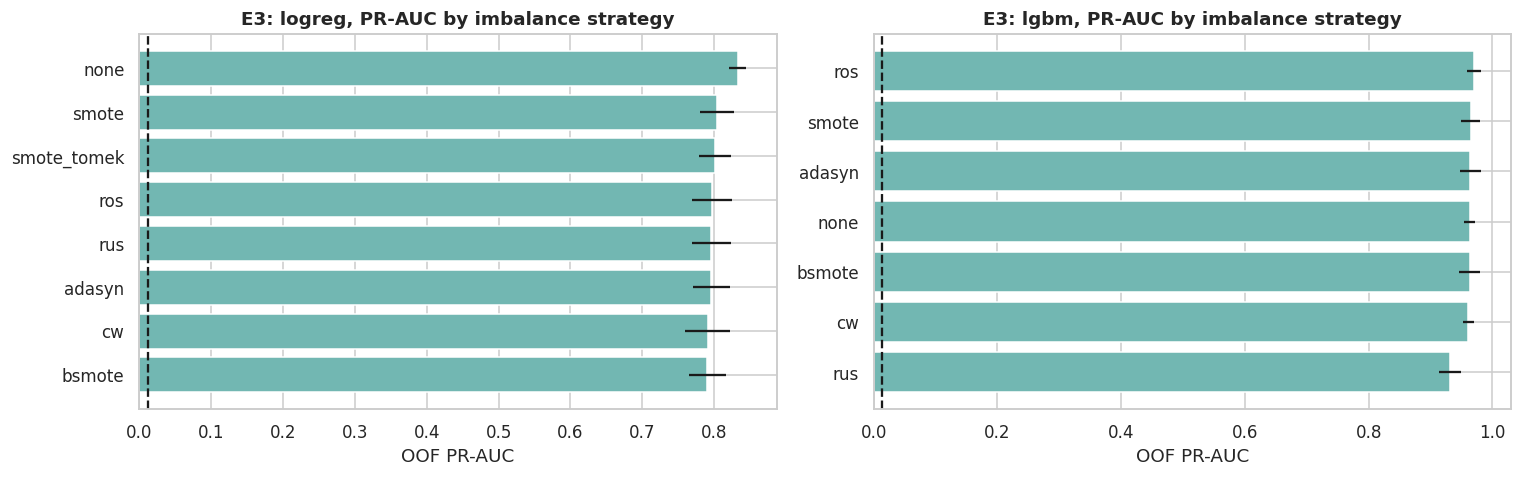

In [ ]:
print('E3: imbalance strategies')
STRATS = ['none', 'cw', 'ros', 'rus', 'smote', 'bsmote', 'adasyn']
if CFG['FAST']: STRATS = ['none', 'cw', 'rus', 'smote']
for m in ['logreg', 'lgbm']:
    for s in STRATS:
        run_exp(f'S2_{m}_{s}', 'S2_imbalance', m, s, ALL_CLF, ckpt='imb')
run_exp('S2_logreg_smote_tomek', 'S2_imbalance', 'logreg', 'smote_tomek', ALL_CLF, ckpt='imb') if not CFG['FAST'] else None
imb = registry_table('S2_imbalance')
base = imb.set_index('exp_id')
def delta(r):
    ref = base.loc[f"S2_{r.model}_none"]; return pd.Series({'dPR-AUC vs none': r.pr_auc - ref.pr_auc, 'dROC-AUC vs none': r.roc_auc - ref.roc_auc,
                                                         'dBrier vs none': r.brier - ref.brier})
imb = pd.concat([imb, imb.apply(delta, axis=1)], axis=1)
display(imb[['exp_id','pr_auc','ap_fold_mean','ap_fold_sd','roc_auc','brier','top_precision','top_recall','top_fpr','f1opt_f1','dPR-AUC vs none','dBrier vs none']].round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, m in zip(ax, ['logreg', 'lgbm']):
    d = imb[imb.model == m].sort_values('pr_auc'); a.barh(d.strategy, d.pr_auc, xerr=d.ap_fold_sd, color='#72B7B2'); a.axvline(y_dev.mean(), color='k', ls='--')
    a.set_title(f'E3: {m}, PR-AUC by imbalance strategy'); a.set_xlabel('OOF PR-AUC')
plt.tight_layout(); savefig(fig, 'plots_cmp', 'e3_imbalance_strategies')

**Interpretation guide.** Compare `dPR-AUC vs none` to the fold SD: if the difference is inside it, the strategy did not demonstrably help ranking. Resampling and class weights mostly change *calibration* (see `dBrier`), which is why Section 7 recalibrates before applying monetary thresholds. Report which strategy was selected **and** whether it beat the unmodified baseline beyond noise.

### 6.3 E4: hyperparameter optimisation
Randomised search, scoring = average precision, `StratifiedGroupKFold` seed A. The best imbalance strategy per model family (from E3, by OOF PR-AUC) is carried over for LR and LightGBM; tree and forest use class weights. After tuning, each tuned model is re-scored with the **independent fold seed B**. Search results are saved to `results/hyperparameter_results/`.

In [ ]:
def best_strategy(model):
    d = registry_table('S2_imbalance'); d = d[d.model == model]
    return d.iloc[0].strategy if len(d) else 'cw'
BEST_STRAT = {'logreg': best_strategy('logreg'), 'lgbm': best_strategy('lgbm'), 'dtree': 'cw', 'rf': 'cw'}
print('Imbalance strategy carried into tuning:', BEST_STRAT)

PARAM_DIST = {
 'logreg': {'clf__C': loguniform(1e-3, 1e2)},
 'dtree':  {'clf__max_depth': [3, 4, 5, 6, 8, 10], 'clf__min_samples_leaf': [20, 50, 100, 200], 'clf__ccp_alpha': [0, 1e-5, 1e-4, 5e-4]},
 'rf':     {'clf__min_samples_leaf': [5, 10, 20, 50], 'clf__max_features': ['sqrt', 0.3, 0.5], 'clf__max_depth': [None, 8, 12]},
 'lgbm':   {'clf__num_leaves': [7, 15, 31], 'clf__learning_rate': loguniform(0.01, 0.1), 'clf__n_estimators': F([150, 300, 500], [60, 100]),
            'clf__min_child_samples': [20, 50, 100, 200], 'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__reg_lambda': [0, 1, 10, 50]},
}
BEST_PARAMS = {}
for m in ['logreg', 'dtree', 'rf', 'lgbm']:
    jp = DIRS['hpo'] / f'best_{m}.json'
    if jp.exists(): BEST_PARAMS[m] = json.loads(jp.read_text()); print(f'  resumed {m}'); continue
    t0 = time.time()
    est = build_estimator(m, BEST_STRAT[m], ALL_CLF)
    rs = RandomizedSearchCV(est, PARAM_DIST[m], n_iter=CFG['N_ITER_TUNE'], scoring='average_precision', cv=FOLDS_A, random_state=SEED, n_jobs=1, refit=False, error_score='raise')
    rs.fit(X_dev, y_dev)
    cvr = pd.DataFrame(rs.cv_results_); cvr.to_csv(DIRS['hpo'] / f'search_{m}.csv', index=False)
    BEST_PARAMS[m] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in rs.best_params_.items()}
    jp.write_text(json.dumps(BEST_PARAMS[m], default=str))
    print(f'  tuned {m}: best search PR-AUC {rs.best_score_:.4f} (selection-optimistic) in {(time.time()-t0)/60:.1f} min -> {BEST_PARAMS[m]}')
for m in BEST_PARAMS:
    run_exp(f'S3_{m}_tuned', 'S3_tuned', m, BEST_STRAT[m], ALL_CLF, params=BEST_PARAMS[m], ckpt='opt')
tuned = registry_table('S3_tuned'); display(tuned[show[:-1] + ['params']].round(4))

Imbalance strategy carried into tuning: {'logreg': 'none', 'lgbm': 'ros', 'dtree': 'cw', 'rf': 'cw'}
  tuned logreg: best search PR-AUC 0.8476 (selection-optimistic) in 1.1 min -> {'clf__C': 56.69849511478853}
  tuned dtree: best search PR-AUC 0.9119 (selection-optimistic) in 0.7 min -> {'clf__min_samples_leaf': 100, 'clf__max_depth': 8, 'clf__ccp_alpha': 0}
  tuned rf: best search PR-AUC 0.9686 (selection-optimistic) in 19.4 min -> {'clf__min_samples_leaf': 5, 'clf__max_features': 0.5, 'clf__max_depth': None}
  tuned lgbm: best search PR-AUC 0.9738 (selection-optimistic) in 2.3 min -> {'clf__colsample_bytree': 0.9222669243390758, 'clf__learning_rate': 0.05588819841541484, 'clf__min_child_samples': 100, 'clf__n_estimators': 150, 'clf__num_leaves': 15, 'clf__reg_lambda': 0}
  done S3_logreg_tuned                    PR-AUC=0.8413 (fold 0.8418+-0.0195) ROC=0.991 [7.9s]
  done S3_dtree_tuned                     PR-AUC=0.9192 (fold 0.9062+-0.0246) ROC=0.995 [4.0s]
  done S3_rf_tuned        

,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,f1opt_precision,f1opt_recall,f1opt_f1,f1opt_mcc,f1opt_fpr,top_precision,top_recall,top_fpr,params
0,S3_lgbm_tuned,0.9694,0.9710,0.0110,0.9974,0.0022,0.9389,0.8887,0.9131,0.9124,0.0008,0.1280,0.9941,0.0884,"{""clf__colsample_bytree"": 0.9222669243390758, ..."
1,S3_rf_tuned,0.9653,0.9654,0.0110,0.9972,0.0023,0.9030,0.8843,0.8936,0.8922,0.0012,0.0129,1.0000,1.0000,"{""clf__min_samples_leaf"": 5, ""clf__max_feature..."
2,S3_dtree_tuned,0.9192,0.9062,0.0246,0.9951,0.0117,0.7947,0.8902,0.8397,0.8389,0.0030,0.0129,1.0000,1.0000,"{""clf__min_samples_leaf"": 100, ""clf__max_depth..."
3,S3_logreg_tuned,0.8413,0.8418,0.0195,0.9906,0.0042,0.7899,0.7864,0.7881,0.7853,0.0027,0.1259,0.9777,0.0886,"{""clf__C"": 56.69849511478853}"


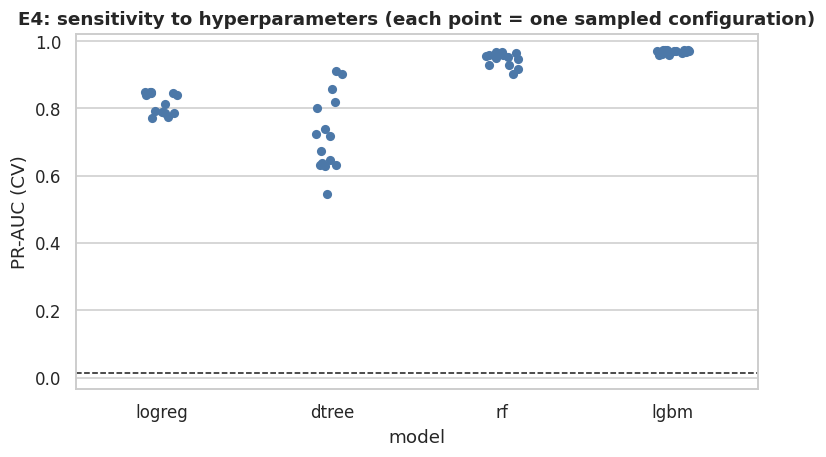

In [ ]:
# Sensitivity to hyperparameter choices: spread of search scores per model (seed-A folds)
fig, ax = plt.subplots(figsize=(8, 4.2)); data = []
for m in BEST_PARAMS:
    c = pd.read_csv(DIRS['hpo'] / f'search_{m}.csv'); data.append(pd.DataFrame({'model': m, 'PR-AUC (CV)': c['mean_test_score']}))
sns.stripplot(data=pd.concat(data), x='model', y='PR-AUC (CV)', ax=ax, size=6, color='#4C78A8'); ax.axhline(y_dev.mean(), color='k', ls='--', lw=1)
ax.set_title('E4: sensitivity to hyperparameters (each point = one sampled configuration)'); savefig(fig, 'plots_cmp', 'e4_hpo_sensitivity')

### 6.4 E6: is the best model meaningfully better than a simple one?
Fold-wise paired differences (same grouped folds) against the tuned logistic regression, plus a **one-standard-error parsimony rule**: if the simpler model's mean fold PR-AUC is within one SE of the best model's, prefer the simpler (the committee asks for models they can justify). This is a defensible heuristic, not a significance test; with `N_FOLDS` folds, a formal test has little power and fold scores are not independent.

In [ ]:
cand = {r.model: r.exp_id for r in registry_table('S3_tuned').itertuples()}
fa = pd.DataFrame({m: RES[e]['fold_ap'] for m, e in cand.items()})
ref = 'logreg'
paired = pd.DataFrame({m: fa[m] - fa[ref] for m in fa if m != ref}).agg(['mean', 'std']).T; paired.columns = [f'mean diff vs {ref}', 'sd of diff']
paired['folds better'] = [(fa[m] > fa[ref]).sum() for m in paired.index]; display(paired.round(4))
summ = fa.agg(['mean', 'std']).T; summ['se'] = summ['std'] / np.sqrt(len(fa)); display(summ.round(4))
best_m = summ['mean'].idxmax(); thr_se = summ.loc[best_m, 'mean'] - summ.loc[best_m, 'se']
simple_order = ['logreg', 'dtree', 'lgbm', 'rf']           # simplicity ranking (interpretability)
parsimony = next(m for m in simple_order if m in summ.index and summ.loc[m, 'mean'] >= thr_se)
FINAL_MODEL = CFG['FINAL_MODEL_OVERRIDE'] or parsimony
print(f'Best by mean fold PR-AUC: {best_m}. Simplest model within 1 SE of it: {parsimony}. Selected for deployment path: {FINAL_MODEL}')
FINAL_EXP = cand[FINAL_MODEL]

,mean diff vs logreg,sd of diff,folds better
lgbm,0.1291,0.0128,5
rf,0.1236,0.0129,5
dtree,0.0644,0.0152,5


,mean,std,se
lgbm,0.9710,0.0110,0.0049
rf,0.9654,0.0110,0.0049
dtree,0.9062,0.0246,0.0110
logreg,0.8418,0.0195,0.0087


Best by mean fold PR-AUC: lgbm. Simplest model within 1 SE of it: lgbm. Selected for deployment path: lgbm


### 6.5 E5: ablation of feature groups
Cumulative (add groups in order) and leave-one-group-out, for tuned LR and tuned LightGBM, same folds. This isolates the contribution of engineered features, history and, importantly, the **loan-term group**, which contains `Lender_portion_to_be_repaid` and the funding columns whose decision-time availability should be verified with the data owner.

  done S4_logreg_cum_+base                PR-AUC=0.1496 (fold 0.1519+-0.0320) ROC=0.642 [3.1s]
  done S4_logreg_cum_+calendar            PR-AUC=0.1538 (fold 0.1611+-0.0327) ROC=0.710 [4.1s]
  done S4_logreg_cum_+terms               PR-AUC=0.8354 (fold 0.8368+-0.0186) ROC=0.990 [5.7s]
  done S4_logreg_cum_+history             PR-AUC=0.8413 (fold 0.8418+-0.0195) ROC=0.991 [8.2s]
  done S4_logreg_loo_-calendar            PR-AUC=0.8369 (fold 0.8379+-0.0167) ROC=0.991 [6.8s]
  done S4_logreg_loo_-terms               PR-AUC=0.1643 (fold 0.1731+-0.0349) ROC=0.827 [7.8s]
  done S4_logreg_loo_-history             PR-AUC=0.8354 (fold 0.8368+-0.0186) ROC=0.990 [5.7s]
  done S4_lgbm_cum_+base                  PR-AUC=0.1484 (fold 0.1552+-0.0287) ROC=0.660 [4.8s]
  done S4_lgbm_cum_+calendar              PR-AUC=0.1616 (fold 0.1746+-0.0347) ROC=0.738 [5.5s]
  done S4_lgbm_cum_+terms                 PR-AUC=0.9687 (fold 0.9718+-0.0109) ROC=0.997 [6.7s]
  done S4_lgbm_cum_+history               PR-AUC=0

model,lgbm,logreg
setting,,
cum_+base,0.1484,0.1496
cum_+calendar,0.1616,0.1538
cum_+terms,0.9687,0.8354
cum_+history,0.9694,0.8413
loo_-calendar,0.9683,0.8369
loo_-terms,0.1817,0.1643
loo_-history,0.9687,0.8354


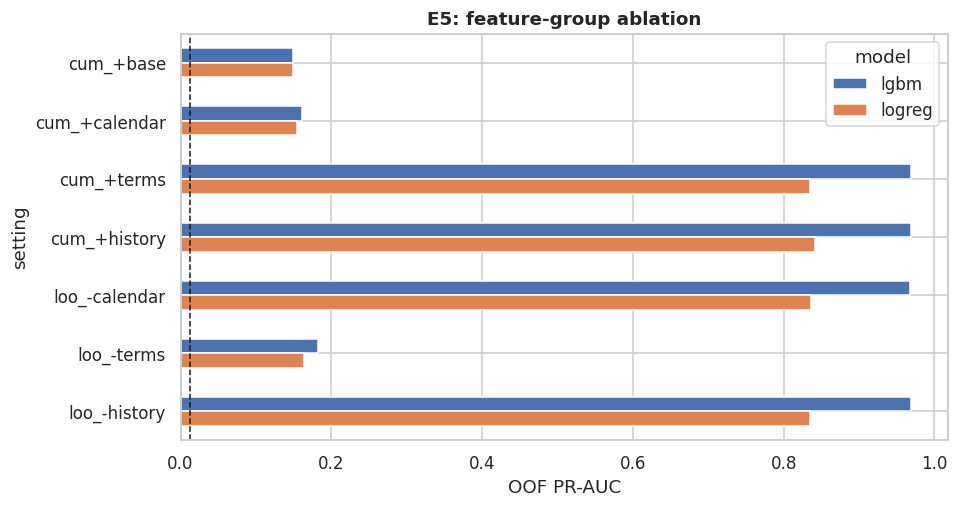

In [ ]:
order = [g for g in ['base', 'calendar', 'terms', 'history', 'macro'] if FEATURE_GROUPS[g]]
abl_sets = {}
acc = []
for g in order:
    acc += FEATURE_GROUPS[g]; abl_sets['cum_+' + g] = list(acc)
for g in order[1:]:
    abl_sets['loo_-' + g] = [c for gg in order if gg != g for c in FEATURE_GROUPS[gg]]
abl_models = ['logreg', 'lgbm']
for m in abl_models:
    for name, feats in abl_sets.items():
        run_exp(f'S4_{m}_{name}', 'S4_ablation', m, BEST_STRAT[m], feats, params=BEST_PARAMS[m], ckpt='abl')
ab = registry_table('S4_ablation')
ab['setting'] = ab.exp_id.str.replace(r'S4_(logreg|lgbm)_', '', regex=True)
piv = ab.pivot(index='setting', columns='model', values='pr_auc').reindex(list(abl_sets)); display(piv.round(4)); piv.to_csv(DIRS['results'] / 'ablation_feature_groups.csv')
fig, ax = plt.subplots(figsize=(9, 4.8)); piv.plot.barh(ax=ax); ax.axvline(y_dev.mean(), color='k', ls='--', lw=1); ax.invert_yaxis()
ax.set_xlabel('OOF PR-AUC'); ax.set_title('E5: feature-group ablation'); savefig(fig, 'plots_cmp', 'e5_ablation')

**What to extract:** (i) does `history` add signal beyond static loan attributes? (ii) how much does `terms` add, and would performance survive without `Lender_portion_to_be_repaid` if the data owner says it is post-repayment? (iii) are calendar and macro features worth their complexity? A group whose removal changes PR-AUC by less than the fold SD is not demonstrably useful.

## 7. Calibration, operating threshold and final test evaluation
### 7.1 E7: calibration (dev OOF only)
Class weights and resampling distort probabilities, but the cost rule `decline if p > FP/(FP+FN)` needs *calibrated* probabilities. Calibrators (Platt, isotonic) are compared by **cross-validated** Brier score and ECE on the dev OOF scores (calibrator fitted on other folds' OOF scores, evaluated on the held-out fold), so the comparison is not self-fulfilling.

,brier,ece,mean_pred,observed,pr_auc
raw,0.00225,0.00238,0.01518,0.01288,0.96940
platt,0.00168,0.00010,0.01289,0.01288,0.96714
isotonic,0.00170,0.00013,0.01290,0.01288,0.96290


Selected calibrator (lowest CV Brier): platt | note: isotonic can create ties and lower PR-AUC; PR-AUC change above shows the cost


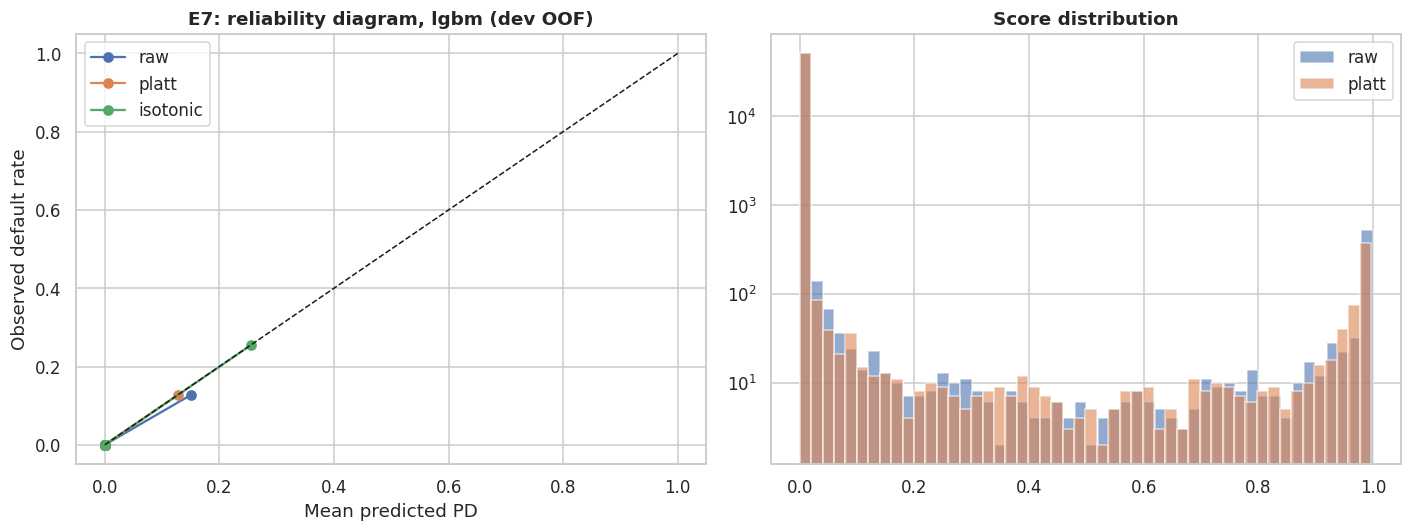

In [ ]:
def cv_calibrate(oof, y, method):
    out = np.full(len(oof), np.nan)
    for tr_i, va_i in FOLDS_B:
        out[va_i] = Calibrator(method).fit(oof[tr_i], y.iloc[tr_i]).predict(oof[va_i])
    return out

def calibration_report(exp_id):
    oof = RES[exp_id]['oof']; rows = {}
    cands = {'raw': oof, 'platt': cv_calibrate(oof, y_dev, 'platt'), 'isotonic': cv_calibrate(oof, y_dev, 'isotonic')}
    for k, p in cands.items():
        rows[k] = dict(brier=brier_score_loss(y_dev, np.clip(p, 0, 1)), ece=ece(y_dev, p), mean_pred=p.mean(), observed=y_dev.mean(), pr_auc=average_precision_score(y_dev, p))
    return pd.DataFrame(rows).T, cands

cal_tbl, cal_cands = calibration_report(FINAL_EXP); display(cal_tbl.round(5))
BEST_CAL = cal_tbl.loc[['platt', 'isotonic'], 'brier'].idxmin()
print('Selected calibrator (lowest CV Brier):', BEST_CAL, '| note: isotonic can create ties and lower PR-AUC; PR-AUC change above shows the cost')
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, p in cal_cands.items():
    fr, mp = calibration_curve(y_dev, np.clip(p, 0, 1), n_bins=10, strategy='quantile'); ax[0].plot(mp, fr, marker='o', label=k)
lim = max(0.05, min(1, cal_cands['isotonic'].max())); ax[0].plot([0, lim], [0, lim], 'k--', lw=1); ax[0].set_xlabel('Mean predicted PD'); ax[0].set_ylabel('Observed default rate')
ax[0].set_title(f'E7: reliability diagram, {FINAL_MODEL} (dev OOF)'); ax[0].legend()
ax[1].hist(cal_cands['raw'], bins=50, alpha=.6, label='raw'); ax[1].hist(cal_cands[BEST_CAL], bins=50, alpha=.6, label=BEST_CAL); ax[1].set_yscale('log'); ax[1].set_title('Score distribution'); ax[1].legend()
plt.tight_layout(); savefig(fig, 'plots_eval', 'e7_calibration_dev')

### 7.2 Operating threshold from the cost matrix (dev OOF, calibrated)
Decline when calibrated PD >= threshold. We pick the threshold that **minimises expected cost on dev OOF** subject to approving at least `MIN_APPROVAL_RATE` of applicants, and compare with the analytic threshold `p*`. Sensitivity: the optimum under zero and 40% recovery. **The test set is not used here.**

Analytic p* = 0.0252 | unconstrained cost-optimal thr = 0.1161 | chosen thr (approval >= 80%) = 0.1161
Dev OOF: approval 98.4%, recall 0.967, precision 0.802, expected cost 1,587,010 GHS vs approve-all 11,659,837 vs decline-all 10,414,031


,recovery,analytic_p_star,chosen_thr,approval,recall,cost_GHS,approve_all_cost_GHS
0,0.0,0.0206,0.1161,0.9845,0.9674,1759755.324,1.430980e+07
1,0.2,0.0252,0.1161,0.9845,0.9674,1587010.464,1.165984e+07
2,0.4,0.0323,0.1161,0.9845,0.9674,1414265.604,9.009874e+06


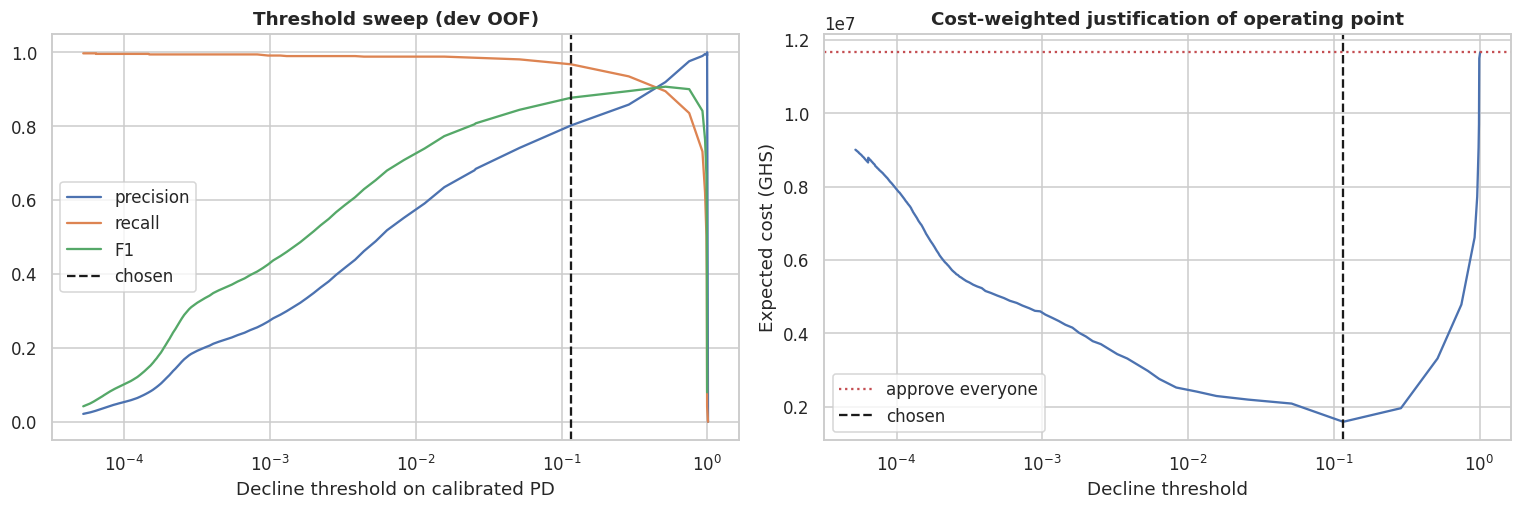

In [ ]:
def sweep(y, p, fn_c, fp_c, extra=()):
    y = np.asarray(y); grid = np.unique(np.concatenate([np.quantile(p, np.linspace(0.40, 0.9995, 400)), np.array(extra, float), [1.01]]))
    rows = []
    for t in grid:
        d = p >= t; tp = ((y == 1) & d).sum(); fp = ((y == 0) & d).sum()
        rows.append(dict(thr=t, decline_rate=d.mean(), approval=1 - d.mean(), cost=expected_cost(y, d, fn_c, fp_c),
                         precision=tp / max(d.sum(), 1), recall=tp / max((y == 1).sum(), 1), fpr=fp / max((y == 0).sum(), 1)))
    s = pd.DataFrame(rows); s['f1'] = 2 * s.precision * s.recall / (s.precision + s.recall).replace(0, np.nan); return s

def choose_threshold(sw, min_approval):
    ok = sw[sw.approval >= min_approval]; return float(ok.loc[ok.cost.idxmin(), 'thr'])

p_oof = cal_cands[BEST_CAL]
p_star = fp_dev.mean() / (fp_dev.mean() + fn_dev.mean())
sw = sweep(y_dev, p_oof, fn_dev, fp_dev, extra=[p_star])
THR = choose_threshold(sw, CFG['MIN_APPROVAL_RATE'])
THR_UNCONSTR = float(sw.loc[sw.cost.idxmin(), 'thr'])
cost_all = expected_cost(y_dev, np.zeros(len(y_dev), bool), fn_dev, fp_dev); cost_none = expected_cost(y_dev, np.ones(len(y_dev), bool), fn_dev, fp_dev)
r = sw[sw.thr == THR].iloc[0]
print(f'Analytic p* = {p_star:.4f} | unconstrained cost-optimal thr = {THR_UNCONSTR:.4f} | chosen thr (approval >= {CFG["MIN_APPROVAL_RATE"]:.0%}) = {THR:.4f}')
print(f'Dev OOF: approval {r.approval:.1%}, recall {r.recall:.3f}, precision {r.precision:.3f}, expected cost {r.cost*fx:,.0f} GHS vs approve-all {cost_all*fx:,.0f} vs decline-all {cost_none*fx:,.0f}')
sens = []
for rec in (0.0, CFG['RECOVERY_RATE'], 0.4):
    fn_s, fp_s = cost_vectors(dev, recovery=rec); s_ = sweep(y_dev, p_oof, fn_s, fp_s, extra=[fp_s.mean()/(fp_s.mean()+fn_s.mean())])
    t_ = choose_threshold(s_, CFG['MIN_APPROVAL_RATE']); rr = s_[s_.thr == t_].iloc[0]
    sens.append(dict(recovery=rec, analytic_p_star=fp_s.mean()/(fp_s.mean()+fn_s.mean()), chosen_thr=t_, approval=rr.approval, recall=rr.recall, cost_GHS=rr.cost*fx, approve_all_cost_GHS=expected_cost(y_dev, np.zeros(len(y_dev), bool), fn_s, fp_s)*fx))
sens = pd.DataFrame(sens); display(sens.round(4)); sens.to_csv(DIRS['results'] / 'operating_point_sensitivity.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(sw.thr, sw.precision, label='precision'); ax[0].plot(sw.thr, sw.recall, label='recall'); ax[0].plot(sw.thr, sw.f1, label='F1')
ax[0].axvline(THR, color='k', ls='--', label='chosen'); ax[0].set_xscale('log'); ax[0].set_xlabel('Decline threshold on calibrated PD'); ax[0].set_title('Threshold sweep (dev OOF)'); ax[0].legend()
ax[1].plot(sw.thr, sw.cost * fx); ax[1].axhline(cost_all * fx, color='r', ls=':', label='approve everyone'); ax[1].axvline(THR, color='k', ls='--', label='chosen')
ax[1].set_xscale('log'); ax[1].set_xlabel('Decline threshold'); ax[1].set_ylabel('Expected cost (GHS)'); ax[1].set_title('Cost-weighted justification of operating point'); ax[1].legend()
plt.tight_layout(); savefig(fig, 'plots_eval', 'threshold_cost_sweep_dev')

### 7.3 Final evaluation on the untouched test set (one shot)
The test set is scored for (a) the selected model, and two **pre-declared references**: (b) the majority baseline (approve everyone) and (c) the tuned logistic regression. No threshold, calibrator or hyper-parameter is changed after seeing these results. Confidence intervals use a **cluster bootstrap by customer**, because one borrower contributes several correlated loans.

In [ ]:
def operating_point(exp_id):
    # Calibrator and threshold are learned on dev OOF only; pipeline is the dev-refit checkpoint.
    ck = {'S3_logreg_tuned': CKPT['opt']}.get(exp_id, CKPT['opt'])
    pipe = joblib.load(ck / f'{exp_id}.model.joblib'); oof = RES[exp_id]['oof']
    cal_t, cands = calibration_report(exp_id); method = cal_t.loc[['platt', 'isotonic'], 'brier'].idxmin()
    p_o = cands[method]; sw_ = sweep(y_dev, p_o, fn_dev, fp_dev, extra=[p_star]); thr = choose_threshold(sw_, CFG['MIN_APPROVAL_RATE'])
    cal = Calibrator(method).fit(oof, y_dev)
    return dict(pipe=pipe, cal=cal, thr=thr, method=method, exp_id=exp_id)

fn_te, fp_te = cost_vectors(test); y_te = test['target'].values
OP = {'final': operating_point(FINAL_EXP), 'ref_logreg': operating_point('S3_logreg_tuned')}
for k, op in OP.items():
    op['s_test'] = get_score(op['pipe'], X_test); op['p_test'] = op['cal'].predict(op['s_test'])
TEST = {}
for k, op in OP.items():
    tf = threshold_free(y_te, op['p_test']); tf['pr_auc'] = average_precision_score(y_te, op['p_test'])
    mt = clf_metrics(y_te, op['p_test'], op['thr'], fn_te, fp_te); TEST[k] = {**tf, **mt, 'calibrator': op['method'], 'model': op['exp_id']}
TEST['majority_approve_all'] = {'pr_auc': float(y_te.mean()), 'roc_auc': 0.5, **clf_metrics(y_te, np.zeros(len(y_te)), 0.5, fn_te, fp_te), 'model': 'majority'}
tt = pd.DataFrame(TEST).T
cols = ['model','pr_auc','roc_auc','brier','thr','precision','recall','specificity','f1','f2','balanced_accuracy','mcc','fpr','fnr','flag_rate','accuracy','expected_cost']
tt_num = tt[cols].apply(lambda c: c if c.name in ('model',) else pd.to_numeric(c, errors='coerce')); display(tt_num.round(4)); tt.to_csv(DIRS['results'] / 'final_test_metrics.csv')
print(f"Approve-all expected cost on test: {TEST['majority_approve_all']['expected_cost']*fx:,.0f} GHS | final model: {TEST['final']['expected_cost']*fx:,.0f} GHS "
      f"(saving {100*(1-TEST['final']['expected_cost']/max(TEST['majority_approve_all']['expected_cost'],1e-9)):.1f}%)")
print('NOTE: accuracy of the majority baseline = %.3f; this is exactly why accuracy is not a selection metric.' % TEST['majority_approve_all']['accuracy'])

,model,pr_auc,roc_auc,brier,thr,precision,recall,specificity,f1,f2,balanced_accuracy,mcc,fpr,fnr,flag_rate,accuracy,expected_cost
final,S3_lgbm_tuned,0.6489,0.9497,0.0223,0.1161,0.5473,0.6079,0.9798,0.5760,0.5947,0.7938,0.5588,0.0202,0.3921,0.0430,0.9654,4.163227e+07
ref_logreg,S3_logreg_tuned,0.2460,0.7304,0.0374,0.2000,0.3580,0.3265,0.9764,0.3415,0.3323,0.6514,0.3166,0.0236,0.6735,0.0353,0.9513,7.706674e+07
majority_approve_all,majority,0.0387,0.5000,NaN,0.5000,0.0000,0.0000,1.0000,0.0000,0.0000,0.5000,0.0000,0.0000,1.0000,0.0000,0.9613,8.253179e+07


Approve-all expected cost on test: 82,531,793 GHS | final model: 41,632,275 GHS (saving 49.6%)
NOTE: accuracy of the majority baseline = 0.961; this is exactly why accuracy is not a selection metric.


In [ ]:
# ---- Cluster bootstrap by customer: 95% CI for PR-AUC and F1, paired difference vs reference LR, cost saving ----
rng = np.random.RandomState(SEED)
cust = test['customer_id'].values; uc, inv = np.unique(cust, return_inverse=True)
idx_by_c = [np.where(inv == i)[0] for i in range(len(uc))]
def boot(B=CFG['BOOT_B']):
    res = []
    for _ in range(B):
        pick = rng.randint(0, len(uc), len(uc)); ix = np.concatenate([idx_by_c[i] for i in pick]); yb = y_te[ix]
        if yb.sum() == 0: continue
        d = {}
        for k in ('final', 'ref_logreg'):
            p = OP[k]['p_test'][ix]; d[f'ap_{k}'] = average_precision_score(yb, p); d[f'f1_{k}'] = f1_score(yb, (p >= OP[k]['thr']).astype(int), zero_division=0)
            dec = p >= OP[k]['thr']; d[f'saving_{k}'] = expected_cost(yb, np.zeros(len(ix), bool), fn_te[ix], fp_te[ix]) - expected_cost(yb, dec, fn_te[ix], fp_te[ix])
        d['prev'] = yb.mean(); res.append(d)
    return pd.DataFrame(res)
bt = boot()
ci = lambda x: (np.percentile(x, 2.5), np.percentile(x, 97.5))
summary = []
for k in ('final', 'ref_logreg'):
    summary.append({'model': k, 'PR-AUC': TEST[k]['pr_auc'], 'PR-AUC 95% CI': tuple(np.round(ci(bt[f'ap_{k}']), 4)), 'F1': TEST[k]['f1'], 'F1 95% CI': tuple(np.round(ci(bt[f'f1_{k}']), 4)),
                    'cost saving vs approve-all (GHS) 95% CI': tuple(np.round(np.array(ci(bt[f'saving_{k}'])) * fx, 0))})
display(pd.DataFrame(summary))
dpa = bt['ap_final'] - bt['ap_ref_logreg']; df1 = bt['f1_final'] - bt['f1_ref_logreg']
print(f'Paired final - ref LR: dPR-AUC {dpa.mean():+.4f} CI {np.round(ci(dpa),4)} | dF1 {df1.mean():+.4f} CI {np.round(ci(df1),4)}')
lo_f1 = ci(bt['f1_final'])[0]; lo_ap = ci(bt['ap_final'])[0]
print(f'Beats majority baseline (F1=0) beyond the +-{CFG["NOISE_FLOOR"]} noise floor? {"YES" if lo_f1 > CFG["NOISE_FLOOR"] else "NO / not demonstrated"} (F1 CI lower bound {lo_f1:.4f})')
print(f'PR-AUC CI lower bound {lo_ap:.4f} vs prevalence {y_te.mean():.4f}: {"above" if lo_ap > y_te.mean() else "not above"} no-skill')
print('If the paired CI includes 0, the selected model is NOT distinguishable from the simple LR: report that plainly.')
bt.to_csv(DIRS['results'] / 'bootstrap_test.csv', index=False)

,model,PR-AUC,PR-AUC 95% CI,F1,F1 95% CI,cost saving vs approve-all (GHS) 95% CI
0,final,0.648886,"(0.5991, 0.6967)",0.576000,"(0.5279, 0.6235)","(14882542.0, 85440639.0)"
1,ref_logreg,0.245952,"(0.1958, 0.3048)",0.341511,"(0.2917, 0.3876)","(1976249.0, 9608878.0)"


Paired final - ref LR: dPR-AUC +0.4017 CI [0.3458 0.4529] | dF1 +0.2350 CI [0.1828 0.2893]
Beats majority baseline (F1=0) beyond the +-0.0263 noise floor? YES (F1 CI lower bound 0.5279)
PR-AUC CI lower bound 0.5991 vs prevalence 0.0387: above no-skill
If the paired CI includes 0, the selected model is NOT distinguishable from the simple LR: report that plainly.


**Second operating point (competition comparability).** The ProSit's leaderboard metric is F1, which rewards flagging more borrowers than the cost-optimal rule may. We therefore also report test F1 at the **F1-optimal threshold chosen on dev OOF** (still no test information used). This is an alternative reading of the same model, not a second chance: the cost-based threshold remains the deployment recommendation.

In [ ]:
thr_f1 = f1_opt_threshold(y_dev, p_oof); m_f1 = clf_metrics(y_te, OP['final']['p_test'], thr_f1, fn_te, fp_te)
rng2 = np.random.RandomState(SEED + 7); f1s = []
for _ in range(CFG['BOOT_B']):
    ix = np.concatenate([idx_by_c[i] for i in rng2.randint(0, len(uc), len(uc))])
    if y_te[ix].sum(): f1s.append(f1_score(y_te[ix], (OP['final']['p_test'][ix] >= thr_f1).astype(int), zero_division=0))
print(f"F1-optimal dev threshold {thr_f1:.4f}: test precision {m_f1['precision']:.3f}, recall {m_f1['recall']:.3f}, F1 {m_f1['f1']:.3f} (95% CI {np.round(ci(f1s), 3)}), decline rate {m_f1['flag_rate']:.2%}, cost {m_f1['expected_cost']*fx:,.0f} GHS")
print(f'Beats majority baseline (F1=0) beyond the noise floor of {CFG["NOISE_FLOOR"]}? {"YES" if ci(f1s)[0] > CFG["NOISE_FLOOR"] else "NO / not demonstrated"}')
TEST['final_f1opt'] = {**m_f1, 'model': FINAL_EXP}

F1-optimal dev threshold 0.6822: test precision 0.875, recall 0.289, F1 0.434 (95% CI [0.376 0.494]), decline rate 1.28%, cost 62,042,538 GHS
Beats majority baseline (F1=0) beyond the noise floor of 0.0263? YES


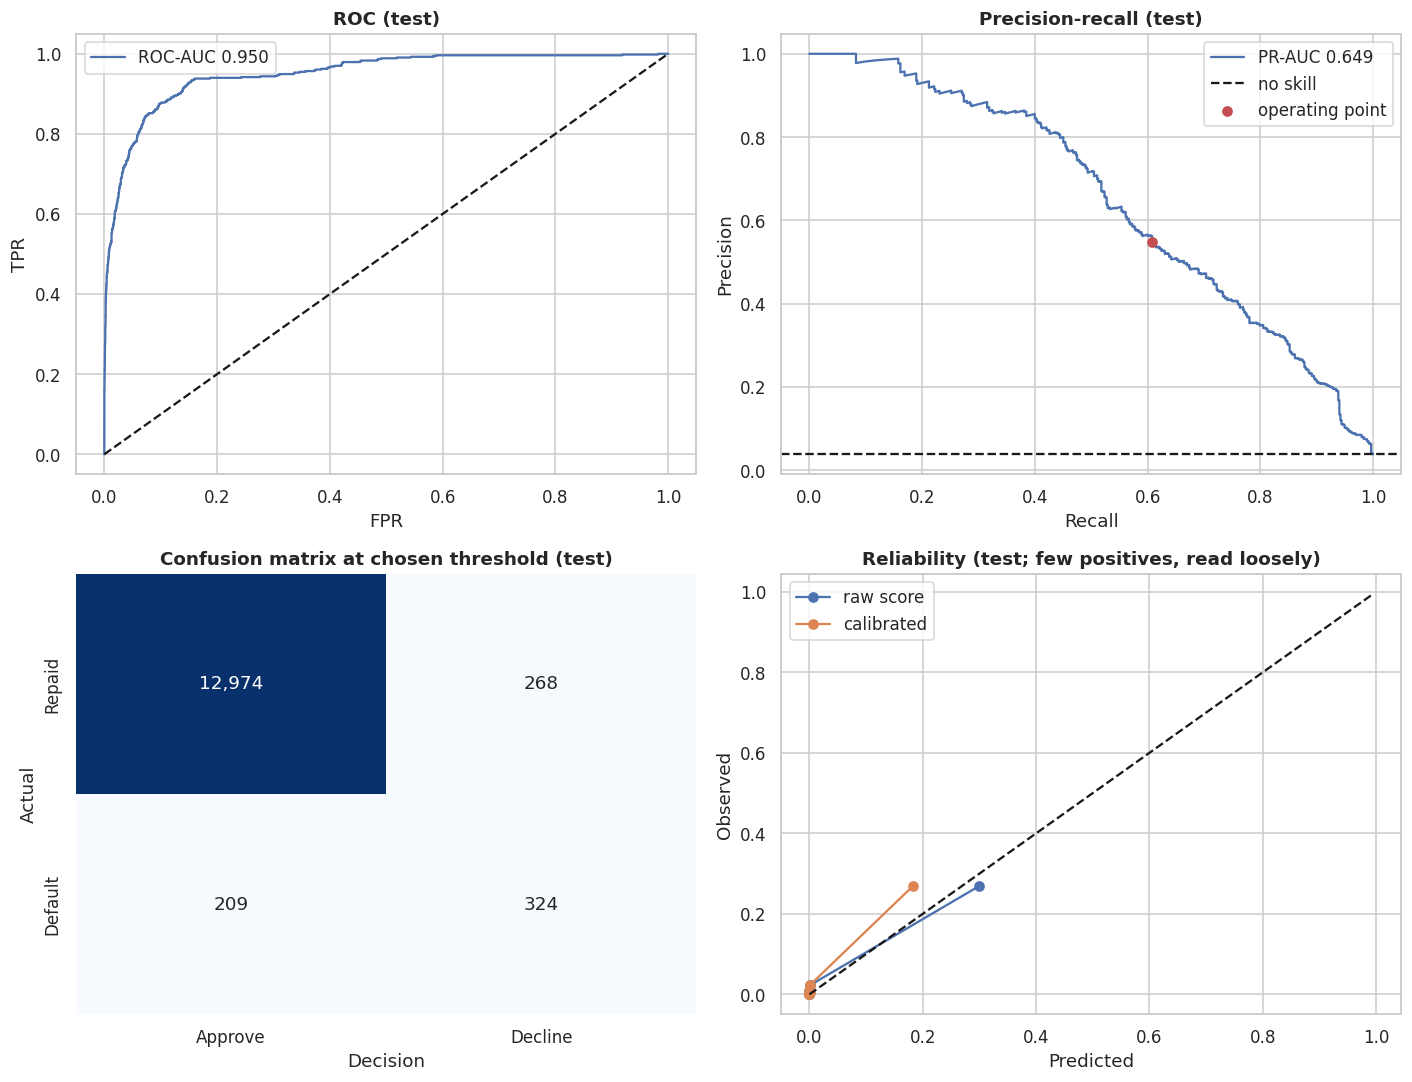

,PR-AUC
"train (refit, apparent)",0.9989
dev OOF (grouped CV),0.9694
test (temporal hold-out),0.6489


A large train-to-OOF gap indicates overfitting; an OOF-to-test drop indicates temporal drift or selection optimism.


In [ ]:
# ---- Test plots and generalisation (train vs OOF vs test) ----
op = OP['final']; p_te = op['p_test']
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
fpr_, tpr_, _ = roc_curve(y_te, p_te); ax[0,0].plot(fpr_, tpr_, label=f"ROC-AUC {TEST['final']['roc_auc']:.3f}"); ax[0,0].plot([0,1],[0,1],'k--'); ax[0,0].set_title('ROC (test)'); ax[0,0].set_xlabel('FPR'); ax[0,0].set_ylabel('TPR'); ax[0,0].legend()
pr_, rc_, _ = precision_recall_curve(y_te, p_te); ax[0,1].plot(rc_, pr_, label=f"PR-AUC {TEST['final']['pr_auc']:.3f}"); ax[0,1].axhline(y_te.mean(), color='k', ls='--', label='no skill')
ax[0,1].scatter([TEST['final']['recall']], [TEST['final']['precision']], c='r', zorder=5, label='operating point'); ax[0,1].set_title('Precision-recall (test)'); ax[0,1].set_xlabel('Recall'); ax[0,1].set_ylabel('Precision'); ax[0,1].legend()
cmx = np.array([[TEST['final']['tn'], TEST['final']['fp']], [TEST['final']['fn'], TEST['final']['tp']]])
sns.heatmap(cmx, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax[1,0], xticklabels=['Approve','Decline'], yticklabels=['Repaid','Default']); ax[1,0].set_title('Confusion matrix at chosen threshold (test)'); ax[1,0].set_ylabel('Actual'); ax[1,0].set_xlabel('Decision')
for nm, pp in [('raw score', op['s_test']), ('calibrated', p_te)]:
    fr, mp = calibration_curve(y_te, np.clip(pp, 0, 1), n_bins=8, strategy='quantile'); ax[1,1].plot(mp, fr, marker='o', label=nm)
mx = max(0.05, float(np.clip(p_te, 0, 1).max())); ax[1,1].plot([0, mx], [0, mx], 'k--'); ax[1,1].set_title('Reliability (test; few positives, read loosely)'); ax[1,1].set_xlabel('Predicted'); ax[1,1].set_ylabel('Observed'); ax[1,1].legend()
plt.tight_layout(); savefig(fig, 'plots_eval', 'final_model_test_evaluation')
gen = pd.DataFrame({'PR-AUC': [RES[FINAL_EXP]['row']['apparent_pr_auc'], RES[FINAL_EXP]['row']['pr_auc'], TEST['final']['pr_auc']]}, index=['train (refit, apparent)', 'dev OOF (grouped CV)', 'test (temporal hold-out)'])
display(gen.round(4)); print('A large train-to-OOF gap indicates overfitting; an OOF-to-test drop indicates temporal drift or selection optimism.')
gen.to_csv(DIRS['results'] / 'generalisation_gap.csv')

## 8. Task 1: loan-amount regression (limit setting)
**Target:** `log1p(Total_Amount)` (amounts are right-skewed). **Features:** the *shared* set (base, calendar, history, macro). `Total_Amount_to_Repay`, funding amounts and every fee/term column are excluded because they are deterministic functions of the target. Same dev/test split and grouped folds as Task 2. Models: mean baseline, OLS, Ridge, Lasso, Random Forest, LightGBM, SVR (subsample). Ridge/Lasso penalties are chosen on fold seed A; reported scores use seed B.

In [ ]:
REG_FEATS = SHARED
ylog_dev, ylog_te = np.log1p(dev['Total_Amount'].values), np.log1p(test['Total_Amount'].values)
def reg_metrics(yl, pl):
    yo, po = np.expm1(yl), np.clip(np.expm1(pl), 0, None)
    return dict(rmse_log=float(np.sqrt(mean_squared_error(yl, pl))), mae_log=float(mean_absolute_error(yl, pl)),
                rmse_orig=float(np.sqrt(mean_squared_error(yo, po))), mae_orig=float(mean_absolute_error(yo, po)),
                r2_log=float(1 - np.sum((yl - pl) ** 2) / np.sum((yl - yl.mean()) ** 2)))
def reg_est(name, alpha=None):
    reg = {'mean': DummyRegressor(strategy='mean'), 'ols': LinearRegression(), 'ridge': Ridge(alpha=alpha or 10.0),
           'lasso': Lasso(alpha=alpha or 1e-3, max_iter=10000),
           'rf': RandomForestRegressor(n_estimators=F(200, 40), min_samples_leaf=10, n_jobs=-1, random_state=SEED),
           'lgbm': lgb.LGBMRegressor(n_estimators=F(400, 80), learning_rate=0.05, num_leaves=31, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1),
           'svr': SubsampledRegressor(SVR(C=1.0, epsilon=0.1), max_n=min(CFG['MAX_SVC_ROWS'], 8000), seed=SEED)}[name]
    return Pipeline([('prep', make_preprocessor(REG_FEATS)), ('reg', reg)])
def reg_cv(name, folds, alpha=None):
    oof = np.zeros(len(ylog_dev))
    for tr_i, va_i in folds:
        e = reg_est(name, alpha).fit(X_dev.iloc[tr_i], ylog_dev[tr_i]); oof[va_i] = e.predict(X_dev.iloc[va_i])
    return oof
ALPHAS = {'ridge': [0.1, 1, 10, 100], 'lasso': [1e-4, 1e-3, 1e-2]}
best_alpha = {}
for m, grid in ALPHAS.items():
    sc = {a: reg_metrics(ylog_dev, reg_cv(m, FOLDS_A, a))['rmse_log'] for a in grid}; best_alpha[m] = min(sc, key=sc.get); print(f'{m}: alpha search (seed-A folds) {sc} -> {best_alpha[m]}')
REG_RES, REG_OOF = [], {}
for name in ['mean', 'ols', 'ridge', 'lasso', 'rf', 'lgbm', 'svr']:
    mp = DIRS['ckpt_reg'] / f'{name}.joblib'
    oof = reg_cv(name, FOLDS_B, best_alpha.get(name)); REG_OOF[name] = oof
    if not mp.exists(): joblib.dump(reg_est(name, best_alpha.get(name)).fit(X_dev, ylog_dev), mp)
    REG_RES.append({'model': name, **reg_metrics(ylog_dev, oof)}); print('  done', name)
reg_tab = pd.DataFrame(REG_RES).set_index('model').sort_values('rmse_log'); display(reg_tab.round(4)); reg_tab.to_csv(DIRS['results'] / 'regression_cv_results.csv')

ridge: alpha search (seed-A folds) {0.1: 1.1049154727790518, 1: 1.104890422597251, 10: 1.104794269570596, 100: 1.1063362585897665} -> 10
lasso: alpha search (seed-A folds) {0.0001: 1.1048988876052719, 0.001: 1.1055316990333228, 0.01: 1.1163672759207786} -> 0.0001
  done mean
  done ols
  done ridge
  done lasso
  done rf
  done lgbm
  done svr


,rmse_log,mae_log,rmse_orig,mae_orig,r2_log
model,,,,,
lgbm,0.8507,0.6263,1.999871e+04,6.131833e+03,0.5262
rf,0.8562,0.6294,1.984402e+04,6.110728e+03,0.5201
svr,0.9212,0.6765,2.225920e+04,6.482283e+03,0.4445
ridge,1.1014,0.8493,3.891567e+11,2.742530e+09,0.2059
lasso,1.1015,0.8489,3.816686e+11,2.693652e+09,0.2057
ols,1.1016,0.8488,3.813160e+11,2.682586e+09,0.2056
mean,1.2363,0.9771,2.609975e+04,8.801770e+03,-0.0005


,rmse_log,mae_log,rmse_orig,mae_orig,r2_log
mean,1.3509,0.9728,247147.6781,22184.3245,-0.0220
lgbm,0.7236,0.4874,238648.3713,15534.6269,0.7068


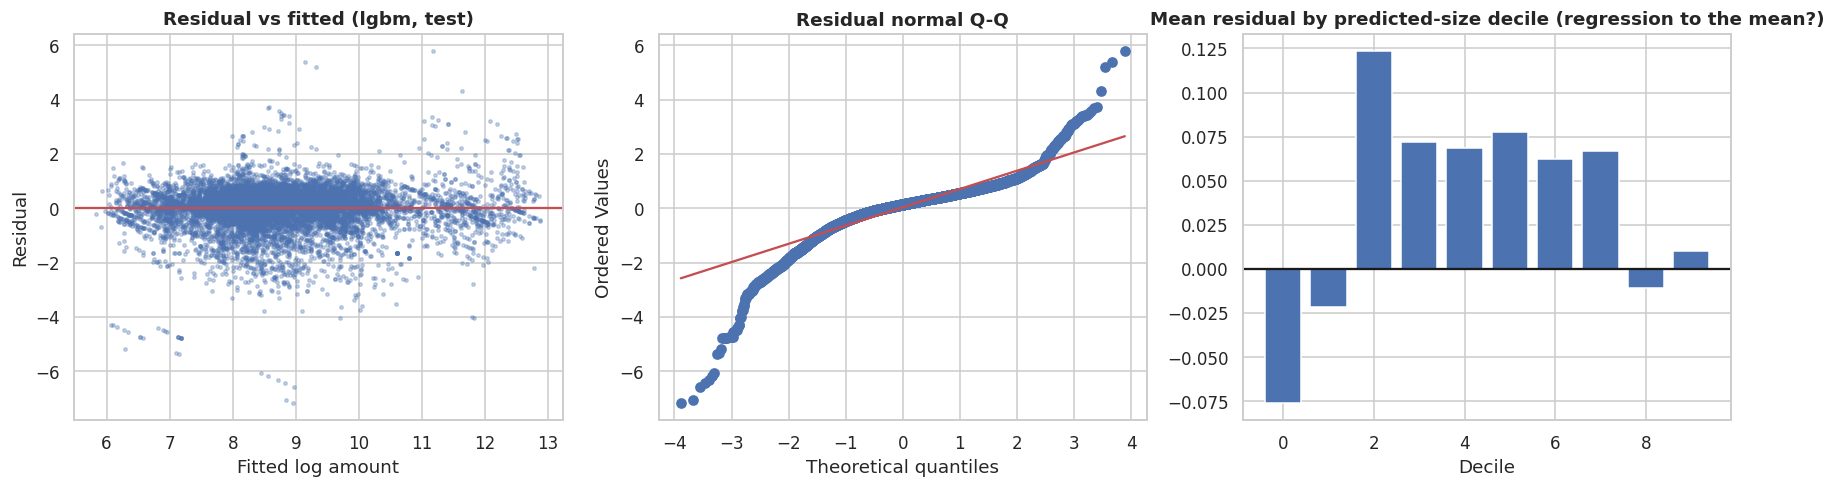

Heteroscedasticity check (corr of |residual| with fitted): 0.069
Use for limits: a conservative limit can be set from a lower prediction quantile; residual SD on the log scale = 0.723


In [ ]:
# One-shot test evaluation: mean baseline and the best model by OOF RMSE(log)
BEST_REG = reg_tab.index[0] if reg_tab.index[0] != 'mean' else reg_tab.index[1]
pipes = {n: joblib.load(DIRS['ckpt_reg'] / f'{n}.joblib') for n in ('mean', BEST_REG)}
pred_te = {n: p.predict(X_test) for n, p in pipes.items()}
reg_test = pd.DataFrame({n: reg_metrics(ylog_te, pr) for n, pr in pred_te.items()}).T; display(reg_test.round(4)); reg_test.to_csv(DIRS['results'] / 'regression_test_results.csv')
res = ylog_te - pred_te[BEST_REG]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(pred_te[BEST_REG], res, s=5, alpha=.3); ax[0].axhline(0, color='r'); ax[0].set_xlabel('Fitted log amount'); ax[0].set_ylabel('Residual'); ax[0].set_title(f'Residual vs fitted ({BEST_REG}, test)')
stats.probplot(res, plot=ax[1]); ax[1].set_title('Residual normal Q-Q')
bands = pd.qcut(pred_te[BEST_REG], 10, duplicates='drop'); rb = pd.Series(res).groupby(bands).mean(); ax[2].bar(range(len(rb)), rb.values); ax[2].axhline(0, color='k'); ax[2].set_title('Mean residual by predicted-size decile (regression to the mean?)'); ax[2].set_xlabel('Decile')
plt.tight_layout(); savefig(fig, 'plots_eval', 'regression_diagnostics')
print('Heteroscedasticity check (corr of |residual| with fitted): %.3f' % np.corrcoef(np.abs(res), pred_te[BEST_REG])[0, 1])
print('Use for limits: a conservative limit can be set from a lower prediction quantile; residual SD on the log scale = %.3f' % res.std())

**Interpretation guide.** If RMSE(log) barely improves on the mean baseline, loan size is mostly *chosen by the product/lender*, not predictable from the borrower, and a model-based limit adds little: say so. Systematic residual patterns by size decile (over-predicting small loans, under-predicting large) mean limits would be regressive for small borrowers.

## 9. Explainability and reason codes (Task 2 final model)
Global: coefficients (if linear), permutation importance (grouped by raw feature, PR-AUC drop, computed on the test set **after** all selection, as a post-hoc diagnostic), and SHAP for tree models. Local: top-3 risk-increasing contributions per applicant, mapped to plain-language reasons. For logistic regression, a feature's contribution is `coefficient x standardised value` (log-odds relative to an average applicant); for trees, SHAP values aggregated by raw column.

,feature,perm_importance,sd,group,mean_abs_contribution
12,fee_rate,0.5466,0.0042,terms,2.0872
13,daily_fee_rate,0.1669,0.0062,terms,0.3111
15,lender_repay_share,0.0240,0.0042,terms,0.1337
17,amount_vs_prior_mean,0.0225,0.0045,terms,0.1126
1,loan_type,0.0178,0.0027,base,0.0322
3,New_versus_Repeat,0.0073,0.0013,base,0.0441
2,lender_id,0.0058,0.0024,base,0.0394
23,n_resolved_prior,0.0054,0.0013,history,0.0443
11,log_amount,0.0050,0.0074,terms,0.3312
21,prior_mean_amount,0.0045,0.0014,history,0.0775


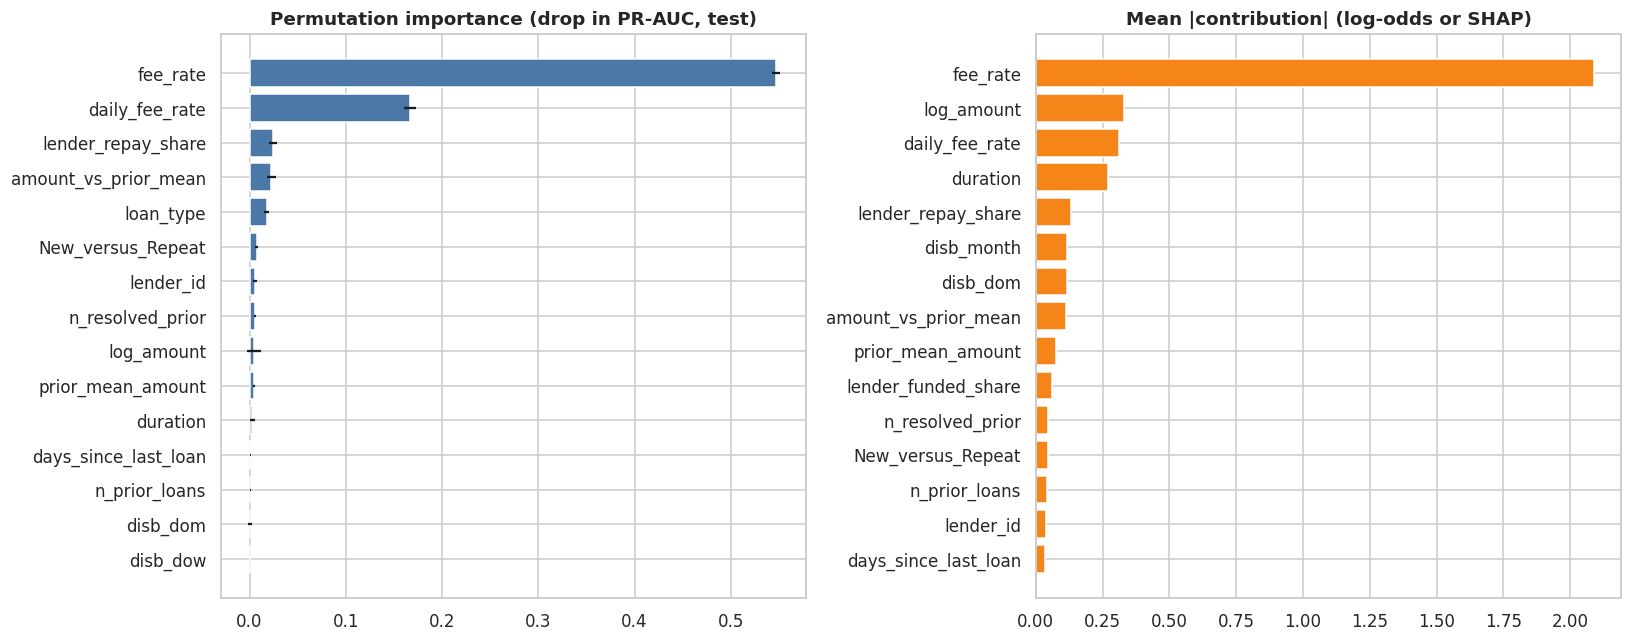

Importance share by feature group:
 group
base        0.099
calendar    0.067
history     0.058
terms       0.776


In [ ]:
FINAL_FEATS = RES[FINAL_EXP]['feats']
pipe_f = OP['final']['pipe']; prep_f = pipe_f.named_steps['prep']; clf_f = pipe_f.named_steps['clf']
fn_names = list(prep_f.get_feature_names_out())

def contributions(pipe, Xdf):
    # Per-applicant contributions (log-odds scale) aggregated to RAW columns. Works for linear and tree models.
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']; Xt = prep.transform(Xdf[FINAL_FEATS]); names = list(prep.get_feature_names_out())
    if hasattr(clf, 'coef_'): C = Xt * clf.coef_.ravel()
    else:
        import shap
        sv = shap.TreeExplainer(clf).shap_values(Xt)
        sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv); C = np.asarray(sv)
    cdf = pd.DataFrame(C, columns=names).T.groupby(lambda n: source_col(n, FINAL_FEATS)).sum().T
    cdf.index = Xdf.index; return cdf

group_of = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
# --- permutation importance (raw columns), post-hoc on test ---
pi = permutation_importance(pipe_f, X_test[FINAL_FEATS], y_te, scoring='average_precision', n_repeats=F(5, 2), random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'feature': FINAL_FEATS, 'perm_importance': pi.importances_mean, 'sd': pi.importances_std}); imp['group'] = imp.feature.map(group_of)
sub = test.sample(min(2000, len(test)), random_state=SEED); cs = contributions(pipe_f, sub)
imp = imp.merge(cs.abs().mean().rename('mean_abs_contribution').rename_axis('feature').reset_index(), on='feature', how='left').sort_values('perm_importance', ascending=False)
imp.to_csv(DIRS['results'] / 'feature_importance.csv', index=False); display(imp.head(15).round(4))
fig, ax = plt.subplots(1, 2, figsize=(15, 6)); top = imp.head(15).iloc[::-1]
ax[0].barh(top.feature, top.perm_importance, xerr=top.sd, color='#4C78A8'); ax[0].set_title('Permutation importance (drop in PR-AUC, test)')
tc = imp.sort_values('mean_abs_contribution', ascending=False).head(15).iloc[::-1]; ax[1].barh(tc.feature, tc.mean_abs_contribution, color='#F58518'); ax[1].set_title('Mean |contribution| (log-odds or SHAP)')
plt.tight_layout(); savefig(fig, 'plots_expl', 'global_importance')
print('Importance share by feature group:\n', imp.groupby('group')['mean_abs_contribution'].sum().pipe(lambda s: (s / s.sum()).round(3)).to_string())
if hasattr(clf_f, 'coef_'):
    co = pd.DataFrame({'feature': fn_names, 'coef': clf_f.coef_.ravel()}); co['odds_ratio_per_SD'] = np.exp(co.coef); co = co.reindex(co.coef.abs().sort_values(ascending=False).index)
    display(co.head(15).round(4)); co.to_csv(DIRS['results'] / 'logreg_coefficients.csv', index=False)

In [ ]:
# Local explanations -> plain-language reason codes (also used by the scoring service)
REASONS = {
 'duration': 'The repayment period you requested is short or long relative to similar loans.',
 'loan_type': 'The type of loan you applied for has had higher repayment difficulty.',
 'lender_id': 'Loans from this lender have had higher repayment difficulty.',
 'New_versus_Repeat': 'You are a first-time borrower, so we have little repayment history to rely on.',
 'n_prior_loans': 'The number of previous loans on your record.',
 'no_prior_loans': 'We have no earlier loan record for you.',
 'days_since_last_loan': 'The time since your last loan.',
 'prior_mean_amount': 'The size of your earlier loans compared with this one.',
 'last_amount': 'The size of your most recent loan compared with this one.',
 'n_resolved_prior': 'The number of earlier loans that have already been repaid or closed.',
 'n_prior_defaults': 'A previous loan was not repaid on time.',
 'prior_default_rate': 'A previous loan was not repaid on time.',
 'log_amount': 'The amount requested is high for this type of loan.',
 'fee_rate': 'The total cost of this loan is high relative to the amount borrowed.',
 'daily_fee_rate': 'The daily cost of this loan is high because the term is short.',
 'amount_vs_prior_mean': 'This loan is much larger than your earlier loans.',
 'lender_funded_share': 'The share of the loan funded by the lender.', 'lender_repay_share': 'The share of the repayment owed to the lender.',
 'Lender_portion_Funded': 'The share of the loan funded by the lender.',
}
def reason_text(col): return REASONS.get(col, 'Your application pattern (' + col.replace('_', ' ') + ') is associated with higher repayment difficulty.' if not col.startswith('disb') and not col.startswith('due') else 'The timing of the loan (day or month) is associated with higher repayment difficulty.')
def top_reasons(contrib_row, k=3):
    pos = contrib_row[contrib_row > 0].sort_values(ascending=False).head(k)
    return [(c, float(v), reason_text(c)) for c, v in pos.items()]
cs_all = contributions(pipe_f, test); idx_hi = int(np.argmax(OP['final']['p_test'])); idx_lo = int(np.argmin(OP['final']['p_test']))
for lab_, ix in [('Highest-risk test applicant', idx_hi), ('Lowest-risk test applicant', idx_lo)]:
    print(f"\n{lab_}: PD = {OP['final']['p_test'][ix]:.3f} ({'DECLINE' if OP['final']['p_test'][ix] >= OP['final']['thr'] else 'APPROVE'})")
    for c, v, t in top_reasons(cs_all.iloc[ix]): print(f'   [{v:+.3f}] {c}: {t}')


Highest-risk test applicant: PD = 0.995 (DECLINE)
   [+11.953] fee_rate: The total cost of this loan is high relative to the amount borrowed.
   [+1.651] daily_fee_rate: The daily cost of this loan is high because the term is short.
   [+0.395] log_amount: The amount requested is high for this type of loan.

Lowest-risk test applicant: PD = 0.000 (APPROVE)
   [+0.054] due_dow: The timing of the loan (day or month) is associated with higher repayment difficulty.
   [+0.018] disb_dow: The timing of the loan (day or month) is associated with higher repayment difficulty.
   [+0.011] daily_fee_rate: The daily cost of this loan is high because the term is short.


**Is the model defensible?** Check three things in the outputs above: (1) do history and loan-term features dominate, as credit logic would suggest, or does `lender_id` (an operational identifier, a possible proxy for customer segments) dominate? (2) do engineered features carry weight, or does the model ignore them (compare with Ablation E5)? (3) do reasons reference only features a borrower can understand and, in principle, change? Reasons built from `lender_id` or calendar features are weak explanations for a declined borrower and should be reworded or suppressed in the explainer.

## 10. Cross-market transfer: Kenya to Ghana (ProSit Part C)
Ghana has **no labels**, so performance cannot be measured; we can only measure *how different* Ghana applications are and what the Kenyan model does to them. Tools: feature-distribution comparison (PSI, KS), a **domain classifier** (can we tell Kenya from Ghana?), **importance weights** from that classifier, and the score distribution of the final model on both markets. Test.csv rows are featurised with history from Train outcomes only.

In [ ]:
tst = test_raw.copy()
tst = tst.dropna(subset=['customer_id', 'disbursement_date'])
if 'due_date' not in tst or tst['due_date'].isna().any():
    tst['due_date'] = tst['due_date'].fillna(tst['disbursement_date'] + pd.to_timedelta(tst['duration'], unit='D')) if 'due_date' in tst else tst['disbursement_date'] + pd.to_timedelta(tst['duration'], unit='D')
for c in CAT_COLS: tst[c] = tst[c].fillna('missing').astype(str)
tst_f = make_features(tst.reset_index(drop=True), lab)
cn = tst_f['country_id'].astype(str); gh = [c for c in cn.unique() if 'gh' in c.lower()]
GHANA = gh[0] if gh else cn.value_counts().index[-1]
tst_f['market'] = np.where(cn == GHANA, 'Ghana', 'Kenya')
print(f'Ghana identified as country_id = {GHANA!r} (heuristic: name contains "gh", else the smaller market). Verify this against the data!')
print(tst_f['market'].value_counts().to_dict())
G, K_te = tst_f[tst_f.market == 'Ghana'], tst_f[tst_f.market == 'Kenya']
assert len(G) > 50, 'Too few Ghana rows identified; fix GHANA assignment'

def psi(a, b, bins=10, cat=False):
    if cat:
        pa, pb = a.value_counts(normalize=True), b.value_counts(normalize=True); k = pa.index.union(pb.index)
        pa, pb = pa.reindex(k).fillna(0) + 1e-4, pb.reindex(k).fillna(0) + 1e-4
    else:
        e = np.unique(np.nanquantile(a.dropna(), np.linspace(0, 1, bins + 1))); e[0], e[-1] = -np.inf, np.inf
        pa = np.histogram(a.dropna(), e)[0] / max(a.notna().sum(), 1) + 1e-4; pb = np.histogram(b.dropna(), e)[0] / max(b.notna().sum(), 1) + 1e-4
    return float(np.sum((pb - pa) * np.log(pb / pa)))
STATIC = [c for c in FEATURE_GROUPS['base'] + FEATURE_GROUPS['terms'] + FEATURE_GROUPS['calendar'] if c not in ('amount_vs_prior_mean',) and c in feat_df.columns]
rows = []
for c in STATIC:
    isc = c in CAT_COLS; r_ = {'feature': c, 'PSI (Kenya dev -> Ghana)': psi(dev[c], G[c], cat=isc)}
    if not isc: r_['KS stat'] = stats.ks_2samp(dev[c].dropna(), G[c].dropna()).statistic
    rows.append(r_)
shift = pd.DataFrame(rows).sort_values('PSI (Kenya dev -> Ghana)', ascending=False); shift['reading'] = pd.cut(shift.iloc[:, 1], [-1, .1, .25, 1e9], labels=['stable', 'moderate shift', 'major shift'])
display(shift.round(3)); shift.to_csv(DIRS['results'] / 'transfer_feature_shift.csv', index=False)
for c in ['lender_id', 'loan_type']:
    seen = G[c].isin(set(dev[c])).mean(); print(f'Share of Ghana rows whose {c} also exists in Kenya training data: {100*seen:.1f}%')
print('Ghana customers with any prior loan in Train history: %.1f%% (Kenya test: %.1f%%)' % (100 * (G.n_prior_loans > 0).mean(), 100 * (K_te.n_prior_loans > 0).mean()))

Ghana identified as country_id = 'Ghana' (heuristic: name contains "gh", else the smaller market). Verify this against the data!
{'Kenya': 15069, 'Ghana': 3525}


,feature,PSI (Kenya dev -> Ghana),KS stat,reading
1,loan_type,17.657,NaN,major shift
2,lender_id,17.032,NaN,major shift
8,lender_repay_share,5.786,0.644,major shift
5,fee_rate,5.437,0.776,major shift
7,lender_funded_share,4.744,0.654,major shift
9,Lender_portion_Funded,4.732,0.654,major shift
6,daily_fee_rate,4.409,0.674,major shift
10,disb_month,1.615,0.361,major shift
11,disb_quarter,1.224,0.361,major shift
4,log_amount,0.771,0.232,major shift


Share of Ghana rows whose lender_id also exists in Kenya training data: 3.3%
Share of Ghana rows whose loan_type also exists in Kenya training data: 12.7%
Ghana customers with any prior loan in Train history: 0.0% (Kenya test: 89.6%)


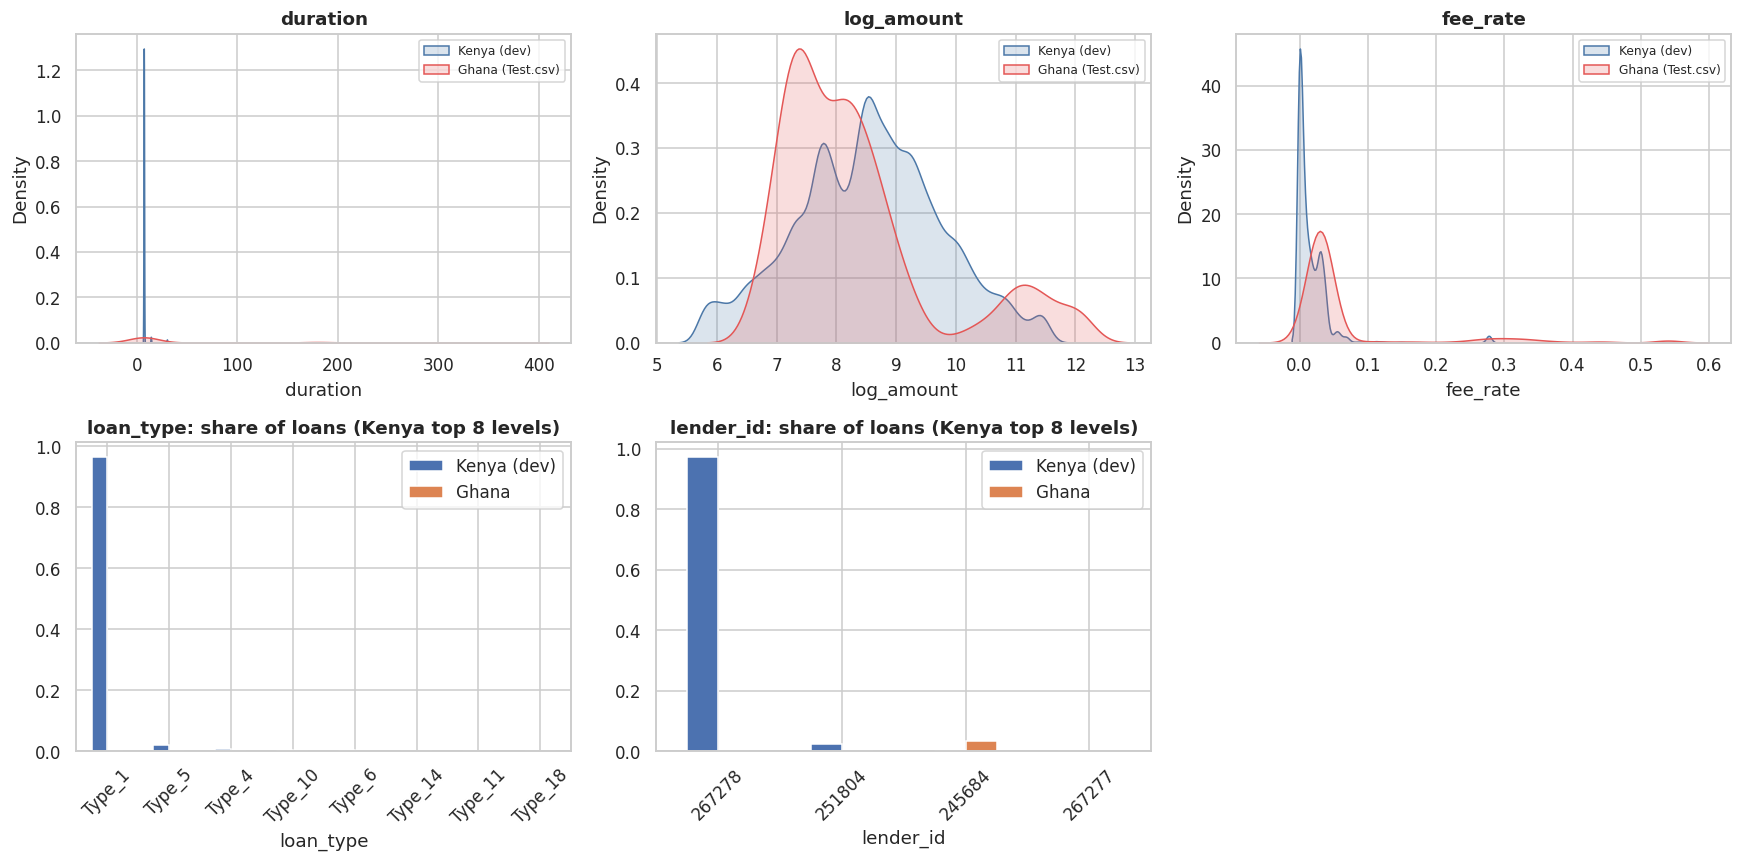

Domain classifier ROC-AUC (Kenya vs Ghana, cross-validated) = 1.000  (0.5 = indistinguishable, 1.0 = fully separable)
Features that most distinguish Ghana from Kenya (gain share):
 lender_id                0.683
loan_type                0.262
duration                 0.046
Lender_portion_Funded    0.007
lender_funded_share      0.001
fee_rate                 0.001
Importance weights: effective sample size 52,331 of 52,331 (100.0%)
Dev OOF PR-AUC unweighted 0.9694 | Ghana-reweighted 0.9694 ; default rate unweighted 0.0129 | reweighted 0.0129
Reweighted numbers are Kenyan evidence about Ghana-LIKE Kenyan loans, not Ghanaian outcomes. They only cover shift in observed features.


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax.ravel()[:3], ['duration', 'log_amount', 'fee_rate']):
    if c in STATIC:
        for d_, nm, col in [(dev, 'Kenya (dev)', '#4C78A8'), (G, 'Ghana (Test.csv)', '#E45756')]:
            sns.kdeplot(d_[c].dropna().clip(d_[c].quantile(.01), d_[c].quantile(.99)), ax=a, label=nm, color=col, fill=True, alpha=.2, common_norm=False)
        a.set_title(c); a.legend(fontsize=8)
for a, c in zip(ax.ravel()[3:5], ['loan_type', 'lender_id']):
    top = dev[c].value_counts().head(8).index; pd.DataFrame({'Kenya (dev)': dev[c].value_counts(normalize=True).reindex(top), 'Ghana': G[c].value_counts(normalize=True).reindex(top)}).fillna(0).plot.bar(ax=a)
    a.set_title(f'{c}: share of loans (Kenya top 8 levels)'); a.tick_params(axis='x', rotation=45)
ax.ravel()[5].axis('off'); plt.tight_layout(); savefig(fig, 'plots_tr', 'transfer_feature_distributions')

# ---- domain classifier: can we tell Kenya (dev) from Ghana? ----
dom = pd.concat([dev[STATIC].assign(_d=0), G[STATIC].assign(_d=1)], ignore_index=True); yd = dom.pop('_d')
dpipe = ImbPipeline([('prep', make_preprocessor(STATIC)), ('clf', lgb.LGBMClassifier(n_estimators=F(150, 40), learning_rate=0.05, num_leaves=15, min_child_samples=30, random_state=SEED, n_jobs=-1, verbose=-1))])
pd_oof = cross_val_predict(dpipe, dom, yd, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
print(f'Domain classifier ROC-AUC (Kenya vs Ghana, cross-validated) = {roc_auc_score(yd, pd_oof):.3f}  (0.5 = indistinguishable, 1.0 = fully separable)')
dpipe.fit(dom, yd); dprep, dclf = dpipe.named_steps['prep'], dpipe.named_steps['clf']
dimp = pd.Series(dclf.booster_.feature_importance('gain'), index=dprep.get_feature_names_out()).groupby(lambda n: source_col(n, STATIC)).sum().sort_values(ascending=False)
print('Features that most distinguish Ghana from Kenya (gain share):\n', (dimp / dimp.sum()).head(6).round(3).to_string())
# importance weights for Kenyan dev rows: w = p/(1-p) * nK/nG, clipped at the 99th percentile, mean-normalised
pk = np.clip(pd_oof[:len(dev)], 1e-4, 1 - 1e-4); w = pk / (1 - pk) * (len(dev) / len(G)); w = np.minimum(w, np.quantile(w, .99)); w = w / w.mean()
ess = w.sum() ** 2 / (w ** 2).sum(); print(f'Importance weights: effective sample size {ess:,.0f} of {len(w):,} ({100*ess/len(w):.1f}%)')
oofp = OP['final']['cal'].predict(RES[FINAL_EXP]['oof'])
print('Dev OOF PR-AUC unweighted %.4f | Ghana-reweighted %.4f ; default rate unweighted %.4f | reweighted %.4f'
      % (average_precision_score(y_dev, oofp), average_precision_score(y_dev, oofp, sample_weight=w), y_dev.mean(), np.average(y_dev, weights=w)))
print('Reweighted numbers are Kenyan evidence about Ghana-LIKE Kenyan loans, not Ghanaian outcomes. They only cover shift in observed features.')

,mean PD,median PD,decline rate at chosen threshold
Kenya dev OOF,0.0129,0.0001,0.0155
Kenya Test.csv,0.0157,0.0001,0.0215
Ghana Test.csv,0.0598,0.0002,0.1033


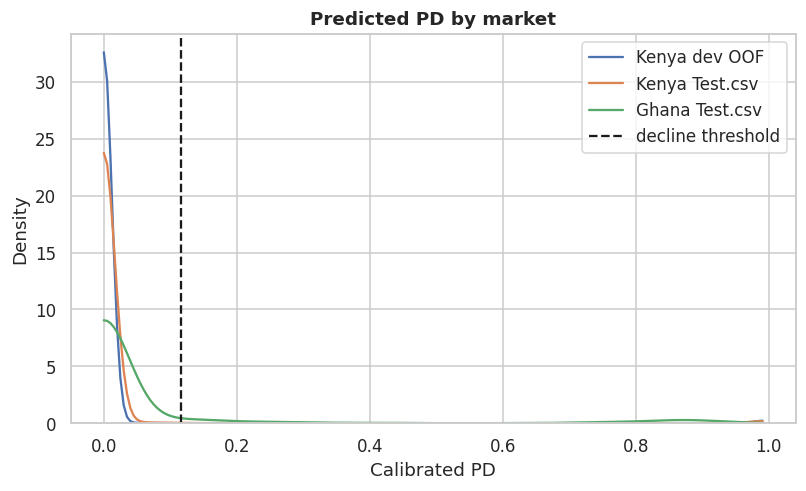

,odds multiplier (Ghana risk vs Kenya),expected default rate,decline rate at fixed threshold
0,0.5,0.0479,0.0772
1,1.0,0.0598,0.1033
2,1.5,0.0671,0.1191
3,2.0,0.0724,0.1240
4,3.0,0.0803,0.1313


Scenario table is a sensitivity analysis, not a forecast: it shows how much the decision rate moves if Ghana risk is a multiple of Kenyan risk.


In [ ]:
# ---- what does the final model do to Ghanaian applications? ----
sc_k = OP['final']['cal'].predict(get_score(pipe_f, K_te[FINAL_FEATS])); sc_g = OP['final']['cal'].predict(get_score(pipe_f, G[FINAL_FEATS])); thr_f = OP['final']['thr']
dist = pd.DataFrame({'Kenya dev OOF': [oofp.mean(), np.median(oofp), (oofp >= thr_f).mean()], 'Kenya Test.csv': [sc_k.mean(), np.median(sc_k), (sc_k >= thr_f).mean()],
                     'Ghana Test.csv': [sc_g.mean(), np.median(sc_g), (sc_g >= thr_f).mean()]}, index=['mean PD', 'median PD', 'decline rate at chosen threshold']).T
display(dist.round(4)); dist.to_csv(DIRS['results'] / 'transfer_score_distribution.csv')
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for p_, nm in [(oofp, 'Kenya dev OOF'), (sc_k, 'Kenya Test.csv'), (sc_g, 'Ghana Test.csv')]: sns.kdeplot(p_, ax=ax, label=nm, clip=(0, np.quantile(np.r_[oofp, sc_g], .995)), common_norm=False)
ax.axvline(thr_f, color='k', ls='--', label='decline threshold'); ax.set_xlabel('Calibrated PD'); ax.set_title('Predicted PD by market'); ax.legend(); savefig(fig, 'plots_tr', 'transfer_score_distributions')
# calibration-shift scenarios (ASSUMPTION-based): scale Ghana odds by a factor to see how fragile the decline rate / expected defaults are
scen = []
for mult in (0.5, 1.0, 1.5, 2.0, 3.0):
    pg = expit(logit(np.clip(sc_g, 1e-6, 1 - 1e-6)) + np.log(mult)); scen.append({'odds multiplier (Ghana risk vs Kenya)': mult, 'expected default rate': pg.mean(), 'decline rate at fixed threshold': (pg >= thr_f).mean()})
display(pd.DataFrame(scen).round(4))
print('Scenario table is a sensitivity analysis, not a forecast: it shows how much the decision rate moves if Ghana risk is a multiple of Kenyan risk.')

**Evidence the lender should require before trusting Ghana scores** (adapt with your results): (1) a labelled pilot, e.g. a small capped-limit cohort in Ghana, scored blind and followed to maturity to measure calibration and PR-AUC *in Ghana*; (2) agreement of covariate shift diagnostics (domain AUC, PSI) with a defined tolerance, and monitoring of the same metrics monthly; (3) lenders and loan types present in Ghana must exist in training (unseen levels fall back to an "infrequent" bucket, i.e. no product-specific knowledge); (4) Ghana customers have no Kenyan-style repayment history, so history features default to "no prior loans" (a structural difference, not noise); (5) local macro indicators and the Findex-based access picture (Section 12.3); (6) staged rollout with conservative limits, human review for borderline scores, and a kill-switch.

## 11. Fairness and responsible-AI audit (ProSit Part D)
**Scope and limits.** The data has no gender, age or region, so **no claim about those attributes is made here**. As instructed by the ProSit, groups are `country_id`, `loan_type`, `lender_id`, borrower tenure (`New_versus_Repeat`) and loan-size band. Metrics are computed on the untouched temporal test set with Fairlearn `MetricFrame` at the chosen operating threshold. Groups with fewer than 10 defaults are flagged: their recall/FNR are unreliable. Fairness criteria: **demographic parity** (selection-rate gap), **equal opportunity** (recall gap), **equalised odds** (max of recall and FPR gaps). Here "selection" = being declined.


=== loan_type ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,Type_1,8938.0,71.0,0.0056,0.6479,0.0005,0.3521,0.9200,0.7603,0.8256,0.0038,True,0.1332,0.6489
1,Type_10,267.0,8.0,0.3258,0.3750,0.3243,0.6250,0.0345,0.0632,0.0559,0.0987,False,0.0150,0.0194
2,Type_11,1.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0674,False,0.0000,0.0001
3,Type_15,2.0,2.0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0495,False,0.0038,0.0001
4,Type_16,12.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0009,False,0.0000,0.0009
5,Type_17,23.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0002,False,0.0000,0.0017
6,Type_19,2.0,0.0,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.9464,False,0.0000,0.0001
7,Type_2,41.0,22.0,0.8293,0.8182,0.8421,0.1818,0.5294,0.6429,0.7137,0.3750,True,0.0413,0.0030
8,Type_20,13.0,7.0,0.5385,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.3816,False,0.0131,0.0009
9,Type_22,1.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0007,False,0.0000,0.0001



=== lender_grp ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,251804,2241.0,189.0,0.1053,0.5979,0.0599,0.4021,0.4788,0.5318,0.5980,0.0530,True,0.3546,0.1627
1,267277,240.0,58.0,0.3417,0.8793,0.1703,0.1207,0.6220,0.7286,0.7908,0.2077,True,0.1088,0.0174
2,267278,11294.0,286.0,0.0243,0.5594,0.0104,0.4406,0.5839,0.5714,0.6572,0.0130,True,0.5366,0.8199



=== tenure ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,New Loan,175.0,34.0,0.2229,0.7353,0.0993,0.2647,0.6410,0.6849,0.7737,0.1240,True,0.0638,0.0127
1,Repeat Loan,13600.0,499.0,0.0407,0.5992,0.0194,0.4008,0.5407,0.5684,0.6387,0.0216,True,0.9362,0.9873



=== loan_size_band ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,Q1 smallest,2632.0,30.0,0.0095,0.6667,0.0019,0.3333,0.8000,0.7273,0.8409,0.0076,True,0.0563,0.1911
1,Q2,3789.0,155.0,0.0182,0.3871,0.0025,0.6129,0.8696,0.5357,0.8253,0.0102,True,0.2908,0.2751
2,Q3,3661.0,99.0,0.0194,0.5960,0.0034,0.4040,0.8310,0.6941,0.6920,0.0120,True,0.1857,0.2658
3,Q4 largest,3693.0,249.0,0.1156,0.7430,0.0703,0.2570,0.4333,0.5473,0.6758,0.0576,True,0.4672,0.2681


,attribute,demographic parity diff,equal opportunity diff (TPR),equalised odds diff,min/max selection ratio
0,loan_type,0.9944,0.6553,0.9995,0.0056
1,lender_grp,0.3174,0.3199,0.3199,0.0710
2,tenure,0.1822,0.1361,0.1361,0.1825
3,loan_size_band,0.1061,0.3559,0.3559,0.0821


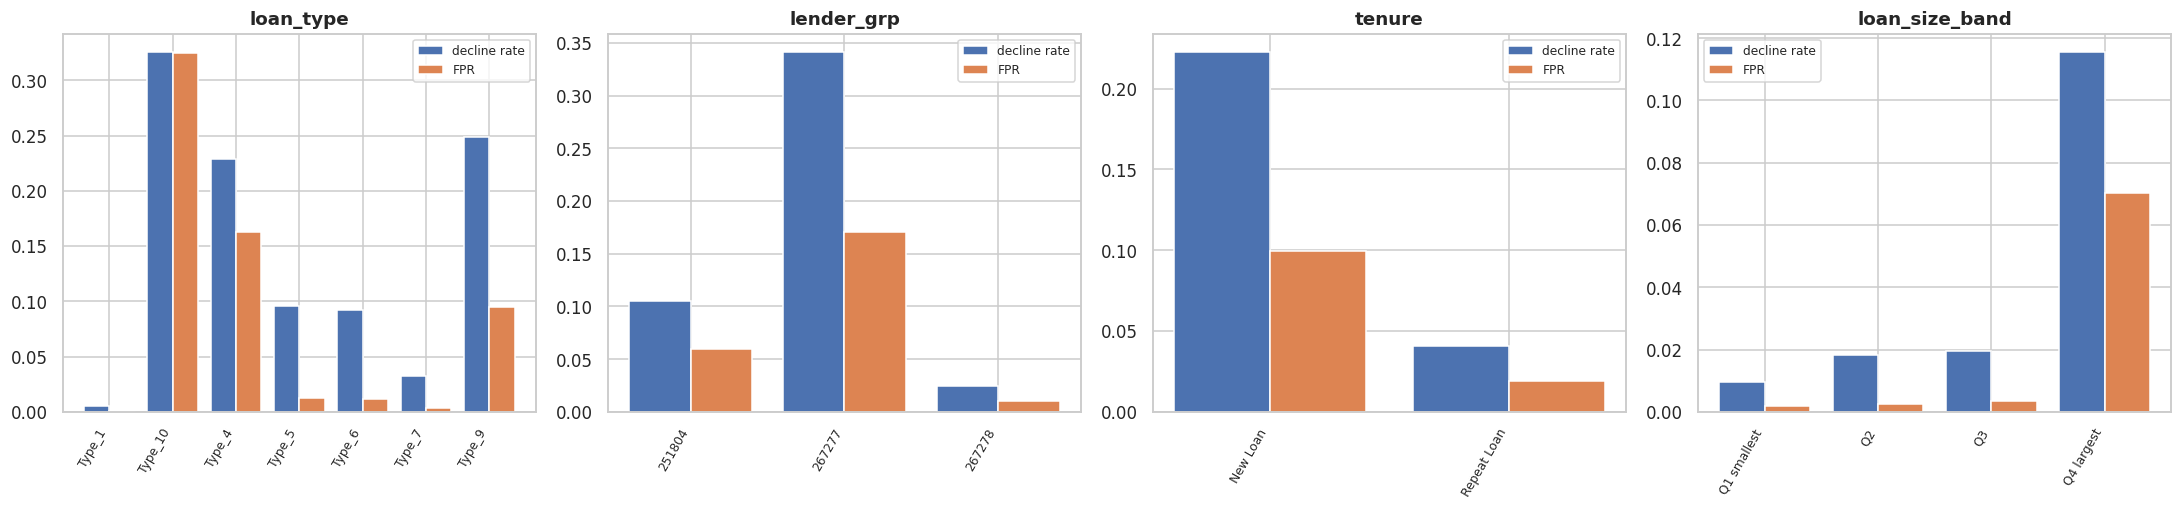

,market,n,mean PD,decline rate
0,Kenya,15069,0.0157,0.0215
1,Ghana,3525,0.0598,0.1033


Country: unlabeled, so only score and decline-rate gaps can be reported (no TPR/FPR). A higher Ghana decline rate is NOT evidence of unfairness or of higher risk until Ghana labels exist.


In [ ]:
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate, false_positive_rate, false_negative_rate,
                               demographic_parity_difference, equalized_odds_difference)
size_edges = dev['Total_Amount'].quantile([.25, .5, .75]).values
def size_band(a): return pd.cut(a, [-np.inf, *size_edges, np.inf], labels=['Q1 smallest', 'Q2', 'Q3', 'Q4 largest']).astype(str)
top_lenders = dev['lender_id'].value_counts().head(8).index
FT = test.copy(); FT['pd'] = OP['final']['p_test']; FT['decline'] = (FT['pd'] >= OP['final']['thr']).astype(int)
FT['loan_size_band'] = size_band(FT['Total_Amount']); FT['lender_grp'] = np.where(FT.lender_id.isin(top_lenders), FT.lender_id, 'other lenders')
GROUPS = {'loan_type': 'loan_type', 'lender_grp': 'lender_grp', 'tenure': 'New_versus_Repeat', 'loan_size_band': 'loan_size_band'}

def fairness_frame(FTd, col):
    y, yp = FTd['target'].values, FTd['decline'].values
    mf = MetricFrame(metrics={'n': lambda a, b: len(a), 'defaults': lambda a, b: int(a.sum()), 'selection_rate (decline)': selection_rate, 'recall (TPR)': true_positive_rate,
        'FPR': false_positive_rate, 'FNR': false_negative_rate, 'precision': lambda a, b: precision_score(a, b, zero_division=0), 'F1': lambda a, b: f1_score(a, b, zero_division=0)},
        y_true=y, y_pred=yp, sensitive_features=FTd[col].values)
    t = mf.by_group.copy()
    t['PR-AUC'] = [average_precision_score(y[FTd[col].values == g], FTd['pd'].values[FTd[col].values == g]) if y[FTd[col].values == g].sum() > 0 else np.nan for g in t.index]
    t['mean PD'] = [FTd['pd'].values[FTd[col].values == g].mean() for g in t.index]; t['reliable (>=10 defaults)'] = t['defaults'] >= 10
    t['share of all defaults'] = t['defaults'] / max(t['defaults'].sum(), 1); t['share of loans'] = t['n'] / t['n'].sum(); t['attribute'] = col; t = t.reset_index(); return t.rename(columns={t.columns[0]: 'group'})
fair_all = []
for nm, col in GROUPS.items():
    t = fairness_frame(FT, col); t['attribute'] = nm; fair_all.append(t); print(f'\n=== {nm} ==='); display(t.drop(columns='attribute').round(4))
fair = pd.concat(fair_all, ignore_index=True)
gaps = []
for nm, col in GROUPS.items():
    d = FT[FT[col].map(FT.groupby(col)['target'].sum() >= 10)]            # only groups with enough defaults for the TPR-based criteria
    if d[col].nunique() < 2: gaps.append({'attribute': nm, 'note': 'too few groups with >=10 defaults'}); continue
    gaps.append({'attribute': nm, 'demographic parity diff': demographic_parity_difference(d.target, d.decline, sensitive_features=d[col]),
                 'equal opportunity diff (TPR)': (lambda t_: t_['recall (TPR)'].max() - t_['recall (TPR)'].min())(fairness_frame(d, col)),
                 'equalised odds diff': equalized_odds_difference(d.target, d.decline, sensitive_features=d[col]),
                 'min/max selection ratio': fairness_frame(d, col)['selection_rate (decline)'].min() / max(fairness_frame(d, col)['selection_rate (decline)'].max(), 1e-9)})
gap_tbl = pd.DataFrame(gaps); display(gap_tbl.round(4))
fair.to_csv(DIRS['results'] / 'fairness_results.csv', index=False); gap_tbl.to_csv(DIRS['results'] / 'fairness_gaps.csv', index=False)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for a, nm in zip(ax, GROUPS):
    d = fair[(fair.attribute == nm) & (fair.n >= 100)]; x = np.arange(len(d)); a.bar(x - .2, d['selection_rate (decline)'], .4, label='decline rate'); a.bar(x + .2, d['FPR'], .4, label='FPR')
    a.set_xticks(x); a.set_xticklabels(d.group, rotation=60, ha='right', fontsize=8); a.set_title(nm); a.legend(fontsize=8)
plt.tight_layout(); savefig(fig, 'plots_fair', 'fairness_selection_fpr')
# country (Test.csv has no labels): score and decline-rate comparison only
cty = pd.DataFrame({'market': ['Kenya', 'Ghana'], 'n': [len(K_te), len(G)], 'mean PD': [sc_k.mean(), sc_g.mean()], 'decline rate': [(sc_k >= thr_f).mean(), (sc_g >= thr_f).mean()]})
display(cty.round(4)); print('Country: unlabeled, so only score and decline-rate gaps can be reported (no TPR/FPR). A higher Ghana decline rate is NOT evidence of unfairness or of higher risk until Ghana labels exist.')
cty.to_csv(DIRS['results'] / 'fairness_country.csv', index=False)

In [ ]:
# Does the tool concentrate risk? who absorbs defaults and losses (test)
for nm in ['loan_type', 'lender_grp']:
    t = fair[fair.attribute == nm][['group', 'n', 'defaults', 'share of loans', 'share of all defaults']].copy(); t['default rate %'] = 100 * t.defaults / t.n; t['concentration (default share / loan share)'] = t['share of all defaults'] / t['share of loans']
    print(f'\nRisk concentration by {nm}'); display(t.sort_values('concentration (default share / loan share)', ascending=False).round(3))

# ---- Proxy analysis: can the remaining features reconstruct the group even if the group column is removed? ----
PROXY_EXCL = {'tenure (New)': (dev.New_versus_Repeat == 'New', ['New_versus_Repeat']),
              'smallest loan quartile': (size_band(dev.Total_Amount) == 'Q1 smallest', ['log_amount', 'amount_vs_prior_mean', 'prior_mean_amount', 'last_amount', 'lender_funded_share', 'lender_repay_share', 'Lender_portion_Funded', 'fee_rate', 'daily_fee_rate']),
              'most common loan type': (dev.loan_type == dev.loan_type.value_counts().index[0], ['loan_type'])}
prox = []
for nm, (ytar, excl) in PROXY_EXCL.items():
    fs = [c for c in FINAL_FEATS if c not in excl]; pp = ImbPipeline([('prep', make_preprocessor(fs)), ('clf', lgb.LGBMClassifier(n_estimators=F(150, 40), learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=-1, verbose=-1))])
    s_ = cross_val_predict(pp, dev[fs], ytar.astype(int), cv=StratifiedKFold(3, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
    prox.append({'group': nm, 'AUC predicting group from remaining features': roc_auc_score(ytar, s_), 'AUC predicting group from model PD alone': roc_auc_score(ytar, oofp)})
prox = pd.DataFrame(prox); display(prox.round(3)); prox.to_csv(DIRS['results'] / 'proxy_analysis.csv', index=False)
print('AUC well above 0.5 means group information survives removal of the sensitive column: dropping a column is not the same as being blind to the group.')


Risk concentration by loan_type


,group,n,defaults,share of loans,share of all defaults,default rate %,concentration (default share / loan share)
3,Type_15,2.0,2.0,0.000,0.004,100.000,25.844
10,Type_23,18.0,13.0,0.001,0.024,72.222,18.665
8,Type_20,13.0,7.0,0.001,0.013,53.846,13.916
7,Type_2,41.0,22.0,0.003,0.041,53.659,13.868
15,Type_9,205.0,36.0,0.015,0.068,17.561,4.539
11,Type_4,848.0,88.0,0.062,0.165,10.377,2.682
14,Type_7,2790.0,235.0,0.203,0.441,8.423,2.177
12,Type_5,429.0,36.0,0.031,0.068,8.392,2.169
13,Type_6,185.0,15.0,0.013,0.028,8.108,2.095
1,Type_10,267.0,8.0,0.019,0.015,2.996,0.774



Risk concentration by lender_grp


,group,n,defaults,share of loans,share of all defaults,default rate %,concentration (default share / loan share)
17,267277,240.0,58.0,0.017,0.109,24.167,6.246
16,251804,2241.0,189.0,0.163,0.355,8.434,2.180
18,267278,11294.0,286.0,0.820,0.537,2.532,0.654


,group,AUC predicting group from remaining features,AUC predicting group from model PD alone
0,tenure (New),NaN,NaN
1,smallest loan quartile,0.621,0.357
2,most common loan type,1.000,0.045


AUC well above 0.5 means group information survives removal of the sensitive column: dropping a column is not the same as being blind to the group.


In [ ]:
# ---- Does imbalance mitigation change who gets flagged? (LightGBM, dev OOF at a fixed alert budget) ----
grp = dev['New_versus_Repeat'].values; rows = []
for s in STRATS:
    k = f'S2_lgbm_{s}'
    if k not in RES: continue
    o = RES[k]['oof']; thr_ = topq_threshold(o, CFG['TOP_Q'])
    for g in np.unique(grp):
        m = grp == g; yh = (o[m] >= thr_).astype(int); yy = y_dev.values[m]
        rows.append({'strategy': s, 'tenure': g, 'flag rate': yh.mean(), 'recall': yh[yy == 1].mean() if yy.sum() else np.nan, 'FPR': yh[yy == 0].mean()})
imbf = pd.DataFrame(rows); display(imbf.pivot(index='strategy', columns='tenure', values=['flag rate', 'recall', 'FPR']).round(3)); imbf.to_csv(DIRS['results'] / 'fairness_imbalance_strategy.csv', index=False)

flag rate               recall                  FPR            
tenure    New Loan Repeat Loan New Loan Repeat Loan New Loan Repeat Loan
strategy                                                                
adasyn       0.675       0.096      1.0       0.995    0.586       0.085
bsmote       0.680       0.096      1.0       0.995    0.592       0.085
cw           0.539       0.097      1.0       0.997    0.411       0.086
none         0.557       0.097      1.0       0.997    0.434       0.086
ros          0.536       0.097      1.0       0.997    0.408       0.086
rus          0.771       0.095      1.0       0.997    0.707       0.085
smote        0.582       0.096      1.0       0.995    0.467       0.086

In [ ]:
# ---- Mitigation: group-specific thresholds to equalise recall across tenure groups (equal opportunity) ----
# Fitted on DEV OOF only, evaluated once on test. NOTE: group-specific thresholds are explicit disparate treatment and may be unlawful or
# unacceptable to the regulator; this is a measured trade-off, not a recommendation. A legal review is required before any use.
dev_t = dev['New_versus_Repeat'].values; test_t = FT['New_versus_Repeat'].values; thr0 = OP['final']['thr']
base_rec = ((oofp >= thr0) & (y_dev.values == 1)).sum() / y_dev.sum(); thr_g = {}
for g in np.unique(dev_t):
    m = dev_t == g; p_g, y_g = oofp[m], y_dev.values[m]
    cgrid = np.unique(np.quantile(p_g, np.linspace(0.5, 0.9995, 300)))
    ok = [t for t in cgrid if ((p_g >= t) & (y_g == 1)).sum() / max(y_g.sum(), 1) >= base_rec]
    thr_g[g] = max(ok) if ok else thr0
FT['decline_mit'] = [int(p >= thr_g.get(g, thr0)) for p, g in zip(FT['pd'], test_t)]
def summarise(col):
    t = FT.groupby('New_versus_Repeat').apply(lambda d: pd.Series({'decline rate': d[col].mean(), 'recall': d.loc[d.target == 1, col].mean(), 'FPR': d.loc[d.target == 0, col].mean()}))
    return t
before, after = summarise('decline'), summarise('decline_mit')
print('Group thresholds (fitted on dev OOF):', {k: round(float(v), 4) for k, v in thr_g.items()})
display(pd.concat({'single threshold': before, 'tenure-specific thresholds': after}, axis=1).round(4))
c0 = expected_cost(y_te, FT['decline'].values, fn_te, fp_te); c1 = expected_cost(y_te, FT['decline_mit'].values, fn_te, fp_te)
print(f'Expected cost on test: single {c0*fx:,.0f} GHS -> mitigated {c1*fx:,.0f} GHS ({100*(c1-c0)/max(c0,1e-9):+.1f}%); overall decline rate {FT.decline.mean():.3%} -> {FT.decline_mit.mean():.3%}')
print('Interpretation: report the fairness-cost trade-off. If the recall gap is within sampling noise (few defaults per group), do not over-interpret the mitigation effect.')
pd.concat({'single': before, 'mitigated': after}, axis=1).to_csv(DIRS['results'] / 'fairness_mitigation.csv')

Group thresholds (fitted on dev OOF): {'New Loan': 0.0485, 'Repeat Loan': 0.1292}


single threshold                 tenure-specific thresholds  \
                      decline rate  recall     FPR               decline rate   
New_versus_Repeat                                                               
New Loan                    0.2229  0.7353  0.0993                     0.2686   
Repeat Loan                 0.0407  0.5992  0.0194                     0.0388   

                                   
                   recall     FPR  
New_versus_Repeat                  
New Loan           0.8529  0.1277  
Repeat Loan        0.5912  0.0178

Expected cost on test: single 41,632,275 GHS -> mitigated 41,473,076 GHS (-0.4%); overall decline rate 4.298% -> 4.174%
Interpretation: report the fairness-cost trade-off. If the recall gap is within sampling noise (few defaults per group), do not over-interpret the mitigation effect.


## 12. Model card, compliance mapping, Findex and borrower explainer
### 12.1 Model Card (Mitchell et al., 2019)
Generated from this run's actual numbers and saved to `reports/model_card.md`. Edit the narrative fields (intended use, ethical considerations) to reflect your team's decisions.

In [ ]:
f4 = lambda v: f'{v:.4f}'
tf_ = TEST['final']; row_ = RES[FINAL_EXP]['row']
fl = fair[fair.attribute == 'tenure'][['group', 'n', 'defaults', 'selection_rate (decline)', 'recall (TPR)', 'FPR']].round(3).to_string(index=False)
model_card = f"""# Model Card: NkwaPay default-risk scorer (Task 2)

## Model details
- Type: {FINAL_MODEL} ({OP['final']['exp_id']}), imbalance strategy `{row_['strategy']}`, calibrator `{OP['final']['method']}`. Trained {pd.Timestamp.now().date()}; seed {SEED}.
- Inputs: {len(FINAL_FEATS)} features from loan terms, calendar, time-safe borrower history{', macro indicators' if macro_cols else ''}. No demographic attributes are available or used.
- Output: calibrated probability of default (PD); decision rule: decline if PD >= {OP['final']['thr']:.4f}.
- Library versions: see reports/environment.json.

## Intended use
- Support (not replace) credit officers when approving, limiting and pricing small mobile-money loans. Human review for borderline cases and appeals.
- **Out of scope:** use in Ghana without local validation; employment, insurance or any non-credit decision; use as sole basis of a declined application.

## Factors
- Evaluated across loan type, lender, tenure (new vs repeat), loan-size band, and country (unlabeled in Ghana).

## Metrics (temporal test set, n={len(y_te):,}, defaults={int(y_te.sum())}, prevalence {y_te.mean():.4f})
- PR-AUC {f4(tf_['pr_auc'])} (no-skill {y_te.mean():.4f}); ROC-AUC {f4(tf_['roc_auc'])}; Brier {f4(tf_['brier'])}
- At threshold: precision {f4(tf_['precision'])}, recall {f4(tf_['recall'])}, F1 {f4(tf_['f1'])}, FPR {f4(tf_['fpr'])}, decline rate {tf_['flag_rate']:.3%}
- Bootstrap 95% CI (customer clusters): PR-AUC {tuple(np.round(ci(bt['ap_final']), 4))}, F1 {tuple(np.round(ci(bt['f1_final']), 4))}
- Dev grouped-CV PR-AUC {f4(row_['pr_auc'])} (fold SD {f4(row_['ap_fold_sd'])})

## Evaluation and training data
- Source: Kenyan loan records (African Credit Scoring Challenge, Zindi), {len(lab):,} loans, default rate {lab.target.mean():.3%}. Dev = loans before {test_start.date()}; test = later loans.
- Known limits: single market; defaults rare; label timing/grace period not documented.

## Quantitative analyses (tenure)
```
{fl}
```
Full disaggregated results: results/fairness_results.csv; gaps: results/fairness_gaps.csv; proxy analysis: results/proxy_analysis.csv.

## Ethical considerations
- Errors fall on people: false negatives push lenders and borrowers toward unaffordable debt; false positives deny credit to people who would repay.
- Tenure and loan size are proxies for thin files and low income; see fairness audit and mitigation trade-off.
- No gender or region fields exist, so equity on those axes is **unassessed**.

## Caveats and recommendations
- Do not deploy in Ghana before a labelled pilot (Section 10). Monitor drift (PSI) and calibration monthly.
- Cost assumptions (recovery {CFG['RECOVERY_RATE']:.0%}, collection {CFG['COLLECTION_COST_RATE']:.0%}) are placeholders unless replaced in the config.
"""
(DIRS['reports'] / 'model_card.md').write_text(model_card); print(model_card[:1800], '...')

# Model Card: NkwaPay default-risk scorer (Task 2)

## Model details
- Type: lgbm (S3_lgbm_tuned), imbalance strategy `ros`, calibrator `platt`. Trained 2026-11-01; seed 42.
- Inputs: 26 features from loan terms, calendar, time-safe borrower history. No demographic attributes are available or used.
- Output: calibrated probability of default (PD); decision rule: decline if PD >= 0.1161.
- Library versions: see reports/environment.json.

## Intended use
- Support (not replace) credit officers when approving, limiting and pricing small mobile-money loans. Human review for borderline cases and appeals.
- **Out of scope:** use in Ghana without local validation; employment, insurance or any non-credit decision; use as sole basis of a declined application.

## Factors
- Evaluated across loan type, lender, tenure (new vs repeat), loan-size band, and country (unlabeled in Ghana).

## Metrics (temporal test set, n=13,775, defaults=533, prevalence 0.0387)
- PR-AUC 0.6489 (no-skill 0.0387); ROC-A

### 12.2 Regulatory mapping (draft for legal review)
This table maps design choices to the *themes* of the Bank of Ghana Digital Credit Services Directive, the Data Protection Act 2012 (Act 843) and the Credit Reporting Act 2007 (Act 726). It is **not legal advice**: before submission, check each row against the current official text and cite clause numbers.

| Requirement theme | Design response in this project | Status |
|---|---|---|
| Transparency and disclosure of terms and decisions | Reason codes in plain language (12.4); full price (fee, daily rate) shown in features | Partial: no disclosure UI built |
| Fair treatment, no discrimination, no predatory practice | Disaggregated metrics, proxy analysis, mitigation trade-off (Section 11) | Partial: no gender/region data; Ghana unvalidated |
| Responsible lending, avoid over-indebtedness | Cost-based threshold, approval constraint, limit regression | **Cannot satisfy now:** no income, expenses or total-debt data to test affordability |
| Lawful basis, consent, purpose limitation, minimisation | Only loan-level fields used; no sensitive attributes | **Cannot verify:** consent records and Ghana data-sharing basis not in the dataset |
| Cross-border use of data and models (Kenyan data, Ghanaian applicants) | Documented in model card | **Cannot satisfy now:** transfer and localisation obligations need legal confirmation |
| Rights around automated decisions (explanation, human review, contest) | Reasons returned with each decision; borderline flagged for manual review | Partial: appeals process must be operationalised |
| Credit reporting (accurate data, bureau reporting, dispute) | Out of scope of the model | **Not implemented** |
| Model governance, audit trail, regulator access | Versioned bundle, config, seeds, model card, saved experiments | Met for this notebook; production monitoring pending |
| Local validation | Transfer diagnostics only | **Cannot satisfy now:** no Ghana labels |

### 12.3 Debt and access with Global Findex Ghana (to complete with your data)
Set `FINDEX_MAP` below once you have downloaded the microdata (World Bank registration). Describe **who has no account, no mobile money and no formal borrowing**, by income group, gender, age and rural/urban, then argue whether a model trained on *existing borrowers in Kenya* closes or widens that gap: a scorer that depends on repayment history (new borrowers have none) tends to favour people already inside the system, unless thin-file applicants are handled deliberately (small initial limits, alternative data with consent).

In [ ]:
FINDEX_MAP = {}   # e.g. {'weight': 'wgt', 'no_account': 'account', 'mobile_money': 'mobileaccount', 'borrowed_formal': 'fin20', 'groups': ['female', 'inc_q', 'age', 'urbanicity']}
fp = DATA / CFG['FINDEX_FILE']
if fp.exists():
    fdf = pd.read_csv(fp); print('Findex file loaded:', fdf.shape); display(fdf.head(3)); print('Columns:', list(fdf.columns)[:40])
    if FINDEX_MAP:
        w = fdf[FINDEX_MAP['weight']] if FINDEX_MAP.get('weight') else pd.Series(1.0, index=fdf.index)
        for g in FINDEX_MAP.get('groups', []):
            out = {k: fdf.assign(_w=w).groupby(g).apply(lambda d, c=FINDEX_MAP[k]: np.average(d[c].fillna(0), weights=d['_w'])) for k in ('no_account', 'mobile_money', 'borrowed_formal') if k in FINDEX_MAP}
            print(f'\nShare by {g}'); display(pd.DataFrame(out).round(3))
else:
    print('Findex file not found (optional). Set FINDEX_FILE and FINDEX_MAP to run this block.')

KeyError: 'FINDEX_FILE'

### 12.4 Borrower-facing explanation of a declined application

In [ ]:
ix = idx_hi; rs = top_reasons(cs_all.iloc[ix])
explainer = f"""# Why your loan application was not approved

Thank you for applying. We are sorry that we could not approve this loan today.

**What we looked at.** We used the details of your application (loan type, amount, repayment period, and your loan record with us, if any). We did not use your gender, religion, ethnicity or where you live.

**The main reasons**
""" + '\n'.join(f'{i+1}. {t}' for i, (_, _, t) in enumerate(rs)) + f"""

**What this means.** This is a decision based on a computer model that estimates how likely a loan like this is to be repaid on time. It is not a judgement of you as a person. The model can be wrong.

**What you can do**
- Ask for a person to review the decision. You have the right to ask, and to ask us to correct wrong information about you.
- Apply again for a smaller amount or a longer period; repaying earlier loans on time improves future decisions.
- Borrow only what you can repay comfortably. Missed repayments can lead to extra costs.

Contact: [NkwaPay support number and email to be inserted]
"""
(DIRS['reports'] / 'borrower_explainer.md').write_text(explainer); print(explainer)

## 13. Scoring service (ProSit Part E)
`scoring_service.py` loads one bundle (pipeline, calibrator, threshold, history store, limit model, reason texts) and exposes `Scorer.score(application) -> {pd, decision, limit, reasons, latency_ms}`. The same `credit_lib` feature code is used as in training, so there is no train/serve skew. The decision policy (approve / approve with reduced limit and review / decline) is a **proposal for the credit committee**.

In [ ]:
%%writefile scoring_service.py
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd, joblib
from scipy.special import expit

REQUIRED_FIELDS = ['customer_id', 'country_id', 'loan_type', 'lender_id', 'duration', 'disbursement_date', 'Total_Amount',
                   'Total_Amount_to_Repay', 'Amount_Funded_By_Lender', 'Lender_portion_Funded', 'Lender_portion_to_be_repaid', 'New_versus_Repeat']

class Scorer:
    def __init__(self, bundle_path):
        bundle_path = Path(bundle_path); sys.path.insert(0, str(bundle_path.parent.parent.parent / 'code'))
        import credit_lib as cl; self.cl = cl
        self.b = joblib.load(bundle_path); self.feats = self.b['features']
        h = self.b['history']; self.hist = {k: g for k, g in h.groupby('customer_id')}; self.empty = h.iloc[0:0]
        self.pipe = self.b['pipeline']; self.clf = self.pipe.named_steps['clf']; self.prep = self.pipe.named_steps['prep']
        self.explainer = None
        if not hasattr(self.clf, 'coef_'):
            import shap; self.explainer = shap.TreeExplainer(self.clf)
    def _features(self, app):
        miss = [f for f in REQUIRED_FIELDS if f not in app or app[f] is None]
        if miss: raise ValueError(f'missing required fields: {miss}')
        df = pd.DataFrame([app]); df['disbursement_date'] = pd.to_datetime(df['disbursement_date'])
        df['due_date'] = df['disbursement_date'] + pd.to_timedelta(df['duration'], unit='D')
        for c in self.cl.CAT_COLS: df[c] = df[c].astype(str)
        f = self.cl.add_calendar(df); f = self.cl.add_terms(f)
        f = self.cl.add_history(f, self.hist.get(app['customer_id'], self.empty), self.b['grace_days'])
        return self.cl.add_macro(f, self.b['econ'], 1)
    def _contrib(self, f):
        Xt = self.prep.transform(f[self.feats]); names = list(self.prep.get_feature_names_out())
        if hasattr(self.clf, 'coef_'): c = Xt[0] * self.clf.coef_.ravel()
        else:
            sv = self.explainer.shap_values(Xt); sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv); c = np.asarray(sv)[0]
        return pd.Series(c, index=names).groupby(lambda n: self.cl.source_col(n, self.feats)).sum()
    def score(self, app):
        t0 = time.perf_counter(); f = self._features(app)
        s = self.pipe.predict_proba(f[self.feats])[:, 1] if hasattr(self.pipe, 'predict_proba') else expit(self.pipe.decision_function(f[self.feats]))
        pdv = float(self.b['calibrator'].predict(s)[0]); thr = self.b['threshold']
        lim_log = float(self.b['limit_pipeline'].predict(f)[0]); sd = self.b['limit_resid_sd']; req = float(app['Total_Amount'])
        if pdv >= thr: decision, limit = 'decline', 0.0
        elif pdv >= self.b['review_fraction'] * thr: decision, limit = 'approve_reduced_limit_manual_review', min(req, float(np.expm1(lim_log)))
        else: decision, limit = 'approve', min(req, float(np.expm1(lim_log + sd)))
        c = self.b['reason_fn'](self._contrib(f)); reasons = [{'feature': k, 'contribution': v, 'text': t} for k, v, t in c]
        return dict(probability_of_default=pdv, decision=decision, approved_limit=limit, threshold=thr, top_reasons=reasons,
                    model_version=self.b['version'], latency_ms=round((time.perf_counter() - t0) * 1000, 1))

Writing scoring_service.py


In [ ]:
# ---- assemble and save the deployable bundle ----
limit_pipe = joblib.load(DIRS['ckpt_reg'] / f'{BEST_REG}.joblib'); resid_sd = float(np.std(ylog_dev - REG_OOF[BEST_REG]))
BUNDLE_PATH = DIRS['ckpt_best'] / 'final_bundle.joblib'
bundle = dict(pipeline=OP['final']['pipe'], calibrator=OP['final']['cal'], threshold=float(OP['final']['thr']), review_fraction=0.5,
              features=FINAL_FEATS, model=FINAL_MODEL, version=f'{FINAL_EXP}@{pd.Timestamp.now():%Y%m%d}', grace_days=CFG['GRACE_DAYS'],
              history=lab[['customer_id', 'disbursement_date', 'due_date', 'Total_Amount', 'target']].copy(), econ=econ_prep,
              limit_pipeline=limit_pipe, limit_resid_sd=resid_sd, reason_fn=ReasonBuilder(REASONS),
              size_edges=list(size_edges), config=CFG, seed=SEED, env=ENV, test_metrics={k: {m: v for m, v in d.items() if isinstance(v, (int, float, str))} for k, d in TEST.items()})
joblib.dump(bundle, BUNDLE_PATH)
for f_ in ('credit_lib.py', 'scoring_service.py'): shutil.copy(f_, DIRS['code'] / f_)
print('Saved bundle ->', BUNDLE_PATH, f'({BUNDLE_PATH.stat().st_size/1e6:.1f} MB)')

importlib.invalidate_caches(); import scoring_service; importlib.reload(scoring_service)
scorer = scoring_service.Scorer(BUNDLE_PATH)
ex = test.iloc[idx_hi]; app = {k: (ex[k].isoformat() if k == 'disbursement_date' else (ex[k].item() if hasattr(ex[k], 'item') else ex[k])) for k in scoring_service.REQUIRED_FIELDS}
print('Example request (what the application must send):'); print(json.dumps(app, indent=2, default=str))
out = scorer.score(app); print('\nResponse:'); print(json.dumps(out, indent=2, default=str))
assert abs(out['probability_of_default'] - OP['final']['p_test'][idx_hi]) < 1e-6, 'service and notebook scores disagree (train/serve skew!)'
print('\nParity check passed: service PD equals notebook PD for the same applicant.')
lat = []
for i in range(F(200, 30)):
    r_ = test.iloc[i % len(test)]; a_ = {k: (r_[k].isoformat() if k == 'disbursement_date' else (r_[k].item() if hasattr(r_[k], 'item') else r_[k])) for k in scoring_service.REQUIRED_FIELDS}
    lat.append(scorer.score(a_)['latency_ms'])
print(f'Latency over {len(lat)} single-application calls (1 CPU, in-process): mean {np.mean(lat):.1f} ms, p95 {np.percentile(lat, 95):.1f} ms, max {np.max(lat):.1f} ms')
try:
    scorer.score({k: v for k, v in app.items() if k != 'duration'})
except ValueError as e: print('Validation works:', e)

Saved bundle -> /content/drive/MyDrive/MLE Prosit 2/research_outputs/checkpoints/best_models/final_bundle.joblib (4.7 MB)
Example request (what the application must send):
{
  "customer_id": 256582,
  "country_id": "Kenya",
  "loan_type": "Type_5",
  "lender_id": "251804",
  "duration": 14,
  "disbursement_date": "2022-12-17T00:00:00",
  "Total_Amount": 24200.0,
  "Total_Amount_to_Repay": 45494.0,
  "Amount_Funded_By_Lender": 3226.0,
  "Lender_portion_Funded": 0.133305785123966,
  "Lender_portion_to_be_repaid": 6065.0,
  "New_versus_Repeat": "Repeat Loan"
}

Response:
{
  "probability_of_default": 0.9951116488713003,
  "decision": "decline",
  "approved_limit": 0.0,
  "threshold": 0.11606026541549526,
  "top_reasons": [
    {
      "feature": "fee_rate",
      "contribution": 11.952648349540606,
      "text": "The total cost of this loan is high relative to the amount borrowed."
    },
    {
      "feature": "daily_fee_rate",
      "contribution": 1.6509420631021468,
      "text": "The

## 14. Consolidated results, final report and reproducibility

In [ ]:
# ---- consolidated tables ----
reg_all = load_registry().sort_values('pr_auc', ascending=False); reg_all.to_csv(DIRS['results'] / 'experiment_metrics.csv', index=False)
cv_rows = [{'exp_id': k, **{f'fold{i+1}_pr_auc': v for i, v in enumerate(r['fold_ap'])}} for k, r in RES.items()]
pd.DataFrame(cv_rows).to_csv(DIRS['results'] / 'cross_validation_results.csv', index=False)
print(f'{len(reg_all)} experiments completed; failed: {len(FAILED)}')
display(reg_all[['exp_id', 'stage', 'pr_auc', 'ap_fold_mean', 'ap_fold_sd', 'roc_auc', 'brier', 'f1opt_f1', 'f1opt_mcc', 'top_recall', 'top_fpr', 'apparent_pr_auc']].round(4))
# best models per family copied to best_models for convenience
for m, e in cand.items(): shutil.copy(CKPT['opt'] / f'{e}.model.joblib', DIRS['ckpt_best'] / f'best_{m}.joblib')
# ---- JSON summary + text report ----
summary_json = dict(created=str(pd.Timestamp.now()), seed=SEED, config=CFG, environment=ENV, n_train_rows=int(len(lab)), n_dev=int(len(dev)), n_test=int(len(test)),
    default_rate=float(lab.target.mean()), test_start=str(test_start.date()), final_model=FINAL_MODEL, final_experiment=FINAL_EXP, imbalance_strategy=BEST_STRAT.get(FINAL_MODEL),
    calibrator=OP['final']['method'], threshold=float(OP['final']['thr']), analytic_p_star=float(p_star), best_hyperparameters=BEST_PARAMS,
    test_metrics={k: {m: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for m, v in d.items()} for k, d in TEST.items()},
    bootstrap_ci=dict(pr_auc=[float(x) for x in ci(bt['ap_final'])], f1=[float(x) for x in ci(bt['f1_final'])]), regression_best=BEST_REG,
    regression_test=reg_test.loc[BEST_REG].to_dict(), failed_experiments=FAILED)
(DIRS['reports'] / 'experiment_summary.json').write_text(json.dumps(summary_json, indent=2, default=str))
report = f"""FINAL MODEL REPORT ({pd.Timestamp.now():%Y-%m-%d %H:%M})
=====================================================
Selected model: {FINAL_MODEL} ({FINAL_EXP}); selection rule: simplest model within 1 SE of best mean fold PR-AUC (committee preference for explainability).
Imbalance strategy: {row_['strategy']} | calibrator: {OP['final']['method']} | decline threshold on calibrated PD: {OP['final']['thr']:.4f} (analytic p* {p_star:.4f})
Data: {len(lab):,} loans, default rate {lab.target.mean():.3%}; dev {len(dev):,} / test {len(test):,} (test = loans from {test_start.date()}).

DEV (grouped CV, {CFG['N_FOLDS']} folds): PR-AUC {row_['pr_auc']:.4f}, fold mean {row_['ap_fold_mean']:.4f} +- {row_['ap_fold_sd']:.4f}
TEST (single evaluation): PR-AUC {TEST['final']['pr_auc']:.4f} (95% CI {tuple(np.round(ci(bt['ap_final']), 4))}), ROC-AUC {TEST['final']['roc_auc']:.4f},
  precision {TEST['final']['precision']:.4f}, recall {TEST['final']['recall']:.4f}, F1 {TEST['final']['f1']:.4f} (95% CI {tuple(np.round(ci(bt['f1_final']), 4))}), MCC {TEST['final']['mcc']:.4f}
  expected cost {TEST['final']['expected_cost']*fx:,.0f} GHS vs approve-all {TEST['majority_approve_all']['expected_cost']*fx:,.0f} GHS
Paired difference vs tuned logistic regression (test, bootstrap): dPR-AUC {dpa.mean():+.4f} CI {np.round(ci(dpa), 4)}.
Task 1 (regression, {BEST_REG}): RMSE(log) {reg_test.loc[BEST_REG, 'rmse_log']:.4f} vs mean baseline {reg_test.loc['mean', 'rmse_log']:.4f}; MAE(orig) {reg_test.loc[BEST_REG, 'mae_orig']:,.1f}.

LIMITATIONS
- Single-country labels; Ghana performance is unmeasured (Section 10 shows shift only).
- Cost-matrix recovery and collection rates are assumptions unless replaced in CFG.
- Few test defaults (n={int(y_te.sum())}): wide intervals; subgroup metrics unreliable below 10 defaults.
- No gender/region/age data: fairness on those axes is unassessed. Group-specific thresholds (mitigation) may be legally problematic.
- History features cannot exist for new Ghana customers; SMOTE interpolates one-hot columns; tuning-vs-OOF selection optimism reduced but not eliminated.
- Lender_portion_to_be_repaid / funding columns need data-owner confirmation of decision-time availability (see ablation).
FUTURE WORK: labelled Ghana pilot, uncertainty-aware (conformal) scores, affordability data, monotonic constraints, temporal drift monitoring.
"""
(DIRS['reports'] / 'final_model_report.txt').write_text(report); print(report)

44 experiments completed; failed: 0


,exp_id,stage,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,f1opt_f1,f1opt_mcc,top_recall,top_fpr,apparent_pr_auc
20,S2_lgbm_ros,S2_imbalance,0.9701,0.9708,0.0115,0.9977,0.0021,0.9111,0.9112,0.9970,0.0883,0.9995
29,S3_lgbm_tuned,S3_tuned,0.9694,0.9710,0.0110,0.9974,0.0022,0.9131,0.9124,0.9941,0.0884,0.9989
40,S4_lgbm_cum_+history,S4_ablation,0.9694,0.9710,0.0110,0.9974,0.0022,0.9131,0.9124,0.9941,0.0884,0.9989
39,S4_lgbm_cum_+terms,S4_ablation,0.9687,0.9718,0.0109,0.9974,0.0022,0.9159,0.9148,0.9941,0.0884,0.9985
43,S4_lgbm_loo_-history,S4_ablation,0.9687,0.9718,0.0109,0.9974,0.0022,0.9159,0.9148,0.9941,0.0884,0.9985
41,S4_lgbm_loo_-calendar,S4_ablation,0.9683,0.9693,0.0126,0.9979,0.0023,0.9073,0.9062,0.9941,0.0884,0.9979
28,S3_rf_tuned,S3_tuned,0.9653,0.9654,0.0110,0.9972,0.0023,0.8936,0.8922,1.0000,1.0000,0.9966
22,S2_lgbm_smote,S2_imbalance,0.9646,0.9662,0.0151,0.9975,0.0022,0.8985,0.8974,0.9955,0.0883,0.9968
24,S2_lgbm_adasyn,S2_imbalance,0.9641,0.9662,0.0168,0.9974,0.0023,0.9030,0.9022,0.9955,0.0883,0.9974
18,S2_lgbm_none,S2_imbalance,0.9634,0.9650,0.0086,0.9977,0.0019,0.8982,0.8969,0.9970,0.0883,0.9994


FINAL MODEL REPORT (2026-11-01 21:40)
Selected model: lgbm (S3_lgbm_tuned); selection rule: simplest model within 1 SE of best mean fold PR-AUC (committee preference for explainability).
Imbalance strategy: ros | calibrator: platt | decline threshold on calibrated PD: 0.1161 (analytic p* 0.0252)
Data: 68,654 loans, default rate 1.832%; dev 52,331 / test 13,775 (test = loans from 2022-11-02).

DEV (grouped CV, 5 folds): PR-AUC 0.9694, fold mean 0.9710 +- 0.0110
TEST (single evaluation): PR-AUC 0.6489 (95% CI (np.float64(0.5991), np.float64(0.6967))), ROC-AUC 0.9497,
  precision 0.5473, recall 0.6079, F1 0.5760 (95% CI (np.float64(0.5279), np.float64(0.6235))), MCC 0.5588
  expected cost 41,632,275 GHS vs approve-all 82,531,793 GHS
Paired difference vs tuned logistic regression (test, bootstrap): dPR-AUC +0.4017 CI [0.3458 0.4529].
Task 1 (regression, lgbm): RMSE(log) 0.7236 vs mean baseline 1.3509; MAE(orig) 15,534.6.

LIMITATIONS
- Single-country labels; Ghana performance is unmeasured

### How to run (Colab)
1. Upload `Train.csv`, `Test.csv`, `economic_indicators.csv` (and optionally the Findex file) to `MyDrive/ICS553/data`; adjust paths in Section 0.2.
2. `Runtime > Run all`. First run on a free CPU runtime is slow (plan for 1 to 3 hours: ~40 CV experiments, kNN/SVM/ensembles, SMOTE variants). Set `DEBUG_ROWS=15000` for a quick rehearsal, or `FAST=True` for a minimal smoke test (a FAST run on synthetic data completed in this project's test). Re-running **resumes**: finished experiments are loaded from `research_outputs/checkpoints`. To force a retrain, delete the relevant `.res.joblib` file.
3. Outputs: `research_outputs/{checkpoints,results,plots,reports,code}`. Deploy with `code/scoring_service.py` + `checkpoints/best_models/final_bundle.joblib`.

Dependencies: Python 3.10+, scikit-learn >= 1.2, imbalanced-learn, lightgbm, xgboost, shap, fairlearn, pandas, numpy, scipy, matplotlib, seaborn, joblib (installed in the first cell).

### AI-use declaration (required by the syllabus; complete in your report)
State which parts of this notebook were drafted with AI assistance, what you checked, changed or rejected, and confirm that you can explain and reproduce every result without AI. Interpretation paragraphs must reflect *your* reading of *your* outputs.